In [ ]:
from google.colab import userdata

ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")

print("Roboflow API key loaded successfully")


Roboflow API key loaded successfully


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os
import json
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


In [ ]:
!nvidia-smi

Sat Sep 12 11:32:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

drive_root = "/content/drive/MyDrive"

for name in os.listdir(drive_root):
    if "nwrd" in name.lower():
        print("Possible NWRD folder:", name)

In [ ]:
NWRD_ROOT = "/content/drive/MyDrive/Agri-Vision"


In [ ]:
print("NWRD exists:", os.path.exists(NWRD_ROOT))

if os.path.exists(NWRD_ROOT):
    print(os.listdir(NWRD_ROOT))

NWRD exists: True
['wheat_leaf', 'final_wheat_model_backend.keras', 'wheat_model_stage1.keras', 'best_wheat_finetuned_model.keras', 'class_names.json', 'final_wheat_model.keras', 'final_wheat_inference_model.keras', 'dataset_split.zip', 'dataset_split', 'NWRD', 'best_damage_segmentation_model.keras', 'best_nwrd_binary_segmentation_model.keras', 'NWRD_patches', 'best_nwrd_patch_segmentation_model.keras', 'NWRD_V2', 'Rust_Datasets']


## Step 4: Locate the NWRD Dataset

The Google Drive project directory is connected successfully.

Before training, the exact location of the NWRD images and masks must be identified.

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Agri-Vision")

print("Project folder exists:", PROJECT_ROOT.exists())

print("\nContents of Agri-Vision folder:")

for item in PROJECT_ROOT.iterdir():
    print(item.name)

Project folder exists: True

Contents of Agri-Vision folder:
wheat_leaf
final_wheat_model_backend.keras
wheat_model_stage1.keras
best_wheat_finetuned_model.keras
class_names.json
final_wheat_model.keras
final_wheat_inference_model.keras
dataset_split.zip
dataset_split
NWRD
best_damage_segmentation_model.keras
best_nwrd_binary_segmentation_model.keras
NWRD_patches
best_nwrd_patch_segmentation_model.keras
NWRD_V2
Rust_Datasets


### Step 4.1: Search for NWRD Image and Mask Directories

The project directory is searched recursively for folders named `images`, `masks`, `train`, and `test`.

In [ ]:
print("Searching for dataset folders...\n")

for folder in PROJECT_ROOT.rglob("*"):

    if folder.is_dir() and folder.name.lower() in {
        "nwrd",
        "train",
        "test",
        "validation",
        "val",
        "images",
        "masks"
    }:
        print(folder)

Searching for dataset folders...

/content/drive/MyDrive/Agri-Vision/NWRD
/content/drive/MyDrive/Agri-Vision/dataset_split/train
/content/drive/MyDrive/Agri-Vision/dataset_split/test
/content/drive/MyDrive/Agri-Vision/dataset_split/validation
/content/drive/MyDrive/Agri-Vision/NWRD/train
/content/drive/MyDrive/Agri-Vision/NWRD/test
/content/drive/MyDrive/Agri-Vision/NWRD_patches/train
/content/drive/MyDrive/Agri-Vision/NWRD_patches/validation
/content/drive/MyDrive/Agri-Vision/NWRD_patches/train/images
/content/drive/MyDrive/Agri-Vision/NWRD_patches/train/masks
/content/drive/MyDrive/Agri-Vision/NWRD_patches/validation/images
/content/drive/MyDrive/Agri-Vision/NWRD_patches/validation/masks
/content/drive/MyDrive/Agri-Vision/NWRD/train/masks
/content/drive/MyDrive/Agri-Vision/NWRD/train/images
/content/drive/MyDrive/Agri-Vision/NWRD/test/images
/content/drive/MyDrive/Agri-Vision/NWRD/test/masks
/content/drive/MyDrive/Agri-Vision/dataset_split/train/masks
/content/drive/MyDrive/Agri-Visi

### Step 4.2: Set the NWRD Dataset Path

The actual NWRD dataset directory is stored separately from the main Agri-Vision project directory.

In [ ]:
NWRD_ROOT = Path("/content/drive/MyDrive/Agri-Vision/NWRD")

print("NWRD exists:", NWRD_ROOT.exists())

if NWRD_ROOT.exists():
    print("\nNWRD contents:")

    for item in NWRD_ROOT.iterdir():
        print(item.name)

NWRD exists: True

NWRD contents:
train
test


In [ ]:
TRAIN_IMAGE_DIR = NWRD_ROOT / "train" / "images"
TRAIN_MASK_DIR = NWRD_ROOT / "train" / "masks"

print("Training images folder exists:", TRAIN_IMAGE_DIR.exists())
print("Training masks folder exists:", TRAIN_MASK_DIR.exists())

Training images folder exists: True
Training masks folder exists: True


### Step 4.3: Count NWRD Training Images and Masks

The number of training images and corresponding segmentation masks is checked before preprocessing.

In [ ]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}

image_files = sorted([
    file
    for file in TRAIN_IMAGE_DIR.iterdir()
    if file.is_file()
    and file.suffix.lower() in IMAGE_EXTENSIONS
])

mask_files = sorted([
    file
    for file in TRAIN_MASK_DIR.iterdir()
    if file.is_file()
    and file.suffix.lower() in IMAGE_EXTENSIONS
])

print("Training images:", len(image_files))
print("Training masks :", len(mask_files))

Training images: 91
Training masks : 90


### Step 4.4: Verify Image-Mask Pairing

Every training image must have a corresponding segmentation mask.

The filenames are compared using their filename stems so that differences in file extensions, such as `.jpg` and `.png`, do not affect the comparison.

Any unmatched images or masks are identified before model training.

In [ ]:
image_stems = {file.stem for file in image_files}
mask_stems = {file.stem for file in mask_files}

images_without_masks = sorted(image_stems - mask_stems)
masks_without_images = sorted(mask_stems - image_stems)

print("Images without masks:")
print(images_without_masks)

print("\nMasks without images:")
print(masks_without_images)

print("\nTotal matched pairs:")
print(len(image_stems & mask_stems))

Images without masks:
['Copy of 2']

Masks without images:
[]

Total matched pairs:
90


### Step 4.5: Display Unmatched File Information

The unmatched files are displayed with their complete filenames and paths to determine whether the issue is a missing mask or a filename mismatch.

In [ ]:
print("Unmatched image files:\n")

for file in image_files:
    if file.stem in images_without_masks:
        print("Filename:", file.name)
        print("Path:", file)
        print()

print("Unmatched mask files:\n")

for file in mask_files:
    if file.stem in masks_without_images:
        print("Filename:", file.name)
        print("Path:", file)
        print()

Unmatched image files:

Filename: Copy of 2.jpg
Path: /content/drive/MyDrive/Agri-Vision/NWRD/train/images/Copy of 2.jpg

Unmatched mask files:



### Step 4.6: Create a Clean List of Valid Image-Mask Pairs

Only images that have corresponding segmentation masks are selected for training.

The original dataset files are not deleted or modified.

In [ ]:
matched_stems = sorted(image_stems & mask_stems)

print("Valid image-mask pairs:", len(matched_stems))

Valid image-mask pairs: 90


In [ ]:
image_lookup = {file.stem: file for file in image_files}
mask_lookup = {file.stem: file for file in mask_files}

valid_pairs = [
    (image_lookup[stem], mask_lookup[stem])
    for stem in matched_stems
]

print("Number of valid pairs:", len(valid_pairs))

print("\nFirst 5 pairs:")

for image_path, mask_path in valid_pairs[:5]:
    print("IMAGE:", image_path.name)
    print("MASK :", mask_path.name)
    print("-" * 50)

Number of valid pairs: 90

First 5 pairs:
IMAGE: 10.jpg
MASK : 10.png
--------------------------------------------------
IMAGE: 100.jpg
MASK : 100.png
--------------------------------------------------
IMAGE: 101.jpg
MASK : 101.png
--------------------------------------------------
IMAGE: 102.jpg
MASK : 102.png
--------------------------------------------------
IMAGE: 103.jpg
MASK : 103.png
--------------------------------------------------


### Step 4.7: Inspect a Valid NWRD Image-Mask Pair

A verified image-mask pair is selected from the cleaned dataset.

The image dimensions, mask dimensions, colour modes, and segmentation mask pixel values are inspected before preprocessing.


In [ ]:
from PIL import Image
import numpy as np

sample_image_path, sample_mask_path = valid_pairs[0]

sample_image = Image.open(sample_image_path)
sample_mask = Image.open(sample_mask_path)

image_array = np.array(sample_image)
mask_array = np.array(sample_mask)

print("Image filename:", sample_image_path.name)
print("Mask filename :", sample_mask_path.name)

print("\nImage shape:", image_array.shape)
print("Image mode :", sample_image.mode)

print("\nMask shape:", mask_array.shape)
print("Mask mode :", sample_mask.mode)

print("\nUnique mask values:")
print(np.unique(mask_array))

Image filename: 10.jpg
Mask filename : 10.png

Image shape: (4000, 6016, 3)
Image mode : RGB

Mask shape: (4000, 6016)
Mask mode : L

Unique mask values:
[  0 255]


### Step 4.8: Validate All NWRD Segmentation Masks

All ground-truth masks are checked to confirm that they use the same binary encoding.

For the NWRD dataset:

- `0` represents non-diseased pixels.
- `255` represents rust-affected pixels.

Consistent mask values are important before converting the annotations into binary training targets.

In [ ]:
import numpy as np
from PIL import Image

unexpected_masks = []
all_unique_values = set()

for image_path, mask_path in valid_pairs:

    mask = np.array(Image.open(mask_path))

    values = np.unique(mask)

    all_unique_values.update(values.tolist())

    if not set(values.tolist()).issubset({0, 255}):
        unexpected_masks.append(
            (mask_path.name, values.tolist())
        )

print("Unique values across all masks:")
print(sorted(all_unique_values))

print("\nMasks with unexpected values:")
print(len(unexpected_masks))

for item in unexpected_masks[:10]:
    print(item)

Unique values across all masks:
[0, 255]

Masks with unexpected values:
0


### Step 4.9: Visualize an NWRD Field Image

A high-resolution real wheat field image is displayed to understand the visual conditions present in the dataset.

The image contains natural field conditions such as overlapping leaves, different lighting conditions, and background vegetation.

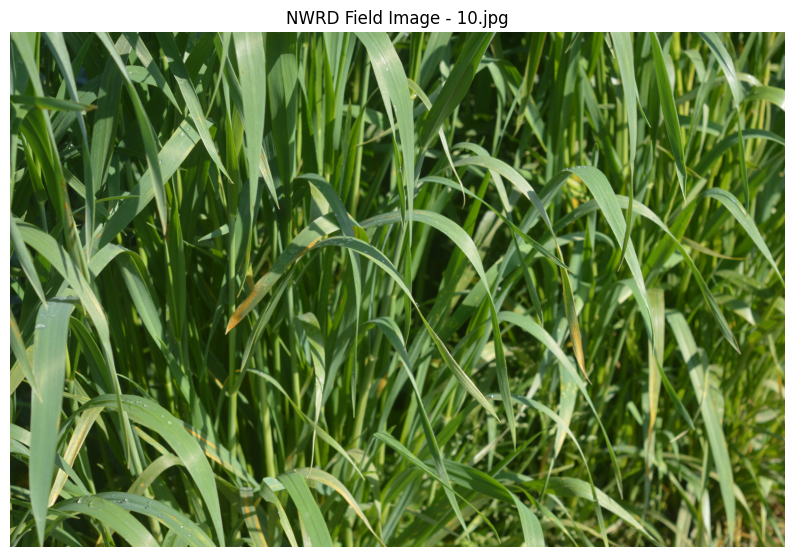

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.imshow(image_array)

plt.title(
    f"NWRD Field Image - {sample_image_path.name}"
)

plt.axis("off")

plt.show()

### Step 4.10: Visualize the Ground-Truth Rust Mask

The corresponding segmentation mask is displayed.

White pixels represent rust-affected regions, while black pixels represent pixels not annotated as rust.

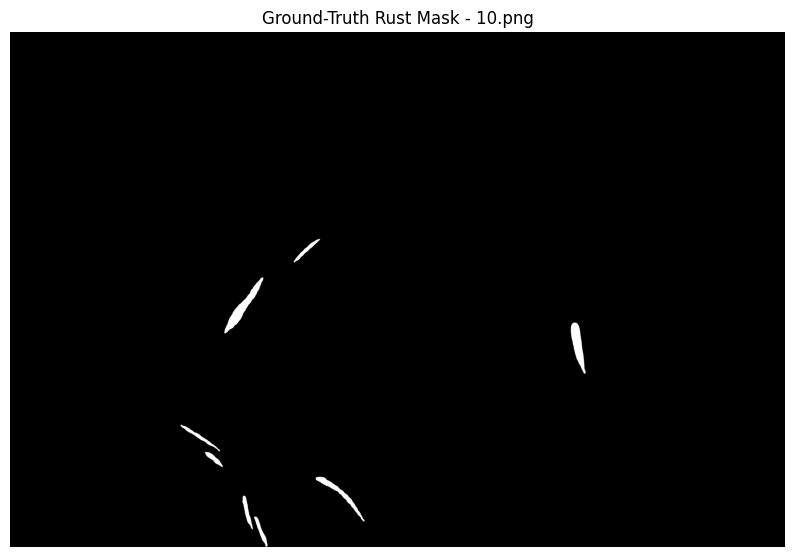

In [ ]:
plt.figure(figsize=(10, 7))

plt.imshow(
    mask_array,
    cmap="gray"
)

plt.title(
    f"Ground-Truth Rust Mask - {sample_mask_path.name}"
)

plt.axis("off")

plt.show()

### Step 4.11: Convert the NWRD Mask to Binary Format

The original segmentation mask contains pixel values of `0` and `255`.

For neural-network training, these values are converted into:

- `0.0` for non-rust pixels
- `1.0` for rust pixels

This creates a binary segmentation target.

In [ ]:
binary_mask = (
    mask_array > 0
).astype(np.float32)

print(
    "Binary mask unique values:",
    np.unique(binary_mask)
)

Binary mask unique values: [0. 1.]


### Step 4.12: Calculate Rust Pixel Coverage

The percentage of pixels annotated as rust is calculated for the selected field image.

This helps measure class imbalance between diseased and non-diseased pixels.

In [ ]:
rust_pixels = np.sum(binary_mask == 1)

total_pixels = binary_mask.size

rust_percentage = (
    rust_pixels / total_pixels
) * 100

print("Rust pixels:", rust_pixels)
print("Total pixels:", total_pixels)

print(
    f"Rust coverage: {rust_percentage:.4f}%"
)

Rust pixels: 97191
Total pixels: 24064000
Rust coverage: 0.4039%


### Step 4.13: Analyse Disease Coverage Across the NWRD Dataset

Rust coverage is calculated for every ground-truth mask.

This analysis helps identify:

- Images containing very small rust regions
- Images containing substantial disease
- Empty masks
- Class imbalance within the dataset

The results will guide patch extraction and model-training decisions.

In [ ]:
coverage_results = []

for image_path, mask_path in valid_pairs:

    mask = np.array(
        Image.open(mask_path)
    )

    binary = mask > 0

    damaged_pixels = np.count_nonzero(binary)

    total_pixels = binary.size

    percentage = (
        damaged_pixels / total_pixels
    ) * 100

    coverage_results.append(
        {
            "image": image_path.name,
            "mask": mask_path.name,
            "rust_percentage": percentage
        }
    )

print(
    "Images analysed:",
    len(coverage_results)
)

Images analysed: 90


### Step 4.14: Summarize Rust Coverage Distribution

Descriptive statistics are calculated for the percentage of rust pixels across the NWRD dataset.

These values provide an indication of the severity and distribution of disease annotations.

In [ ]:
coverage_values = np.array([
    item["rust_percentage"]
    for item in coverage_results
])

print(
    f"Minimum rust coverage: "
    f"{coverage_values.min():.4f}%"
)

print(
    f"Maximum rust coverage: "
    f"{coverage_values.max():.4f}%"
)

print(
    f"Mean rust coverage: "
    f"{coverage_values.mean():.4f}%"
)

print(
    f"Median rust coverage: "
    f"{np.median(coverage_values):.4f}%"
)

print(
    "Images with 0% rust:",
    np.sum(coverage_values == 0)
)

Minimum rust coverage: 0.0312%
Maximum rust coverage: 2.9885%
Mean rust coverage: 0.5701%
Median rust coverage: 0.3405%
Images with 0% rust: 0


### Step 4.15: Visualize Disease Coverage Distribution

A histogram is used to visualize how much of each NWRD image is occupied by rust.

This provides information about class imbalance and helps determine whether patch-based training is necessary.

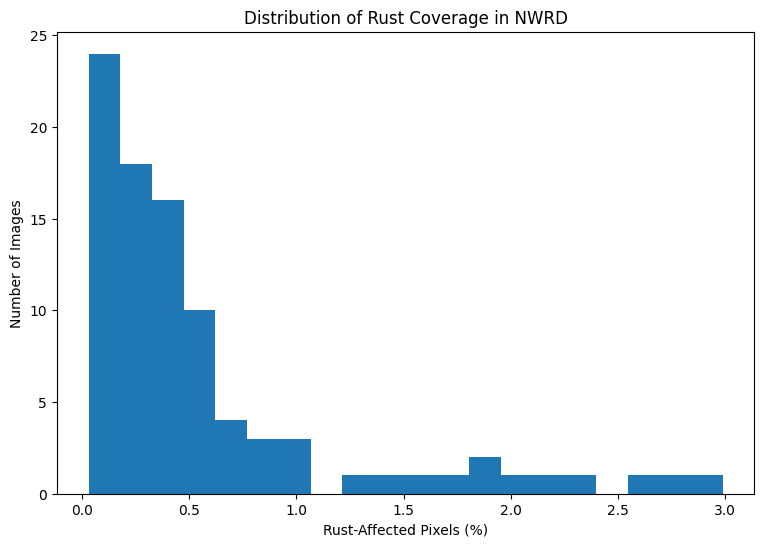

In [ ]:
plt.figure(figsize=(9, 6))

plt.hist(
    coverage_values,
    bins=20
)

plt.xlabel("Rust-Affected Pixels (%)")
plt.ylabel("Number of Images")

plt.title(
    "Distribution of Rust Coverage in NWRD"
)

plt.show()

## Step 5: Prepare NWRD for Patch-Based Segmentation Training

The NWRD images are very high resolution, while rust occupies only a very small percentage of each image.

The dataset analysis showed:

- Mean rust coverage: approximately 0.57%
- Median rust coverage: approximately 0.34%
- Maximum rust coverage: approximately 2.99%

Therefore, resizing the entire field image to a small neural-network input size could remove important rust details.

A patch-based training strategy is used instead.

Each high-resolution image is divided into smaller `512 × 512` regions.

Important:

- Original images are split into training and validation sets before patch extraction.
- The official NWRD test set will remain completely separate.
- This prevents data leakage between training and evaluation.

### Step 5.1: Inspect the Official Test Dataset

The official NWRD test set is kept untouched during model development.

It will only be used after training to measure the final model performance on unseen images.

In [ ]:
from pathlib import Path

NWRD_ROOT = Path("/content/drive/MyDrive/Agri-Vision/NWRD")

TEST_IMAGE_DIR = NWRD_ROOT / "test" / "images"
TEST_MASK_DIR = NWRD_ROOT / "test" / "masks"

print("Test image folder exists:", TEST_IMAGE_DIR.exists())
print("Test mask folder exists :", TEST_MASK_DIR.exists())

Test image folder exists: True
Test mask folder exists : True


In [ ]:
test_image_files = sorted([
    file
    for file in TEST_IMAGE_DIR.iterdir()
    if file.is_file()
    and file.suffix.lower() in IMAGE_EXTENSIONS
])

test_mask_files = sorted([
    file
    for file in TEST_MASK_DIR.iterdir()
    if file.is_file()
    and file.suffix.lower() in IMAGE_EXTENSIONS
])

print("Official test images:", len(test_image_files))
print("Official test masks :", len(test_mask_files))

Official test images: 10
Official test masks : 10


### Step 5.2: Split Training Images into Training and Validation Sets

The original NWRD training images are divided into training and validation groups before patch extraction.

Splitting at the original-image level prevents patches from the same image from appearing in both datasets.

An 80:20 training-validation split is used.

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

pair_coverages = []

for image_path, mask_path in valid_pairs:

    mask = np.array(
        Image.open(mask_path)
    )

    rust_percentage = (
        np.count_nonzero(mask)
        / mask.size
    ) * 100

    pair_coverages.append(rust_percentage)

pair_coverages = np.array(pair_coverages)

print("Total valid pairs:", len(valid_pairs))

Total valid pairs: 90


### Step 5.3: Stratify the Dataset by Rust Coverage

Images are grouped according to their rust coverage before splitting.

This helps maintain a similar disease-severity distribution in both the training and validation datasets.

In [ ]:
q1 = np.percentile(pair_coverages, 33)
q2 = np.percentile(pair_coverages, 66)

coverage_groups = np.digitize(
    pair_coverages,
    bins=[q1, q2]
)

print("33rd percentile:", q1)
print("66th percentile:", q2)

print(
    "Coverage groups:",
    np.bincount(coverage_groups)
)

33rd percentile: 0.21164172765158823
66th percentile: 0.4810671679790107
Coverage groups: [30 29 31]


In [ ]:
indices = np.arange(len(valid_pairs))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=coverage_groups
)

train_pairs = [
    valid_pairs[i]
    for i in train_indices
]

val_pairs = [
    valid_pairs[i]
    for i in val_indices
]

print("Training original images :", len(train_pairs))
print("Validation original images:", len(val_pairs))

Training original images : 72
Validation original images: 18


### Step 5.4: Verify Dataset Separation

The training and validation datasets are checked to confirm that no original image appears in both groups.

This prevents data leakage and ensures that validation metrics represent performance on unseen field images.

In [ ]:
train_names = {
    image_path.name
    for image_path, _ in train_pairs
}

val_names = {
    image_path.name
    for image_path, _ in val_pairs
}

overlap = train_names.intersection(val_names)

print("Images shared between train and validation:", len(overlap))

if overlap:
    print(overlap)
else:
    print("No data leakage detected.")

Images shared between train and validation: 0
No data leakage detected.


### Step 5.5: Configure Patch Extraction

Each high-resolution NWRD image will be divided into smaller patches.

A patch size of `512 × 512` pixels is selected.

This preserves small disease details while keeping the input size manageable for GPU training.

In [ ]:
PATCH_SIZE = 512
STRIDE = 512

print("Patch size:", PATCH_SIZE)
print("Stride:", STRIDE)

Patch size: 512
Stride: 512


### Step 5.6: Create Temporary Patch Storage

Generated image and mask patches are stored in the Colab runtime rather than Google Drive.

This avoids consuming unnecessary Google Drive storage.

The patch files will disappear automatically when the Colab runtime is deleted.

In [ ]:
from pathlib import Path
import shutil

PATCH_ROOT = Path("/content/nwrd_patches")

TRAIN_PATCH_IMAGE_DIR = PATCH_ROOT / "train" / "images"
TRAIN_PATCH_MASK_DIR = PATCH_ROOT / "train" / "masks"

VAL_PATCH_IMAGE_DIR = PATCH_ROOT / "validation" / "images"
VAL_PATCH_MASK_DIR = PATCH_ROOT / "validation" / "masks"

for folder in [
    TRAIN_PATCH_IMAGE_DIR,
    TRAIN_PATCH_MASK_DIR,
    VAL_PATCH_IMAGE_DIR,
    VAL_PATCH_MASK_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("Patch directories created.")

Patch directories created.


### Step 5.7: Generate Patch Coordinates

Patch coordinates are generated so that the entire high-resolution field image is covered.

Additional patches are positioned along the image boundaries when the dimensions are not exact multiples of the patch size.

In [ ]:
def generate_positions(length, patch_size, stride):

    positions = list(
        range(
            0,
            length - patch_size + 1,
            stride
        )
    )

    last_position = length - patch_size

    if positions[-1] != last_position:
        positions.append(last_position)

    return positions

In [ ]:
height, width = mask_array.shape

y_positions = generate_positions(
    height,
    PATCH_SIZE,
    STRIDE
)

x_positions = generate_positions(
    width,
    PATCH_SIZE,
    STRIDE
)

print("Image size:", width, "x", height)

print("Vertical patch positions:", len(y_positions))
print("Horizontal patch positions:", len(x_positions))

print(
    "Possible patches per image:",
    len(y_positions) * len(x_positions)
)

Image size: 6016 x 4000
Vertical patch positions: 8
Horizontal patch positions: 12
Possible patches per image: 96


### Step 5.8: Define Disease-Positive Patches

A patch is considered disease-positive when it contains at least 64 rust pixels.

This low threshold allows small visible rust lesions to remain part of the training dataset.

Background-only patches are also retained, but their number will be controlled to prevent severe class imbalance.

In [ ]:
MIN_RUST_PIXELS = 64

print(
    "Minimum rust pixels for positive patch:",
    MIN_RUST_PIXELS
)

percentage = (
    MIN_RUST_PIXELS
    / (PATCH_SIZE * PATCH_SIZE)
) * 100

print(
    f"Minimum patch disease coverage: "
    f"{percentage:.4f}%"
)

Minimum rust pixels for positive patch: 64
Minimum patch disease coverage: 0.0244%


## Step 6: Analyse Patch-Level Disease Distribution

The high-resolution NWRD images can produce many `512 × 512` patches.

However, because rust occupies only a small fraction of each original image, many patches may contain no disease.

Before generating patch files, the masks are scanned to determine:

- How many patches contain rust
- How many patches contain no rust
- How much rust is present inside positive patches
- An appropriate threshold for selecting disease-positive patches

This avoids creating thousands of unnecessary background patches.

In [ ]:
import numpy as np
from PIL import Image

PATCH_SIZE = 512
STRIDE = 512


def generate_positions(length, patch_size, stride):
    positions = list(
        range(
            0,
            length - patch_size + 1,
            stride
        )
    )

    last_position = length - patch_size

    if not positions:
        positions = [0]

    elif positions[-1] != last_position:
        positions.append(last_position)

    return positions

### Step 6.1: Compare Disease-Patch Thresholds

Different minimum rust-pixel thresholds are evaluated.

A very small threshold preserves tiny lesions, while a larger threshold reduces patches containing only negligible disease annotations.

The following thresholds are compared:

- 1 rust pixel
- 16 rust pixels
- 64 rust pixels
- 256 rust pixels

In [ ]:
THRESHOLDS = [1, 16, 64, 256]


def analyse_patch_distribution(pairs):

    results = {
        threshold: {
            "positive": 0,
            "negative": 0
        }
        for threshold in THRESHOLDS
    }

    total_patches = 0
    rust_pixel_counts = []

    for image_path, mask_path in pairs:

        mask = np.array(
            Image.open(mask_path).convert("L")
        )

        height, width = mask.shape

        y_positions = generate_positions(
            height,
            PATCH_SIZE,
            STRIDE
        )

        x_positions = generate_positions(
            width,
            PATCH_SIZE,
            STRIDE
        )

        for y in y_positions:
            for x in x_positions:

                patch = mask[
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ]

                rust_pixels = np.count_nonzero(
                    patch > 0
                )

                rust_pixel_counts.append(
                    rust_pixels
                )

                total_patches += 1

                for threshold in THRESHOLDS:

                    if rust_pixels >= threshold:
                        results[threshold]["positive"] += 1

                    else:
                        results[threshold]["negative"] += 1

    return (
        total_patches,
        results,
        np.array(rust_pixel_counts)
    )

In [ ]:
train_patch_count, train_distribution, train_rust_counts = (
    analyse_patch_distribution(train_pairs)
)

print("Total possible training patches:", train_patch_count)

print("\nPatch distribution:")

for threshold in THRESHOLDS:

    positive = train_distribution[threshold]["positive"]
    negative = train_distribution[threshold]["negative"]

    positive_pct = (
        positive / train_patch_count
    ) * 100

    print(
        f"\nThreshold >= {threshold} rust pixels"
    )

    print("Positive patches:", positive)
    print("Negative patches:", negative)

    print(
        f"Positive percentage: {positive_pct:.2f}%"
    )

Total possible training patches: 5214

Patch distribution:

Threshold >= 1 rust pixels
Positive patches: 1255
Negative patches: 3959
Positive percentage: 24.07%

Threshold >= 16 rust pixels
Positive patches: 1069
Negative patches: 4145
Positive percentage: 20.50%

Threshold >= 64 rust pixels
Positive patches: 1007
Negative patches: 4207
Positive percentage: 19.31%

Threshold >= 256 rust pixels
Positive patches: 956
Negative patches: 4258
Positive percentage: 18.34%


### Step 6.2: Identify Completely Disease-Free Patches

Patches containing zero annotated rust pixels are counted.

This shows how strongly the patch dataset is dominated by healthy or background regions.

In [ ]:
empty_patches = np.sum(
    train_rust_counts == 0
)

rust_patches = np.sum(
    train_rust_counts > 0
)

print("Completely empty patches:", empty_patches)
print("Patches containing rust :", rust_patches)

print(
    f"\nEmpty patch percentage: "
    f"{(empty_patches / train_patch_count) * 100:.2f}%"
)

print(
    f"Rust patch percentage: "
    f"{(rust_patches / train_patch_count) * 100:.2f}%"
)

Completely empty patches: 3959
Patches containing rust : 1255

Empty patch percentage: 75.93%
Rust patch percentage: 24.07%


### Step 6.3: Analyse Rust Pixels Within Positive Patches

Only patches containing at least one rust pixel are analysed.

The distribution helps determine whether most positive patches contain meaningful disease regions or only a few isolated annotated pixels.

In [ ]:
positive_rust_counts = train_rust_counts[
    train_rust_counts > 0
]

print(
    "Positive patches:",
    len(positive_rust_counts)
)

if len(positive_rust_counts) > 0:

    print(
        "Minimum rust pixels:",
        positive_rust_counts.min()
    )

    print(
        "Maximum rust pixels:",
        positive_rust_counts.max()
    )

    print(
        "Mean rust pixels:",
        positive_rust_counts.mean()
    )

    print(
        "Median rust pixels:",
        np.median(positive_rust_counts)
    )

Positive patches: 1255
Minimum rust pixels: 1
Maximum rust pixels: 89343
Mean rust pixels: 6172.768924302789
Median rust pixels: 2794.0


### Step 6.4: Convert Patch Thresholds to Disease Coverage

The rust-pixel thresholds are converted into percentages of a `512 × 512` patch.

This makes the threshold easier to interpret.

In [ ]:
TOTAL_PATCH_PIXELS = PATCH_SIZE * PATCH_SIZE

for threshold in THRESHOLDS:

    percentage = (
        threshold / TOTAL_PATCH_PIXELS
    ) * 100

    print(
        f"{threshold:3d} pixels"
        f" = {percentage:.5f}% of patch"
    )

  1 pixels = 0.00038% of patch
 16 pixels = 0.00610% of patch
 64 pixels = 0.02441% of patch
256 pixels = 0.09766% of patch


### Step 6.5: Define the Final Patch Selection Strategy

The NWRD patch analysis showed strong class imbalance:

- Approximately 76% of patches contain no rust.
- Approximately 24% contain at least one rust pixel.
- 1,007 patches contain at least 64 rust pixels.

For model training, a patch is considered disease-positive when it contains at least 64 rust pixels.

Training strategy:

- Positive patch: 64 or more rust pixels
- Negative patch: exactly 0 rust pixels
- Patches containing 1 to 63 rust pixels are excluded from training
- Background patches are randomly sampled to approximately 1.25 times the number of positive patches

This reduces class imbalance while preserving meaningful small rust regions.

In [ ]:
MIN_RUST_PIXELS = 64
NEGATIVE_RATIO = 1.25
SEED = 42

print("Positive threshold:", MIN_RUST_PIXELS)
print("Negative ratio:", NEGATIVE_RATIO)

Positive threshold: 64
Negative ratio: 1.25


### Step 6.6: Build Training Patch Metadata

Metadata is created for every possible training patch before image files are generated.

Each patch record contains:

- Original image path
- Original mask path
- Patch coordinates
- Number of rust pixels
- Patch category

This allows balanced patch selection without unnecessarily storing thousands of background patches.

In [ ]:
import numpy as np
from PIL import Image

train_patch_records = []

for image_path, mask_path in train_pairs:

    mask = np.array(
        Image.open(mask_path).convert("L")
    )

    height, width = mask.shape

    y_positions = generate_positions(
        height,
        PATCH_SIZE,
        STRIDE
    )

    x_positions = generate_positions(
        width,
        PATCH_SIZE,
        STRIDE
    )

    for y in y_positions:
        for x in x_positions:

            mask_patch = mask[
                y:y + PATCH_SIZE,
                x:x + PATCH_SIZE
            ]

            rust_pixels = np.count_nonzero(
                mask_patch > 0
            )

            if rust_pixels >= MIN_RUST_PIXELS:
                category = "positive"

            elif rust_pixels == 0:
                category = "negative"

            else:
                category = "weak"

            train_patch_records.append(
                {
                    "image_path": image_path,
                    "mask_path": mask_path,
                    "x": x,
                    "y": y,
                    "rust_pixels": rust_pixels,
                    "category": category
                }
            )

print(
    "Total patch records:",
    len(train_patch_records)
)

Total patch records: 5214


### Step 6.7: Inspect Final Patch Categories

The patch records are grouped into:

- Positive disease patches
- Completely disease-free patches
- Weak patches containing fewer than 64 annotated rust pixels

Weak patches are not treated as negative because they contain real disease annotations.

In [ ]:
positive_records = [
    record
    for record in train_patch_records
    if record["category"] == "positive"
]

negative_records = [
    record
    for record in train_patch_records
    if record["category"] == "negative"
]

weak_records = [
    record
    for record in train_patch_records
    if record["category"] == "weak"
]

print("Positive patches:", len(positive_records))
print("Negative patches:", len(negative_records))
print("Weak patches:", len(weak_records))

Positive patches: 1007
Negative patches: 3959
Weak patches: 248


### Step 6.8: Balance Positive and Negative Training Patches

Using all background patches would cause the model to become biased toward predicting background.

A subset of disease-free patches is therefore selected randomly.

Approximately 1.25 background patches are used for every positive disease patch.

In [ ]:
import random

random.seed(SEED)

target_negative_count = int(
    len(positive_records) * NEGATIVE_RATIO
)

target_negative_count = min(
    target_negative_count,
    len(negative_records)
)

selected_negative_records = random.sample(
    negative_records,
    target_negative_count
)

selected_train_records = (
    positive_records
    + selected_negative_records
)

random.shuffle(selected_train_records)

print(
    "Selected positive patches:",
    len(positive_records)
)

print(
    "Selected negative patches:",
    len(selected_negative_records)
)

print(
    "Final training patches:",
    len(selected_train_records)
)

Selected positive patches: 1007
Selected negative patches: 1258
Final training patches: 2265


### Step 6.9: Create Temporary Patch Directories

Selected training patches are stored in the Colab temporary storage directory.

Google Drive is not used for patch storage, reducing Drive space usage.

Only the final trained model and evaluation results will later be saved to Google Drive.

In [ ]:
from pathlib import Path
import shutil

PATCH_ROOT = Path("/content/nwrd_patches")

TRAIN_PATCH_IMAGE_DIR = (
    PATCH_ROOT / "train" / "images"
)

TRAIN_PATCH_MASK_DIR = (
    PATCH_ROOT / "train" / "masks"
)

if PATCH_ROOT.exists():
    shutil.rmtree(PATCH_ROOT)

TRAIN_PATCH_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TRAIN_PATCH_MASK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Patch root:", PATCH_ROOT)
print("Training image folder:", TRAIN_PATCH_IMAGE_DIR)
print("Training mask folder:", TRAIN_PATCH_MASK_DIR)

Patch root: /content/nwrd_patches
Training image folder: /content/nwrd_patches/train/images
Training mask folder: /content/nwrd_patches/train/masks


### Step 6.10: Generate Training Patches Efficiently

The original high-resolution images are stored in Google Drive.

Opening the same large image separately for every patch causes significant I/O delay.

To improve performance, patch records are grouped by their original image. Each high-resolution image and mask are opened only once, and all required patches are extracted during the same operation.

The generated patches are stored temporarily in `/content`.

In [ ]:
import shutil
from pathlib import Path

PATCH_ROOT = Path("/content/nwrd_patches")

TRAIN_PATCH_IMAGE_DIR = PATCH_ROOT / "train" / "images"
TRAIN_PATCH_MASK_DIR = PATCH_ROOT / "train" / "masks"

if TRAIN_PATCH_IMAGE_DIR.exists():
    shutil.rmtree(TRAIN_PATCH_IMAGE_DIR)

if TRAIN_PATCH_MASK_DIR.exists():
    shutil.rmtree(TRAIN_PATCH_MASK_DIR)

TRAIN_PATCH_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TRAIN_PATCH_MASK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Old partial patches removed.")
print("Clean patch folders created.")

Old partial patches removed.
Clean patch folders created.


In [ ]:
from collections import defaultdict

records_by_image = defaultdict(list)

for index, record in enumerate(selected_train_records):

    image_key = str(record["image_path"])

    records_by_image[image_key].append(
        (index, record)
    )

print(
    "Original images that will be processed:",
    len(records_by_image)
)

print(
    "Total selected patches:",
    len(selected_train_records)
)

Original images that will be processed: 72
Total selected patches: 2265


In [ ]:
from PIL import Image
import numpy as np
import time

start_time = time.time()

generated_count = 0

total_source_images = len(records_by_image)

for source_number, (
    image_key,
    grouped_records
) in enumerate(
    records_by_image.items(),
    start=1
):

    # All records in this group use the same source image
    first_record = grouped_records[0][1]

    image_path = first_record["image_path"]
    mask_path = first_record["mask_path"]

    # Open the huge image only once
    with Image.open(image_path) as img:
        image = img.convert("RGB")

        with Image.open(mask_path) as msk:
            mask = msk.convert("L")

            for index, record in grouped_records:

                x = record["x"]
                y = record["y"]

                box = (
                    x,
                    y,
                    x + PATCH_SIZE,
                    y + PATCH_SIZE
                )

                image_patch = image.crop(box)
                mask_patch = mask.crop(box)

                # Convert mask to binary 0 / 255
                mask_array = np.array(mask_patch)

                binary_mask = (
                    mask_array > 0
                ).astype(np.uint8) * 255

                binary_mask_image = Image.fromarray(
                    binary_mask
                )

                filename = f"patch_{index:05d}"

                image_patch.save(
                    TRAIN_PATCH_IMAGE_DIR /
                    f"{filename}.jpg",
                    quality=90
                )

                binary_mask_image.save(
                    TRAIN_PATCH_MASK_DIR /
                    f"{filename}.png"
                )

                generated_count += 1

    print(
        f"Processed source image "
        f"{source_number}/{total_source_images}"
        f" | Total patches: {generated_count}"
    )

elapsed = time.time() - start_time

print("\nPatch extraction completed.")

print(
    "Generated patches:",
    generated_count
)

print(
    f"Elapsed time: {elapsed:.1f} seconds"
)

Processed source image 1/72 | Total patches: 19
Processed source image 2/72 | Total patches: 45
Processed source image 3/72 | Total patches: 78
Processed source image 4/72 | Total patches: 99
Processed source image 5/72 | Total patches: 141
Processed source image 6/72 | Total patches: 173
Processed source image 7/72 | Total patches: 208
Processed source image 8/72 | Total patches: 238
Processed source image 9/72 | Total patches: 275
Processed source image 10/72 | Total patches: 293
Processed source image 11/72 | Total patches: 338
Processed source image 12/72 | Total patches: 363
Processed source image 13/72 | Total patches: 388
Processed source image 14/72 | Total patches: 432
Processed source image 15/72 | Total patches: 471
Processed source image 16/72 | Total patches: 506
Processed source image 17/72 | Total patches: 536
Processed source image 18/72 | Total patches: 569
Processed source image 19/72 | Total patches: 634
Processed source image 20/72 | Total patches: 668
Processed sou

### Step 6.11: Verify Generated Training Patches

The number of generated image patches and segmentation masks is checked to ensure that every selected training patch has a corresponding mask.

In [ ]:
generated_images = sorted(
    TRAIN_PATCH_IMAGE_DIR.glob("*.jpg")
)

generated_masks = sorted(
    TRAIN_PATCH_MASK_DIR.glob("*.png")
)

print(
    "Expected training patches:",
    len(selected_train_records)
)

print(
    "Generated training images:",
    len(generated_images)
)

print(
    "Generated training masks:",
    len(generated_masks)
)

print(
    "Counts match:",
    len(generated_images)
    == len(generated_masks)
    == len(selected_train_records)
)

Expected training patches: 2265
Generated training images: 2265
Generated training masks: 2265
Counts match: True


### Step 6.12: Visualize a Positive Training Patch

A disease-positive image patch and its corresponding ground-truth mask are displayed.

This confirms that:

- Image and mask patches are correctly aligned
- Rust regions were preserved during cropping
- The mask remains binary after patch extraction

In [ ]:
positive_indices = [
    i
    for i, record in enumerate(selected_train_records)
    if record["category"] == "positive"
]

sample_index = positive_indices[0]

sample_image_path = (
    TRAIN_PATCH_IMAGE_DIR /
    f"patch_{sample_index:05d}.jpg"
)

sample_mask_path = (
    TRAIN_PATCH_MASK_DIR /
    f"patch_{sample_index:05d}.png"
)

sample_patch_image = Image.open(sample_image_path)
sample_patch_mask = Image.open(sample_mask_path)

print("Image:", sample_image_path.name)
print("Mask :", sample_mask_path.name)

print(
    "Rust pixels:",
    selected_train_records[sample_index]["rust_pixels"]
)

print(
    "Mask values:",
    np.unique(np.array(sample_patch_mask))
)

Image: patch_00003.jpg
Mask : patch_00003.png
Rust pixels: 13917
Mask values: [  0 255]


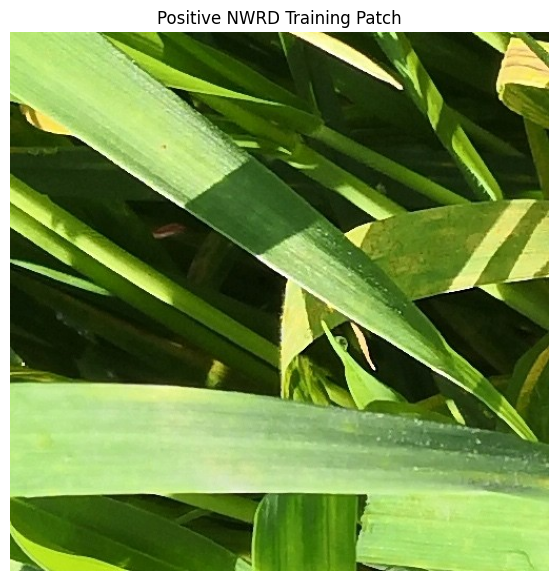

In [ ]:
plt.figure(figsize=(7, 7))

plt.imshow(sample_patch_image)
plt.title("Positive NWRD Training Patch")

plt.axis("off")
plt.show()

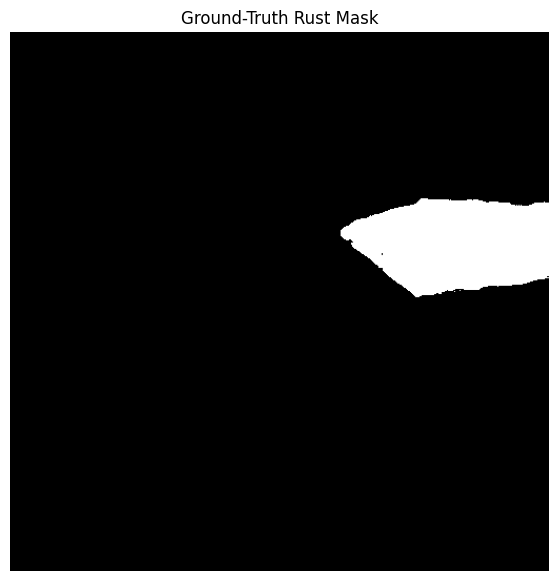

In [ ]:
plt.figure(figsize=(7, 7))

plt.imshow(
    sample_patch_mask,
    cmap="gray"
)

plt.title("Ground-Truth Rust Mask")

plt.axis("off")
plt.show()

## Step 7: Prepare the Validation Dataset

The validation dataset is generated from the 18 original validation images.

Unlike the training dataset, validation patches are not balanced or filtered.

All available patches are retained so that validation metrics reflect realistic disease distribution.

In [ ]:
VAL_PATCH_IMAGE_DIR = (
    PATCH_ROOT / "validation" / "images"
)

VAL_PATCH_MASK_DIR = (
    PATCH_ROOT / "validation" / "masks"
)

VAL_PATCH_IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

VAL_PATCH_MASK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Validation directories created.")

Validation directories created.


### Step 7.2: Generate Validation Image-Mask Patches

Each original validation image is opened once.

All `512 × 512` patches are extracted without disease-based sampling.

This provides an unbiased validation dataset for model selection.

In [ ]:
import time

start_time = time.time()

validation_patch_count = 0

for source_number, (
    image_path,
    mask_path
) in enumerate(
    val_pairs,
    start=1
):

    with Image.open(image_path) as img:
        image = img.convert("RGB")

        with Image.open(mask_path) as msk:
            mask = msk.convert("L")

            width, height = image.size

            y_positions = generate_positions(
                height,
                PATCH_SIZE,
                STRIDE
            )

            x_positions = generate_positions(
                width,
                PATCH_SIZE,
                STRIDE
            )

            for y in y_positions:
                for x in x_positions:

                    box = (
                        x,
                        y,
                        x + PATCH_SIZE,
                        y + PATCH_SIZE
                    )

                    image_patch = image.crop(box)
                    mask_patch = mask.crop(box)

                    mask_array = np.array(mask_patch)

                    binary_mask = (
                        mask_array > 0
                    ).astype(np.uint8) * 255

                    binary_mask_image = Image.fromarray(
                        binary_mask
                    )

                    filename = (
                        f"{image_path.stem}"
                        f"_y{y}_x{x}"
                    )

                    image_patch.save(
                        VAL_PATCH_IMAGE_DIR /
                        f"{filename}.jpg",
                        quality=90
                    )

                    binary_mask_image.save(
                        VAL_PATCH_MASK_DIR /
                        f"{filename}.png"
                    )

                    validation_patch_count += 1

    print(
        f"Processed validation image "
        f"{source_number}/{len(val_pairs)}"
        f" | Total patches: "
        f"{validation_patch_count}"
    )

elapsed = time.time() - start_time

print("\nValidation extraction complete.")

print(
    "Validation patches:",
    validation_patch_count
)

print(
    f"Elapsed time: {elapsed:.1f} seconds"
)

Processed validation image 1/18 | Total patches: 63
Processed validation image 2/18 | Total patches: 119
Processed validation image 3/18 | Total patches: 182
Processed validation image 4/18 | Total patches: 278
Processed validation image 5/18 | Total patches: 341
Processed validation image 6/18 | Total patches: 404
Processed validation image 7/18 | Total patches: 467
Processed validation image 8/18 | Total patches: 530
Processed validation image 9/18 | Total patches: 593
Processed validation image 10/18 | Total patches: 689
Processed validation image 11/18 | Total patches: 785
Processed validation image 12/18 | Total patches: 848
Processed validation image 13/18 | Total patches: 911
Processed validation image 14/18 | Total patches: 974
Processed validation image 15/18 | Total patches: 1028
Processed validation image 16/18 | Total patches: 1124
Processed validation image 17/18 | Total patches: 1187
Processed validation image 18/18 | Total patches: 1283

Validation extraction complete.
V

### Step 7.3: Verify Validation Image-Mask Pairs

The number of generated validation images and masks is checked.

Every validation image patch must have exactly one corresponding segmentation mask.

In [ ]:
val_generated_images = sorted(
    VAL_PATCH_IMAGE_DIR.glob("*.jpg")
)

val_generated_masks = sorted(
    VAL_PATCH_MASK_DIR.glob("*.png")
)

print(
    "Validation images:",
    len(val_generated_images)
)

print(
    "Validation masks:",
    len(val_generated_masks)
)

print(
    "Counts match:",
    len(val_generated_images)
    == len(val_generated_masks)
)

Validation images: 1283
Validation masks: 1283
Counts match: True


### Step 7.4: Analyse Validation Patch Distribution

The validation masks are examined to determine how many patches contain visible rust.

No patches are removed based on these results.

In [ ]:
val_positive = 0
val_empty = 0
val_weak = 0

for mask_path in val_generated_masks:

    mask = np.array(
        Image.open(mask_path)
    )

    rust_pixels = np.count_nonzero(
        mask > 0
    )

    if rust_pixels >= MIN_RUST_PIXELS:
        val_positive += 1

    elif rust_pixels == 0:
        val_empty += 1

    else:
        val_weak += 1

print("Validation positive patches:", val_positive)
print("Validation empty patches   :", val_empty)
print("Validation weak patches    :", val_weak)

print(
    "Total:",
    val_positive +
    val_empty +
    val_weak
)

Validation positive patches: 213
Validation empty patches   : 992
Validation weak patches    : 78
Total: 1283


### Step 7.5: Verify Image-Mask Alignment

The ground-truth mask is overlaid on the original image.

This confirms that the annotated disease region is spatially aligned with the corresponding wheat leaf.

Correct image-mask alignment is essential before training the segmentation model.

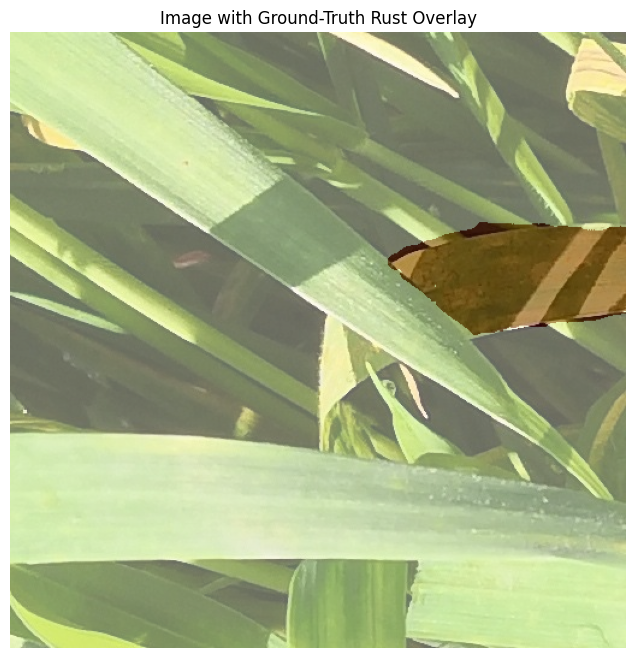

In [ ]:
image_np = np.array(sample_patch_image)
mask_np = np.array(sample_patch_mask)

plt.figure(figsize=(8, 8))

plt.imshow(image_np)

plt.imshow(
    mask_np,
    cmap="Reds",
    alpha=0.4
)

plt.title("Image with Ground-Truth Rust Overlay")
plt.axis("off")
plt.show()

## Step 8: Create the TensorFlow Input Pipeline

The generated image and mask patches are loaded using TensorFlow.

Each image is:

- Decoded as RGB
- Converted to floating-point format
- Normalized

Each segmentation mask is:

- Loaded as a single-channel grayscale image
- Converted into a binary mask containing `0` and `1`

The TensorFlow `tf.data` pipeline is used for efficient GPU training.

In [ ]:
import tensorflow as tf

IMG_HEIGHT = 512
IMG_WIDTH = 512
BATCH_SIZE = 4

AUTOTUNE = tf.data.AUTOTUNE

print("Image size:", IMG_HEIGHT, "x", IMG_WIDTH)
print("Batch size:", BATCH_SIZE)

Image size: 512 x 512
Batch size: 4


### Step 8.1: Prepare Training Image and Mask Paths

The generated training image and mask filenames are sorted so that each image corresponds to the correct segmentation mask.

In [ ]:
train_image_paths = sorted(
    [
        str(path)
        for path in TRAIN_PATCH_IMAGE_DIR.glob("*.jpg")
    ]
)

train_mask_paths = sorted(
    [
        str(path)
        for path in TRAIN_PATCH_MASK_DIR.glob("*.png")
    ]
)

print("Training images:", len(train_image_paths))
print("Training masks :", len(train_mask_paths))

assert len(train_image_paths) == len(train_mask_paths)

print("Training paths verified.")

Training images: 2265
Training masks : 2265
Training paths verified.


### Step 8.2: Prepare Validation Image and Mask Paths

All validation image-mask pairs are retained without balancing or disease-based filtering.

In [ ]:
val_image_paths = sorted(
    [
        str(path)
        for path in VAL_PATCH_IMAGE_DIR.glob("*.jpg")
    ]
)

val_mask_paths = sorted(
    [
        str(path)
        for path in VAL_PATCH_MASK_DIR.glob("*.png")
    ]
)

print("Validation images:", len(val_image_paths))
print("Validation masks :", len(val_mask_paths))

assert len(val_image_paths) == len(val_mask_paths)

print("Validation paths verified.")

Validation images: 1283
Validation masks : 1283
Validation paths verified.


### Step 8.3: Define Image and Mask Loading

A preprocessing function loads each image-mask pair.

Images are normalized to the range `0–1`.

Masks are converted from the original `0/255` representation into binary `0/1` segmentation targets.

In [ ]:
def load_image_mask(image_path, mask_path):

    # Read image
    image = tf.io.read_file(image_path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.convert_image_dtype(
        image,
        tf.float32
    )

    # Read mask
    mask = tf.io.read_file(mask_path)

    mask = tf.image.decode_png(
        mask,
        channels=1
    )

    mask = tf.cast(
        mask > 0,
        tf.float32
    )

    # Ensure dimensions
    image = tf.ensure_shape(
        image,
        [IMG_HEIGHT, IMG_WIDTH, 3]
    )

    mask = tf.ensure_shape(
        mask,
        [IMG_HEIGHT, IMG_WIDTH, 1]
    )

    return image, mask

### Step 8.4: Create the Training Dataset

Training image and mask paths are converted into a TensorFlow dataset.

The dataset is shuffled during training so the model sees the patches in a different order across epochs.

In [ ]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        train_image_paths,
        train_mask_paths
    )
)

train_dataset = train_dataset.map(
    load_image_mask,
    num_parallel_calls=AUTOTUNE
)

train_dataset = train_dataset.shuffle(
    buffer_size=len(train_image_paths),
    seed=42,
    reshuffle_each_iteration=True
)

print(train_dataset)

<_ShuffleDataset element_spec=(TensorSpec(shape=(512, 512, 3), dtype=tf.float32, name=None), TensorSpec(shape=(512, 512, 1), dtype=tf.float32, name=None))>


### Step 8.5: Create the Validation Dataset

The validation dataset uses the same preprocessing as training.

Validation images are not shuffled because they are only used to measure model performance.

In [ ]:
val_dataset = tf.data.Dataset.from_tensor_slices(
    (
        val_image_paths,
        val_mask_paths
    )
)

val_dataset = val_dataset.map(
    load_image_mask,
    num_parallel_calls=AUTOTUNE
)

print(val_dataset)

<_ParallelMapDataset element_spec=(TensorSpec(shape=(512, 512, 3), dtype=tf.float32, name=None), TensorSpec(shape=(512, 512, 1), dtype=tf.float32, name=None))>


### Step 8.6: Verify Tensor Shapes and Values

One processed image-mask pair is inspected to confirm:

- Image shape is `512 × 512 × 3`
- Mask shape is `512 × 512 × 1`
- Image values are normalized
- Mask contains only binary values

In [ ]:
for image, mask in train_dataset.take(1):

    print("Image shape:", image.shape)
    print("Mask shape :", mask.shape)

    print(
        "Image minimum:",
        tf.reduce_min(image).numpy()
    )

    print(
        "Image maximum:",
        tf.reduce_max(image).numpy()
    )

    print(
        "Mask values:",
        np.unique(mask.numpy())
    )

Image shape: (512, 512, 3)
Mask shape : (512, 512, 1)
Image minimum: 0.0
Image maximum: 1.0
Mask values: [0.]


### Step 8.7: Apply Segmentation Data Augmentation

Data augmentation increases the diversity of the training dataset.

Geometric transformations must be applied identically to both the input image and segmentation mask.

The following augmentations are used:

- Random horizontal flip
- Random vertical flip
- Random 90-degree rotation

These transformations preserve the spatial relationship between the wheat image and its ground-truth mask.

In [ ]:
def augment_image_mask(image, mask):

    # Horizontal flip
    random_value = tf.random.uniform(())

    if random_value > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)

    # Vertical flip
    random_value = tf.random.uniform(())

    if random_value > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)

    # Random 90-degree rotation
    k = tf.random.uniform(
        shape=[],
        minval=0,
        maxval=4,
        dtype=tf.int32
    )

    image = tf.image.rot90(
        image,
        k
    )

    mask = tf.image.rot90(
        mask,
        k
    )

    return image, mask

### Step 8.8: Finalize the TensorFlow Data Pipeline

Data augmentation is applied only to the training dataset.

Both training and validation datasets are batched and prefetched to improve GPU utilization.

In [ ]:
train_dataset_final = train_dataset.map(
    augment_image_mask,
    num_parallel_calls=AUTOTUNE
)

train_dataset_final = train_dataset_final.batch(
    BATCH_SIZE
)

train_dataset_final = train_dataset_final.prefetch(
    AUTOTUNE
)


val_dataset_final = val_dataset.batch(
    BATCH_SIZE
)

val_dataset_final = val_dataset_final.prefetch(
    AUTOTUNE
)

print("Training and validation pipelines ready.")

Training and validation pipelines ready.


### Step 8.9: Verify a Training Batch

A batch is inspected before model construction to ensure that the TensorFlow input pipeline produces correctly shaped images and masks.


In [ ]:
for images, masks in train_dataset_final.take(1):

    print("Image batch shape:", images.shape)
    print("Mask batch shape :", masks.shape)

    print(
        "Mask values:",
        np.unique(masks.numpy())
    )

NameError: name 'train_dataset_final' is not defined

## Step 8: Recover After Colab RAM Restart

The previous runtime exceeded available RAM and restarted.

The TensorFlow input pipeline is recreated using conservative memory settings:

- Batch size = 2
- Limited parallel loading
- Prefetch = 1 batch
- No dataset cache
- No AUTOTUNE prefetch

In [ ]:
import gc
import numpy as np
import tensorflow as tf
from pathlib import Path

tf.keras.backend.clear_session()
gc.collect()

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
PATCH_ROOT = Path("/content/nwrd_patches")

TRAIN_PATCH_IMAGE_DIR = PATCH_ROOT / "train" / "images"
TRAIN_PATCH_MASK_DIR = PATCH_ROOT / "train" / "masks"

VAL_PATCH_IMAGE_DIR = PATCH_ROOT / "validation" / "images"
VAL_PATCH_MASK_DIR = PATCH_ROOT / "validation" / "masks"

print("Train images folder:", TRAIN_PATCH_IMAGE_DIR.exists())
print("Train masks folder :", TRAIN_PATCH_MASK_DIR.exists())
print("Val images folder  :", VAL_PATCH_IMAGE_DIR.exists())
print("Val masks folder   :", VAL_PATCH_MASK_DIR.exists())

Train images folder: True
Train masks folder : True
Val images folder  : True
Val masks folder   : True


In [ ]:
print(
    "Training images:",
    len(list(TRAIN_PATCH_IMAGE_DIR.glob("*.jpg")))
)

print(
    "Training masks:",
    len(list(TRAIN_PATCH_MASK_DIR.glob("*.png")))
)

print(
    "Validation images:",
    len(list(VAL_PATCH_IMAGE_DIR.glob("*.jpg")))
)

print(
    "Validation masks:",
    len(list(VAL_PATCH_MASK_DIR.glob("*.png")))
)

Training images: 2265
Training masks: 2265
Validation images: 1283
Validation masks: 1283


### Step 8.1: Restore Training and Validation File Paths

Only file paths are stored in memory. Images and masks are loaded from disk batch-by-batch during training.

In [ ]:
train_image_paths = sorted(
    str(path)
    for path in TRAIN_PATCH_IMAGE_DIR.glob("*.jpg")
)

train_mask_paths = sorted(
    str(path)
    for path in TRAIN_PATCH_MASK_DIR.glob("*.png")
)

val_image_paths = sorted(
    str(path)
    for path in VAL_PATCH_IMAGE_DIR.glob("*.jpg")
)

val_mask_paths = sorted(
    str(path)
    for path in VAL_PATCH_MASK_DIR.glob("*.png")
)

print("Training images:", len(train_image_paths))
print("Training masks :", len(train_mask_paths))

print("Validation images:", len(val_image_paths))
print("Validation masks :", len(val_mask_paths))

assert len(train_image_paths) == len(train_mask_paths)
assert len(val_image_paths) == len(val_mask_paths)

Training images: 2265
Training masks : 2265
Validation images: 1283
Validation masks : 1283


### Step 8.2: Configure Memory-Efficient Data Loading

Conservative data-loading settings are used to avoid another Colab RAM crash.

In [ ]:
IMG_HEIGHT = 512
IMG_WIDTH = 512

BATCH_SIZE = 2

NUM_PARALLEL_CALLS = 2
PREFETCH_SIZE = 1

print("Batch size:", BATCH_SIZE)
print("Parallel calls:", NUM_PARALLEL_CALLS)
print("Prefetch batches:", PREFETCH_SIZE)

Batch size: 2
Parallel calls: 2
Prefetch batches: 1


In [ ]:
def load_image_mask(image_path, mask_path):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.convert_image_dtype(
        image,
        tf.float32
    )

    mask = tf.io.read_file(mask_path)

    mask = tf.image.decode_png(
        mask,
        channels=1
    )

    mask = tf.cast(
        mask > 0,
        tf.float32
    )

    image.set_shape(
        [512, 512, 3]
    )

    mask.set_shape(
        [512, 512, 1]
    )

    return image, mask

In [ ]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        train_image_paths,
        train_mask_paths
    )
)

train_dataset = train_dataset.shuffle(
    buffer_size=256,
    seed=42,
    reshuffle_each_iteration=True
)

train_dataset = train_dataset.map(
    load_image_mask,
    num_parallel_calls=NUM_PARALLEL_CALLS
)


val_dataset = tf.data.Dataset.from_tensor_slices(
    (
        val_image_paths,
        val_mask_paths
    )
)

val_dataset = val_dataset.map(
    load_image_mask,
    num_parallel_calls=NUM_PARALLEL_CALLS
)

print("Basic TensorFlow datasets created.")

Basic TensorFlow datasets created.


In [ ]:
def augment_image_mask(image, mask):

    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)

    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)

    k = tf.random.uniform(
        shape=[],
        minval=0,
        maxval=4,
        dtype=tf.int32
    )

    image = tf.image.rot90(image, k)
    mask = tf.image.rot90(mask, k)

    return image, mask

### Step 8.8: Finalize the Memory-Efficient TensorFlow Pipeline

Training augmentation is followed by small batches and limited prefetching.

The dataset is not cached in RAM.

In [ ]:
train_dataset_final = train_dataset.map(
    augment_image_mask,
    num_parallel_calls=NUM_PARALLEL_CALLS
)

train_dataset_final = train_dataset_final.batch(
    BATCH_SIZE,
    drop_remainder=False
)

train_dataset_final = train_dataset_final.prefetch(
    PREFETCH_SIZE
)


val_dataset_final = val_dataset.batch(
    BATCH_SIZE,
    drop_remainder=False
)

val_dataset_final = val_dataset_final.prefetch(
    PREFETCH_SIZE
)

print("Training and validation pipelines ready.")

Training and validation pipelines ready.


In [ ]:
for images, masks in train_dataset_final.take(1):

    print(
        "Image batch shape:",
        images.shape
    )

    print(
        "Mask batch shape:",
        masks.shape
    )

    print(
        "Image range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )

    print(
        "Mask values:",
        np.unique(masks.numpy())
    )

Image batch shape: (2, 512, 512, 3)
Mask batch shape: (2, 512, 512, 1)
Image range: 0.0 to 0.9921569228172302
Mask values: [0. 1.]


## Step 9: Configure GPU-Efficient Model Training

Mixed-precision training is enabled to reduce GPU memory consumption and improve training speed on the NVIDIA T4 GPU.

The final segmentation output remains in `float32` format for numerical stability.

In [ ]:
from tensorflow.keras import mixed_precision

mixed_precision.set_global_policy("mixed_float16")

print(
    "Mixed precision policy:",
    mixed_precision.global_policy()
)

Mixed precision policy: <DTypePolicy "mixed_float16">


### Step 9.1: Define Segmentation Evaluation Metrics

The segmentation model is evaluated using metrics that are suitable for imbalanced pixel-level classification.

The main metrics are:

- Dice coefficient
- Intersection over Union (IoU)
- Precision
- Recall
- Binary pixel accuracy

Dice and IoU are especially important because rust occupies only a small percentage of the field images.

In [ ]:
import tensorflow as tf


def dice_coefficient(y_true, y_pred, smooth=1e-6):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )

    y_true = tf.reshape(
        y_true,
        [-1]
    )

    y_pred = tf.reshape(
        y_pred,
        [-1]
    )

    intersection = tf.reduce_sum(
        y_true * y_pred
    )

    dice = (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true)
        + tf.reduce_sum(y_pred)
        + smooth
    )

    return dice

In [ ]:
def iou_score(y_true, y_pred, smooth=1e-6):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred > 0.5,
        tf.float32
    )

    y_true = tf.reshape(
        y_true,
        [-1]
    )

    y_pred = tf.reshape(
        y_pred,
        [-1]
    )

    intersection = tf.reduce_sum(
        y_true * y_pred
    )

    union = (
        tf.reduce_sum(y_true)
        + tf.reduce_sum(y_pred)
        - intersection
    )

    return (
        intersection + smooth
    ) / (
        union + smooth
    )

### Step 9.2: Define the Segmentation Loss Function

Binary Cross Entropy and Dice Loss are combined.

Binary Cross Entropy helps classify individual pixels, while Dice Loss helps the model learn small rust regions despite strong class imbalance.

In [ ]:
bce = tf.keras.losses.BinaryCrossentropy()


def dice_loss(y_true, y_pred):

    return 1.0 - dice_coefficient(
        y_true,
        y_pred
    )


def combined_loss(y_true, y_pred):

    bce_value = bce(
        y_true,
        y_pred
    )

    dice_value = dice_loss(
        y_true,
        y_pred
    )

    return (
        bce_value
        + dice_value
    )

### Step 9.3: Create the Pretrained MobileNetV2 Encoder

MobileNetV2 pretrained on ImageNet is used as the feature extractor.

The network receives `512 × 512` RGB patches. Although the pretrained ImageNet weights were originally distributed for standard MobileNetV2 input sizes, the convolutional encoder can process larger spatial dimensions when the classification head is removed.

The encoder is frozen during Stage 1 training.

In [ ]:
INPUT_SHAPE = (
    512,
    512,
    3
)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=INPUT_SHAPE,
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 encoder loaded.")
print("Encoder input shape:", base_model.input_shape)
print("Encoder output shape:", base_model.output_shape)
print("Encoder trainable:", base_model.trainable)

/tmp/ipykernel_9868/686431220.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


MobileNetV2 encoder loaded.
Encoder input shape: (None, 512, 512, 3)
Encoder output shape: (None, 16, 16, 1280)
Encoder trainable: False


### Step 9.4: Configure MobileNetV2 Skip Connections

Intermediate feature maps from MobileNetV2 are selected for the U-Net skip connections.

Features from several spatial resolutions are passed to the decoder so that fine image details can be recovered during segmentation.

In [ ]:
skip_layer_names = [
    "block_1_expand_relu",
    "block_3_expand_relu",
    "block_6_expand_relu",
    "block_13_expand_relu"
]

encoder_output_name = "block_16_project"

skip_outputs = [
    base_model.get_layer(name).output
    for name in skip_layer_names
]

encoder_output = base_model.get_layer(
    encoder_output_name
).output

encoder_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=skip_outputs + [encoder_output],
    name="mobilenetv2_encoder"
)

encoder_model.trainable = False

print("Encoder skip connections configured.")

for output in encoder_model.output:
    print(output.shape)

Encoder skip connections configured.
(None, 256, 256, 96)
(None, 128, 128, 144)
(None, 64, 64, 192)
(None, 32, 32, 576)
(None, 16, 16, 320)


### Step 9.5: Define the U-Net Decoder Block

Each decoder block:

1. Upsamples the feature map
2. Combines it with the corresponding encoder feature
3. Applies convolutional layers
4. Refines the segmentation representation

In [ ]:
def decoder_block(
    x,
    skip,
    filters,
    name
):

    x = layers.Conv2DTranspose(
        filters,
        kernel_size=3,
        strides=2,
        padding="same",
        name=f"{name}_upsample"
    )(x)

    x = layers.Concatenate(
        name=f"{name}_concat"
    )([x, skip])

    x = layers.Conv2D(
        filters,
        3,
        padding="same",
        use_bias=False,
        name=f"{name}_conv1"
    )(x)

    x = layers.BatchNormalization(
        name=f"{name}_bn1"
    )(x)

    x = layers.ReLU(
        name=f"{name}_relu1"
    )(x)

    x = layers.Conv2D(
        filters,
        3,
        padding="same",
        use_bias=False,
        name=f"{name}_conv2"
    )(x)

    x = layers.BatchNormalization(
        name=f"{name}_bn2"
    )(x)

    x = layers.ReLU(
        name=f"{name}_relu2"
    )(x)

    return x

### Step 9.6: Build the MobileNetV2 U-Net Segmentation Model

The normalized input images are converted from the range `0–1` to the MobileNetV2 input range `-1–1`.

The pretrained encoder extracts features at multiple resolutions. A U-Net decoder then reconstructs a full-resolution binary disease mask.

In [ ]:
inputs = tf.keras.layers.Input(
    shape=(512, 512, 3),
    name="segmentation_input"
)

# Dataset provides 0-1.
# MobileNetV2 expects approximately -1 to +1.
x = tf.keras.layers.Rescaling(
    scale=2.0,
    offset=-1.0,
    name="mobilenet_preprocessing"
)(inputs)

encoder_outputs = encoder_model(
    x,
    training=False
)

skip1 = encoder_outputs[0]
skip2 = encoder_outputs[1]
skip3 = encoder_outputs[2]
skip4 = encoder_outputs[3]

x = encoder_outputs[4]

x = decoder_block(
    x,
    skip4,
    256,
    "decoder1"
)

x = decoder_block(
    x,
    skip3,
    128,
    "decoder2"
)

x = decoder_block(
    x,
    skip2,
    64,
    "decoder3"
)

x = decoder_block(
    x,
    skip1,
    32,
    "decoder4"
)

x = tf.keras.layers.Conv2DTranspose(
    16,
    kernel_size=3,
    strides=2,
    padding="same",
    activation="relu",
    name="final_upsample"
)(x)

outputs = tf.keras.layers.Conv2D(
    1,
    kernel_size=1,
    activation="sigmoid",
    dtype="float32",
    name="segmentation_mask"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="AgriVision_Rust_Segmentation"
)

print("Model input :", model.input_shape)
print("Model output:", model.output_shape)

Model input : (None, 512, 512, 3)
Model output: (None, 512, 512, 1)


# 9.7: Check model input/output shapes

In [ ]:
print(
    "Model input shape:",
    model.input_shape
)

print(
    "Model output shape:",
    model.output_shape
)

Model input shape: (None, 512, 512, 3)
Model output shape: (None, 512, 512, 1)


### Step 9.8: Inspect the Segmentation Model Architecture

The complete architecture is inspected before compilation and training.

In [ ]:
model.summary()

Model: "AgriVision_Rust_Segmentation"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ segmentation_input  │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenet_preproce… │ (None, 512, 512,  │          0 │ segmentation_inp… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_encoder │ [(None, 256, 256, │  1,841,984 │ mobilenet_prepro… │
│ (Functional)        │ 96), (None, 128,  │            │                   │
│                     │ 128, 144), (None, │            │                   │
│                     │ 64, 64, 192),     │            │                   │
│                     │ (None, 32, 32,    │            │                   │
│                     │ 576), (None, 16,  │            │                   │
│                     │ 16, 320)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_upsample   │ (None, 32, 32,    │    737,536 │ mobilenetv2_enco… │
│ (Conv2DTranspose)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_concat     │ (None, 32, 32,    │          0 │ decoder1_upsampl… │
│ (Concatenate)       │ 832)              │            │ mobilenetv2_enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_conv1      │ (None, 32, 32,    │  1,916,928 │ decoder1_concat[… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_bn1        │ (None, 32, 32,    │      1,024 │ decoder1_conv1[0… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_relu1      │ (None, 32, 32,    │          0 │ decoder1_bn1[0][… │
│ (ReLU)              │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_conv2      │ (None, 32, 32,    │    589,824 │ decoder1_relu1[0… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_bn2        │ (None, 32, 32,    │      1,024 │ decoder1_conv2[0… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_relu2      │ (None, 32, 32,    │          0 │ decoder1_bn2[0][… │
│ (ReLU)              │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder2_upsample   │ (None, 64, 64,    │    295,040 │ decoder1_relu2[0… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder2_concat     │ (None, 64, 64,    │          0 │ decoder2_upsampl… │
│ (Concatenate)       │ 320)              │            │ mobilenetv2_enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder2_conv1      │ (None, 64, 64,    │    368,640 │ decoder2_concat[… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder2_bn1        │ (None, 64, 64,    │        512 │ decoder2_conv1[0… │
│ (BatchNormalizatio… │ 128)              │            │                 

 Total params: 6,200,897 (23.65 MB)

 Trainable params: 4,356,993 (16.62 MB)

 Non-trainable params: 1,843,904 (7.03 MB)

## Step 10: Compile Stage 1 Training

During Stage 1, the pretrained MobileNetV2 encoder remains frozen.

Only the U-Net decoder is trained.

The Adam optimizer is used with a learning rate of `0.001`.

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss=combined_loss,

    metrics=[
        dice_coefficient,
        iou_score,

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        ),

        tf.keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        )
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


### Step 10.1: Configure Training Checkpoints

The best model is saved permanently to Google Drive based on validation Dice score.

This prevents training progress from being lost if the Colab runtime disconnects or crashes.

In [ ]:
from pathlib import Path

MODEL_DIR = Path(
    "/content/drive/MyDrive/"
    "Agri-Vision/models"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

STAGE1_MODEL_PATH = (
    MODEL_DIR /
    "best_damage_segmentation_stage1.keras"
)

print(
    "Checkpoint:",
    STAGE1_MODEL_PATH
)

Checkpoint: /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_stage1.keras


In [ ]:
callbacks_stage1 = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            STAGE1_MODEL_PATH
        ),
        monitor="val_dice_coefficient",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coefficient",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coefficient",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

In [ ]:
callbacks_stage1 = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            STAGE1_MODEL_PATH
        ),
        monitor="val_dice_coefficient",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coefficient",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coefficient",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

### Step 10.2: Test the Model with One Batch

A single forward pass is performed before training to verify that the model accepts the TensorFlow dataset and produces a correctly shaped segmentation mask.

In [ ]:
for test_images, test_masks in train_dataset_final.take(1):

    predictions = model(
        test_images,
        training=False
    )

    print(
        "Input:",
        test_images.shape
    )

    print(
        "Ground truth:",
        test_masks.shape
    )

    print(
        "Prediction:",
        predictions.shape
    )

    print(
        "Prediction range:",
        float(
            tf.reduce_min(
                predictions
            )
        ),
        "to",
        float(
            tf.reduce_max(
                predictions
            )
        )
    )

Input: (2, 512, 512, 3)
Ground truth: (2, 512, 512, 1)
Prediction: (2, 512, 512, 1)
Prediction range: 0.0318099781870842 to 0.7126559615135193


### Step 10.3: Configure Reliable Segmentation Metrics

The validation dataset contains many disease-free patches.

Therefore, segmentation metrics are accumulated across batches instead of calculating Dice independently for each patch batch.

The main evaluation metrics are:

- Dice coefficient
- Intersection over Union
- Precision
- Recall
- Binary pixel accuracy

Dice and IoU are treated as the primary segmentation metrics.

In [ ]:
@tf.keras.utils.register_keras_serializable(
    package="AgriVision"
)
class DiceMetric(tf.keras.metrics.Metric):

    def __init__(
        self,
        threshold=0.5,
        name="dice",
        **kwargs
    ):
        super().__init__(
            name=name,
            **kwargs
        )

        self.threshold = threshold

        self.true_positive = self.add_weight(
            name="tp",
            initializer="zeros"
        )

        self.false_positive = self.add_weight(
            name="fp",
            initializer="zeros"
        )

        self.false_negative = self.add_weight(
            name="fn",
            initializer="zeros"
        )

    def update_state(
        self,
        y_true,
        y_pred,
        sample_weight=None
    ):

        y_true = tf.cast(
            y_true > 0.5,
            tf.float32
        )

        y_pred = tf.cast(
            y_pred > self.threshold,
            tf.float32
        )

        tp = tf.reduce_sum(
            y_true * y_pred
        )

        fp = tf.reduce_sum(
            (1.0 - y_true) * y_pred
        )

        fn = tf.reduce_sum(
            y_true * (1.0 - y_pred)
        )

        self.true_positive.assign_add(tp)
        self.false_positive.assign_add(fp)
        self.false_negative.assign_add(fn)

    def result(self):

        numerator = (
            2.0 * self.true_positive
        )

        denominator = (
            2.0 * self.true_positive
            + self.false_positive
            + self.false_negative
        )

        return tf.math.divide_no_nan(
            numerator,
            denominator
        )

    def reset_state(self):

        self.true_positive.assign(0.0)
        self.false_positive.assign(0.0)
        self.false_negative.assign(0.0)

### Step 10.4: Define the Training Loss

Binary Cross Entropy and soft Dice Loss are combined.

Binary Cross Entropy provides pixel-level supervision, while Dice Loss helps compensate for the severe imbalance between rust and non-rust pixels.

In [ ]:
@tf.keras.utils.register_keras_serializable(
    package="AgriVision"
)
def soft_dice_coefficient(
    y_true,
    y_pred,
    smooth=1e-6
):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )

    intersection = tf.reduce_sum(
        y_true * y_pred
    )

    denominator = (
        tf.reduce_sum(y_true)
        +
        tf.reduce_sum(y_pred)
    )

    return (
        2.0 * intersection + smooth
    ) / (
        denominator + smooth
    )

In [ ]:
@tf.keras.utils.register_keras_serializable(
    package="AgriVision"
)
def combined_loss(
    y_true,
    y_pred
):

    bce = tf.keras.losses.binary_crossentropy(
        y_true,
        y_pred
    )

    bce = tf.reduce_mean(bce)

    dice_loss = (
        1.0
        -
        soft_dice_coefficient(
            y_true,
            y_pred
        )
    )

    return bce + dice_loss

### Step 10.5: Compile Stage 1 Model

During Stage 1:

- The MobileNetV2 encoder remains frozen.
- Only the U-Net decoder is trained.
- Adam optimizer is used.
- Dice and IoU are the primary segmentation metrics.

In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss=combined_loss,

    metrics=[

        DiceMetric(
            name="dice"
        ),

        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="iou"
        ),

        tf.keras.metrics.Precision(
            thresholds=0.5,
            name="precision"
        ),

        tf.keras.metrics.Recall(
            thresholds=0.5,
            name="recall"
        ),

        tf.keras.metrics.BinaryAccuracy(
            threshold=0.5,
            name="binary_accuracy"
        )
    ]
)

print("Stage 1 model compiled successfully.")

Stage 1 model compiled successfully.


### Step 10.6: Verify Transfer Learning Configuration

The pretrained MobileNetV2 encoder must remain frozen during Stage 1.

Only the segmentation decoder should update its weights.

In [ ]:
print(
    "Encoder trainable:",
    encoder_model.trainable
)

print(
    "Total model parameters:",
    model.count_params()
)

trainable_params = np.sum([
    np.prod(variable.shape)
    for variable in model.trainable_weights
])

print(
    "Trainable parameters:",
    trainable_params
)

Encoder trainable: False
Total model parameters: 6200897
Trainable parameters: 4356993


### Step 10.7: Configure Stage 1 Training Callbacks

The best model is saved permanently to Google Drive.

Validation Dice score is used for model selection.

Early stopping and learning-rate reduction are used to prevent unnecessary training and overfitting.

In [ ]:
from pathlib import Path

MODEL_DIR = Path(
    "/content/drive/MyDrive/"
    "Agri-Vision/models"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

STAGE1_MODEL_PATH = (
    MODEL_DIR /
    "best_damage_segmentation_stage1.keras"
)

print(
    "Best model will be saved to:"
)

print(STAGE1_MODEL_PATH)

Best model will be saved to:
/content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_stage1.keras


In [ ]:
callbacks_stage1 = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            STAGE1_MODEL_PATH
        ),
        monitor="val_dice",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice",
        mode="max",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(
            MODEL_DIR /
            "stage1_training_history.csv"
        )
    )
]

## Step 10.8: Train Stage 1

The segmentation decoder is trained while the pretrained MobileNetV2 encoder remains frozen.

A maximum of 15 epochs is used.

Early stopping may terminate training earlier when validation Dice no longer improves.

In [ ]:
EPOCHS_STAGE1 = 15

history_stage1 = model.fit(
    train_dataset_final,

    validation_data=val_dataset_final,

    epochs=EPOCHS_STAGE1,

    callbacks=callbacks_stage1,

    verbose=1
)

Epoch 1/15
1133/1133 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - binary_accuracy: 0.9786 - dice: 0.2056 - iou: 0.1184 - loss: 0.9428 - precision: 0.2252 - recall: 0.1962
Epoch 1: val_dice improved from None to 0.32496, saving model to /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_stage1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_stage1.keras
1133/1133 ━━━━━━━━━━━━━━━━━━━━ 183s 106ms/step - binary_accuracy: 0.9816 - dice: 0.3099 - iou: 0.1833 - loss: 0.8739 - precision: 0.3027 - recall: 0.3174 - val_binary_accuracy: 0.9948 - val_dice: 0.3250 - val_iou: 0.1940 - val_loss: 0.9670 - val_precision: 0.5568 - val_recall: 0.2294 - learning_rate: 0.0010
Epoch 2/15
1132/1133 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - binary_accuracy: 0.9819 - dice: 0.3885 - iou: 0.2414 - loss: 0.8026 - precision: 0.3744 - recall: 0.4044
Epoch 2: val_dice improved from 0.32496 to 0.37724, saving model to /content/drive/MyDrive/Agri-Vision/mode

## Step 11: Stage 2 Fine-Tuning

During Stage 1, the pretrained MobileNetV2 encoder was frozen and only the U-Net decoder was trained.

In Stage 2, the deeper encoder layers are unfrozen so that the pretrained features can adapt specifically to wheat rust segmentation.

A much smaller learning rate is used to avoid destroying the pretrained ImageNet features.

In [ ]:
encoder_model.trainable = True

print("Encoder trainable:", encoder_model.trainable)
print("Encoder layers:", len(encoder_model.layers))

Encoder trainable: True
Encoder layers: 150


### Step 11.1: Unfreeze Only the Deeper Encoder Layers

Most early MobileNetV2 layers remain frozen.

Only the final encoder layers are fine-tuned so that high-level visual features can adapt to wheat rust while preserving useful pretrained low-level features.

In [ ]:
# First freeze everything
for layer in encoder_model.layers:
    layer.trainable = False

# Unfreeze approximately the final 40 layers
for layer in encoder_model.layers[-40:]:

    # Keep BatchNormalization frozen
    if not isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True

In [ ]:
trainable_encoder_layers = [
    layer.name
    for layer in encoder_model.layers
    if layer.trainable
]

print(
    "Trainable encoder layers:",
    len(trainable_encoder_layers)
)

print("\nLast few trainable layers:")

for name in trainable_encoder_layers[-10:]:
    print(name)

Trainable encoder layers: 27

Last few trainable layers:
block_15_expand_relu
block_15_depthwise
block_15_depthwise_relu
block_15_project
block_15_add
block_16_expand
block_16_expand_relu
block_16_depthwise
block_16_depthwise_relu
block_16_project


### Step 11.2: Verify Fine-Tuning Configuration

The number of trainable parameters is checked before fine-tuning begins.

In [ ]:
trainable_params = np.sum([
    np.prod(variable.shape)
    for variable in model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(variable.shape)
    for variable in model.non_trainable_weights
])

print(
    "Trainable parameters:",
    trainable_params
)

print(
    "Non-trainable parameters:",
    non_trainable_params
)

Trainable parameters: 5671233
Non-trainable parameters: 529664


### Step 11.3: Compile the Fine-Tuning Stage

The model is recompiled using a low learning rate of `1e-5`.

This allows the deeper pretrained layers to adapt gradually without causing large destructive updates.

In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss=combined_loss,

    metrics=[

        DiceMetric(
            name="dice"
        ),

        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="iou"
        ),

        tf.keras.metrics.Precision(
            thresholds=0.5,
            name="precision"
        ),

        tf.keras.metrics.Recall(
            thresholds=0.5,
            name="recall"
        ),

        tf.keras.metrics.BinaryAccuracy(
            threshold=0.5,
            name="binary_accuracy"
        )
    ]
)

print(
    "Stage 2 model compiled successfully."
)

Stage 2 model compiled successfully.


### Step 11.4: Configure Fine-Tuning Checkpoints

The best Stage 2 model is saved separately from the Stage 1 model.

Validation Dice score is again used to identify the best checkpoint.

In [ ]:
STAGE2_MODEL_PATH = (
    MODEL_DIR /
    "best_damage_segmentation_stage2.keras"
)

callbacks_stage2 = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            STAGE2_MODEL_PATH
        ),
        monitor="val_dice",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice",
        mode="max",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(
            MODEL_DIR /
            "stage2_training_history.csv"
        )
    )
]

print(
    "Stage 2 checkpoint:",
    STAGE2_MODEL_PATH
)

Stage 2 checkpoint: /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_stage2.keras


### Step 11.5: Fine-Tune the Segmentation Model

The deeper MobileNetV2 layers and the U-Net decoder are jointly trained using a small learning rate.

Fine-tuning aims to improve Dice, IoU, precision, and recall on the validation dataset.

In [ ]:
EPOCHS_STAGE2 = 12

history_stage2 = model.fit(
    train_dataset_final,

    validation_data=val_dataset_final,

    epochs=EPOCHS_STAGE2,

    callbacks=callbacks_stage2,

    verbose=1
)

Epoch 1/12
1133/1133 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - binary_accuracy: 0.9870 - dice: 0.5455 - iou: 0.3759 - loss: 0.6999 - precision: 0.5504 - recall: 0.5441
Epoch 1: val_dice improved from None to 0.43684, saving model to /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_stage2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_stage2.keras
1133/1133 ━━━━━━━━━━━━━━━━━━━━ 169s 101ms/step - binary_accuracy: 0.9878 - dice: 0.5442 - iou: 0.3738 - loss: 0.7044 - precision: 0.5297 - recall: 0.5595 - val_binary_accuracy: 0.9928 - val_dice: 0.4368 - val_iou: 0.2795 - val_loss: 0.9140 - val_precision: 0.3823 - val_recall: 0.5095 - learning_rate: 1.0000e-05
Epoch 2/12
1133/1133 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - binary_accuracy: 0.9870 - dice: 0.5411 - iou: 0.3712 - loss: 0.7092 - precision: 0.5346 - recall: 0.5494
Epoch 2: val_dice improved from 0.43684 to 0.45251, saving model to /content/drive/MyDrive/Agri-Vision/

## Step 12: Optimize the Segmentation Threshold

The segmentation network outputs a probability between `0` and `1` for every pixel.

A threshold is required to convert these probabilities into a binary rust mask.

Instead of assuming that `0.50` is optimal, several thresholds are evaluated on the validation dataset.

The threshold producing the highest validation Dice score is selected for final prediction.

In [ ]:
import numpy as np

thresholds = np.arange(
    0.20,
    0.81,
    0.05
)

tp = np.zeros(len(thresholds))
fp = np.zeros(len(thresholds))
fn = np.zeros(len(thresholds))

print("Thresholds:")
print(thresholds)

Thresholds:
[0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75 0.8 ]


### Step 12.1: Evaluate Multiple Thresholds

Validation predictions are processed batch-by-batch.

For every threshold, true positives, false positives, and false negatives are accumulated without storing the complete validation prediction set in memory.

In [ ]:
for batch_number, (images, masks) in enumerate(
    val_dataset_final,
    start=1
):

    predictions = model(
        images,
        training=False
    ).numpy()

    ground_truth = (
        masks.numpy() > 0.5
    )

    for i, threshold in enumerate(thresholds):

        predicted_mask = (
            predictions >= threshold
        )

        tp[i] += np.logical_and(
            predicted_mask,
            ground_truth
        ).sum()

        fp[i] += np.logical_and(
            predicted_mask,
            np.logical_not(ground_truth)
        ).sum()

        fn[i] += np.logical_and(
            np.logical_not(predicted_mask),
            ground_truth
        ).sum()

    if batch_number % 100 == 0:
        print(
            "Processed validation batches:",
            batch_number
        )

print("Threshold evaluation complete.")

Processed validation batches: 100
Processed validation batches: 200
Processed validation batches: 300
Processed validation batches: 400
Processed validation batches: 500
Processed validation batches: 600
Threshold evaluation complete.


### Step 12.2: Calculate Threshold Performance

Dice, IoU, precision, and recall are calculated for every tested threshold.

The threshold with the highest Dice coefficient is selected.

In [ ]:
epsilon = 1e-7

dice_scores = (
    2 * tp
) / (
    2 * tp
    + fp
    + fn
    + epsilon
)

iou_scores = (
    tp
) / (
    tp
    + fp
    + fn
    + epsilon
)

precision_scores = (
    tp
) / (
    tp
    + fp
    + epsilon
)

recall_scores = (
    tp
) / (
    tp
    + fn
    + epsilon
)

In [ ]:
print(
    f"{'Threshold':<12}"
    f"{'Dice':<12}"
    f"{'IoU':<12}"
    f"{'Precision':<12}"
    f"{'Recall':<12}"
)

print("-" * 60)

for i, threshold in enumerate(thresholds):

    print(
        f"{threshold:<12.2f}"
        f"{dice_scores[i]:<12.4f}"
        f"{iou_scores[i]:<12.4f}"
        f"{precision_scores[i]:<12.4f}"
        f"{recall_scores[i]:<12.4f}"
    )

Threshold   Dice        IoU         Precision   Recall      
------------------------------------------------------------
0.20        0.4867      0.3217      0.4735      0.5007      
0.25        0.4870      0.3219      0.4787      0.4957      
0.30        0.4873      0.3221      0.4833      0.4913      
0.35        0.4874      0.3222      0.4876      0.4873      
0.40        0.4875      0.3223      0.4916      0.4835      
0.45        0.4875      0.3223      0.4954      0.4798      
0.50        0.4874      0.3222      0.4992      0.4761      
0.55        0.4872      0.3221      0.5031      0.4723      
0.60        0.4870      0.3218      0.5073      0.4682      
0.65        0.4866      0.3216      0.5117      0.4639      
0.70        0.4862      0.3212      0.5167      0.4591      
0.75        0.4856      0.3206      0.5225      0.4535      
0.80        0.4847      0.3199      0.5296      0.4468      


### Step 12.3: Select the Optimal Threshold

The threshold that produces the highest validation Dice score is selected as the segmentation decision threshold.

In [ ]:
best_index = np.argmax(
    dice_scores
)

BEST_THRESHOLD = thresholds[
    best_index
]

print(
    "Best threshold:",
    round(
        float(BEST_THRESHOLD),
        2
    )
)

print(
    "Best Dice:",
    round(
        float(dice_scores[best_index]),
        4
    )
)

print(
    "IoU:",
    round(
        float(iou_scores[best_index]),
        4
    )
)

print(
    "Precision:",
    round(
        float(
            precision_scores[best_index]
        ),
        4
    )
)

print(
    "Recall:",
    round(
        float(
            recall_scores[best_index]
        ),
        4
    )
)

Best threshold: 0.45
Best Dice: 0.4875
IoU: 0.3223
Precision: 0.4954
Recall: 0.4798


## Step 13: Final Official NWRD Test Evaluation

The best fine-tuned segmentation model is evaluated on the 10 untouched NWRD test images.

The test dataset was not used during training, validation, fine-tuning, or threshold optimization.

Each high-resolution image is divided into `512 × 512` patches. Predictions are reconstructed into a full-resolution segmentation mask before calculating the final metrics.


In [ ]:
from pathlib import Path
import numpy as np
import gc
from PIL import Image

PATCH_SIZE = 512
STRIDE = 512
BEST_THRESHOLD = 0.45

TEST_IMAGE_DIR = Path(
    "/content/drive/MyDrive/Agri-Vision/NWRD/test/images"
)

TEST_MASK_DIR = Path(
    "/content/drive/MyDrive/Agri-Vision/NWRD/test/masks"
)

print("Test images folder:", TEST_IMAGE_DIR.exists())
print("Test masks folder :", TEST_MASK_DIR.exists())
print("Patch size:", PATCH_SIZE)
print("Threshold:", BEST_THRESHOLD)

Test images folder: True
Test masks folder : True
Patch size: 512
Threshold: 0.45


### Step 13.1: Match Test Images and Masks

Test images and masks are matched using their filename stems to ensure that every prediction is compared with the correct ground-truth annotation.

In [ ]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}

test_image_files = sorted([
    file
    for file in TEST_IMAGE_DIR.iterdir()
    if file.is_file()
    and file.suffix.lower() in IMAGE_EXTENSIONS
])

test_mask_files = sorted([
    file
    for file in TEST_MASK_DIR.iterdir()
    if file.is_file()
    and file.suffix.lower() in IMAGE_EXTENSIONS
])

test_image_lookup = {
    file.stem: file
    for file in test_image_files
}

test_mask_lookup = {
    file.stem: file
    for file in test_mask_files
}

matched_test_stems = sorted(
    set(test_image_lookup)
    &
    set(test_mask_lookup)
)

test_pairs = [
    (
        test_image_lookup[stem],
        test_mask_lookup[stem]
    )
    for stem in matched_test_stems
]

print("Test images:", len(test_image_files))
print("Test masks :", len(test_mask_files))
print("Official test pairs:", len(test_pairs))

Test images: 10
Test masks : 10
Official test pairs: 10


# 13.2: Restore the patch-position function

In [ ]:
def generate_positions(
    length,
    patch_size,
    stride
):

    positions = list(
        range(
            0,
            length - patch_size + 1,
            stride
        )
    )

    last_position = length - patch_size

    if not positions:
        positions = [0]

    elif positions[-1] != last_position:
        positions.append(last_position)

    return positions

### Step 13.3: Predict a Complete High-Resolution Field Image

Each field image is divided into patches and processed by the segmentation model.

Patch probabilities are combined to reconstruct a complete full-resolution rust probability map.

In [ ]:
def predict_full_image(
    image_path,
    model,
    patch_size=512,
    stride=512
):

    with Image.open(image_path) as img:
        image_np = np.array(
            img.convert("RGB")
        )

    height, width, _ = image_np.shape

    y_positions = generate_positions(
        height,
        patch_size,
        stride
    )

    x_positions = generate_positions(
        width,
        patch_size,
        stride
    )

    probability_sum = np.zeros(
        (height, width),
        dtype=np.float32
    )

    prediction_count = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    for y in y_positions:
        for x in x_positions:

            patch = image_np[
                y:y + patch_size,
                x:x + patch_size
            ]

            patch = (
                patch.astype(np.float32)
                / 255.0
            )

            patch = np.expand_dims(
                patch,
                axis=0
            )

            prediction = model(
                patch,
                training=False
            ).numpy()[0, :, :, 0]

            probability_sum[
                y:y + patch_size,
                x:x + patch_size
            ] += prediction

            prediction_count[
                y:y + patch_size,
                x:x + patch_size
            ] += 1

    full_probability = (
        probability_sum
        /
        np.maximum(
            prediction_count,
            1
        )
    )

    return full_probability

### 13.4: Metric function

In [ ]:
def calculate_metrics(
    ground_truth,
    prediction
):

    ground_truth = ground_truth.astype(bool)
    prediction = prediction.astype(bool)

    tp = np.logical_and(
        ground_truth,
        prediction
    ).sum()

    fp = np.logical_and(
        ~ground_truth,
        prediction
    ).sum()

    fn = np.logical_and(
        ground_truth,
        ~prediction
    ).sum()

    eps = 1e-7

    dice = (
        2 * tp
    ) / (
        2 * tp + fp + fn + eps
    )

    iou = (
        tp
    ) / (
        tp + fp + fn + eps
    )

    precision = (
        tp
    ) / (
        tp + fp + eps
    )

    recall = (
        tp
    ) / (
        tp + fn + eps
    )

    return dice, iou, precision, recall

### Step 13.5: Evaluate All 10 Unseen Test Images

The model is evaluated on every official test image.

For each image, segmentation metrics and rust-coverage error are calculated.

In [ ]:
test_results = []

for number, (
    image_path,
    mask_path
) in enumerate(
    test_pairs,
    start=1
):

    print(
        f"\nProcessing test image "
        f"{number}/{len(test_pairs)}: "
        f"{image_path.name}"
    )

    probability_map = predict_full_image(
        image_path,
        model,
        PATCH_SIZE,
        STRIDE
    )

    predicted_mask = (
        probability_map
        >= BEST_THRESHOLD
    )

    ground_truth = (
        np.array(
            Image.open(mask_path).convert("L")
        ) > 0
    )

    dice, iou, precision, recall = (
        calculate_metrics(
            ground_truth,
            predicted_mask
        )
    )

    actual_rust_percentage = (
        ground_truth.sum()
        / ground_truth.size
    ) * 100

    predicted_rust_percentage = (
        predicted_mask.sum()
        / predicted_mask.size
    ) * 100

    percentage_error = abs(
        predicted_rust_percentage
        - actual_rust_percentage
    )

    test_results.append({
        "image": image_path.name,
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "actual_rust_percentage":
            actual_rust_percentage,
        "predicted_rust_percentage":
            predicted_rust_percentage,
        "percentage_error":
            percentage_error
    })

    print(f"Dice      : {dice:.4f}")
    print(f"IoU       : {iou:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")

    print(
        f"Actual rust    : "
        f"{actual_rust_percentage:.4f}%"
    )

    print(
        f"Predicted rust : "
        f"{predicted_rust_percentage:.4f}%"
    )

    print(
        f"Absolute error : "
        f"{percentage_error:.4f} percentage points"
    )

    del probability_map
    del predicted_mask
    del ground_truth

    gc.collect()


Processing test image 1/10: 105.jpg
Dice      : 0.4810
IoU       : 0.3167
Precision : 0.6195
Recall    : 0.3931
Actual rust    : 0.5726%
Predicted rust : 0.3633%
Absolute error : 0.2093 percentage points

Processing test image 2/10: 123.jpg
Dice      : 0.6190
IoU       : 0.4482
Precision : 0.6157
Recall    : 0.6223
Actual rust    : 0.9725%
Predicted rust : 0.9828%
Absolute error : 0.0103 percentage points

Processing test image 3/10: 25.jpg
Dice      : 0.5087
IoU       : 0.3411
Precision : 0.4175
Recall    : 0.6511
Actual rust    : 0.3167%
Predicted rust : 0.4939%
Absolute error : 0.1772 percentage points

Processing test image 4/10: 29.jpg
Dice      : 0.6255
IoU       : 0.4551
Precision : 0.5746
Recall    : 0.6863
Actual rust    : 0.3509%
Predicted rust : 0.4192%
Absolute error : 0.0682 percentage points

Processing test image 5/10: 62.jpg
Dice      : 0.5229
IoU       : 0.3540
Precision : 0.4021
Recall    : 0.7474
Actual rust    : 1.0399%
Predicted rust : 1.9330%
Absolute error : 0.8

### 13.6: Final summary, safely

In [ ]:
if len(test_results) == 0:

    raise RuntimeError(
        "No test images were evaluated. "
        "Do not calculate final metrics."
    )


dice_values = np.array([
    result["dice"]
    for result in test_results
])

iou_values = np.array([
    result["iou"]
    for result in test_results
])

precision_values = np.array([
    result["precision"]
    for result in test_results
])

recall_values = np.array([
    result["recall"]
    for result in test_results
])

percentage_errors = np.array([
    result["percentage_error"]
    for result in test_results
])


print(
    "===== FINAL OFFICIAL TEST RESULTS ====="
)

print(
    f"Images evaluated: "
    f"{len(test_results)}"
)

print(
    f"Mean Dice: "
    f"{dice_values.mean():.4f}"
)

print(
    f"Mean IoU: "
    f"{iou_values.mean():.4f}"
)

print(
    f"Mean Precision: "
    f"{precision_values.mean():.4f}"
)

print(
    f"Mean Recall: "
    f"{recall_values.mean():.4f}"
)

print(
    f"Rust Percentage MAE: "
    f"{percentage_errors.mean():.4f} "
    f"percentage points"
)

print(
    f"Minimum Percentage Error: "
    f"{percentage_errors.min():.4f}"
)

print(
    f"Maximum Percentage Error: "
    f"{percentage_errors.max():.4f}"
)

===== FINAL OFFICIAL TEST RESULTS =====
Images evaluated: 10
Mean Dice: 0.5190
Mean IoU: 0.3545
Mean Precision: 0.4725
Mean Recall: 0.6209
Rust Percentage MAE: 0.2587 percentage points
Minimum Percentage Error: 0.0097
Maximum Percentage Error: 0.8931


## Step 14: Download Additional Real Segmentation Data

A second real-world wheat disease segmentation dataset is downloaded from Roboflow Universe.

This dataset will be used to improve the Version 2 disease-segmentation model by increasing variation in:

- Disease appearance
- Lighting conditions
- Leaf orientation
- Camera distance
- Septoria examples
- Yellow-rust examples

The dataset is downloaded into Colab temporary storage instead of Google Drive.

In [ ]:
!pip install -q roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 126.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.4 MB/s eta 0:00:00


### Step 14.1: Load the Roboflow API Key

The Roboflow API key is retrieved securely from Google Colab Secrets.

The key is not written directly into the notebook.

In [ ]:
from google.colab import userdata

ROBOFLOW_API_KEY = userdata.get(
    "ROBOFLOW_API_KEY"
)

if ROBOFLOW_API_KEY:
    print("Roboflow API key loaded successfully.")
else:
    print("Roboflow API key not found.")

Roboflow API key loaded successfully.


### Step 14.2: Connect to the WheatPlant2 Dataset

The Roboflow Python SDK is used to connect to the public WheatPlant2 instance-segmentation dataset.

Available dataset versions are inspected before downloading.

In [ ]:
from roboflow import Roboflow

rf = Roboflow(
    api_key=ROBOFLOW_API_KEY
)

workspace = rf.workspace(
    "objectdetection-2cpbl"
)

project = workspace.project(
    "wheatplant2"
)

print("Connected to WheatPlant2.")

loading Roboflow workspace...
loading Roboflow project...
Connected to WheatPlant2.


In [ ]:
versions = project.versions()

print("Available versions:")
print(versions)

Available versions:


In [ ]:
print(versions)

### Step 14.3: Inspect Available Dataset Versions

The Roboflow project contains one or more dataset versions.

The version objects are inspected to identify the actual version number before downloading the dataset.

In [ ]:
print("Number of available versions:", len(versions))

for i, version in enumerate(versions, start=1):
    print(f"\nVersion object {i}:")
    print(version)

    print(
        "Version number:",
        getattr(version, "version", "Not available")
    )

Number of available versions: 1

Version object 1:
{
  "name": "WheatPlant2",
  "type": null,
  "version": "1",
  "augmentation": {
    "saturation": {
      "percent": 25
    },
    "image": {
      "versions": 3
    },
    "noise": {
      "percent": 0.1
    },
    "blur": {
      "pixels": 2.5
    }
  },
  "created": 1706685299.571,
  "preprocessing": {
    "auto-orient": true,
    "resize": {
      "width": "640",
      "format": "Stretch to",
      "height": "640"
    }
  },
  "splits": {
    "valid": 221,
    "test": 110,
    "train": 2319
  },
  "workspace": "objectdetection-2cpbl"
}
Version number: 1


### Step 14.4: Download WheatPlant2 Version 1

Version 1 of the WheatPlant2 dataset is downloaded into temporary Colab storage.

The dataset is exported in COCO Segmentation format so that polygon annotations can later be converted into binary disease masks.

The dataset is stored under `/content` and does not consume Google Drive storage.

In [ ]:
from pathlib import Path
import shutil

ROBOFLOW_ROOT = Path(
    "/content/WheatPlant2"
)

if ROBOFLOW_ROOT.exists():
    shutil.rmtree(
        ROBOFLOW_ROOT
    )

version = project.version(1)

dataset = version.download(
    "coco-segmentation",
    location=str(ROBOFLOW_ROOT)
)

print(
    "Dataset downloaded to:",
    ROBOFLOW_ROOT
)


Extracting Dataset Version Zip to /content/WheatPlant2 in coco-segmentation:: 100%|██████████| 2658/2658 [00:00<00:00, 3808.68it/s]


Dataset downloaded to: /content/WheatPlant2


### Step 14.5: Inspect the Dataset Structure

The downloaded Roboflow dataset structure is inspected before annotation processing.

The expected dataset contains separate training, validation, and test subsets.

In [ ]:
print(
    "Dataset exists:",
    ROBOFLOW_ROOT.exists()
)

print("\nMain contents:")

for item in ROBOFLOW_ROOT.iterdir():
    print(item.name)

Dataset exists: True

Main contents:
README.roboflow.txt
README.dataset.txt
valid
test
train


### Step 14.6: Locate COCO Segmentation Annotation Files

COCO segmentation annotations are stored in JSON files.

The annotation files for each dataset split are located before the disease classes and polygon annotations are analysed.

In [ ]:
annotation_files = sorted(
    ROBOFLOW_ROOT.rglob("*.json")
)

print(
    "Annotation JSON files:",
    len(annotation_files)
)

for file in annotation_files:
    print(file)

Annotation JSON files: 3
/content/WheatPlant2/test/_annotations.coco.json
/content/WheatPlant2/train/_annotations.coco.json
/content/WheatPlant2/valid/_annotations.coco.json


### Step 14.7: Inspect Wheat Disease Classes

The category definitions contained in the COCO annotation file are examined.

This determines which disease classes can be used for the Agri-Vision visible-damage segmentation model.

In [ ]:
import json

train_annotation_file = (
    ROBOFLOW_ROOT
    / "train"
    / "_annotations.coco.json"
)

print(
    "Training annotation exists:",
    train_annotation_file.exists()
)

with open(
    train_annotation_file,
    "r"
) as file:

    train_coco = json.load(file)

categories = train_coco.get(
    "categories",
    []
)

print("\nClasses:")

for category in categories:

    print(
        category["id"],
        "->",
        category["name"]
    )

Training annotation exists: True

Classes:
0 -> disease
1 -> wheat-powdery-mildew
2 -> wheat-septoria
3 -> wheat-stemrust
4 -> wheat-yellowrust


### Step 14.8: Verify Segmentation Annotations

A sample COCO annotation is inspected to confirm that polygon segmentation information is present.

Pixel-level or polygon-level annotations are required for training the disease-segmentation model.

In [ ]:
annotations = train_coco.get(
    "annotations",
    []
)

print(
    "Training annotations:",
    len(annotations)
)

if len(annotations) > 0:

    sample_annotation = annotations[0]

    print(
        "Annotation fields:",
        sample_annotation.keys()
    )

    segmentation = sample_annotation.get(
        "segmentation"
    )

    print(
        "Segmentation available:",
        segmentation is not None
        and len(segmentation) > 0
    )

    print(
        "Category ID:",
        sample_annotation.get(
            "category_id"
        )
    )

Training annotations: 9969
Annotation fields: dict_keys(['id', 'image_id', 'category_id', 'bbox', 'area', 'segmentation', 'iscrowd'])
Segmentation available: True
Category ID: 4


### Step 14.9: Count Dataset Images and Annotations

The number of images and segmentation annotations is measured separately for the training, validation, and test subsets.

In [ ]:
for split_name in [
    "train",
    "valid",
    "test"
]:

    annotation_path = (
        ROBOFLOW_ROOT
        / split_name
        / "_annotations.coco.json"
    )

    with open(
        annotation_path,
        "r"
    ) as file:

        data = json.load(file)

    print(
        f"\n===== {split_name.upper()} ====="
    )

    print(
        "Images:",
        len(
            data.get(
                "images",
                []
            )
        )
    )

    print(
        "Annotations:",
        len(
            data.get(
                "annotations",
                []
            )
        )
    )


===== TRAIN =====
Images: 2319
Annotations: 9969

===== VALID =====
Images: 221
Annotations: 871

===== TEST =====
Images: 110
Annotations: 505


### Step 14.10: Analyse Disease-Class Distribution

The number of annotated disease regions belonging to each class is counted.

This determines whether Septoria and yellow rust have sufficient representation for Version 2 training.

In [ ]:
from collections import Counter

category_lookup = {
    category["id"]:
    category["name"]
    for category in categories
}

class_counts = Counter()

for annotation in train_coco.get(
    "annotations",
    []
):

    category_id = annotation[
        "category_id"
    ]

    class_name = category_lookup.get(
        category_id,
        "unknown"
    )

    class_counts[
        class_name
    ] += 1

print(
    "Training annotations by class:"
)

for class_name, count in sorted(
    class_counts.items()
):
    print(
        class_name,
        ":",
        count
    )

Training annotations by class:
wheat-powdery-mildew : 1470
wheat-septoria : 783
wheat-stemrust : 3720
wheat-yellowrust : 3996


## Step 15: Convert Roboflow Polygon Annotations to Binary Disease Masks

The WheatPlant2 dataset contains COCO polygon segmentation annotations.

For the Agri-Vision Version 2 damage model, only the disease classes currently supported by the project are selected:

- Wheat Septoria
- Wheat Yellow Rust / Stripe Rust

The polygon annotations are converted into binary segmentation masks:

- `0` = non-target region
- `255` = Septoria or yellow-rust region

Before converting the entire dataset, one image is processed and visually inspected.

In [ ]:
TARGET_CLASS_NAMES = {
    "wheat-septoria",
    "wheat-yellowrust"
}

target_category_ids = {
    category["id"]
    for category in categories
    if category["name"] in TARGET_CLASS_NAMES
}

print("Target classes:", TARGET_CLASS_NAMES)
print("Target category IDs:", target_category_ids)

Target classes: {'wheat-septoria', 'wheat-yellowrust'}
Target category IDs: {2, 4}


### Step 15.1: Select a Target Disease Image

A training image containing at least one Septoria or yellow-rust polygon annotation is selected for mask-conversion testing.

In [ ]:
target_annotations = [
    annotation
    for annotation in train_coco["annotations"]
    if annotation["category_id"]
    in target_category_ids
]

print(
    "Target Septoria/Yellow-Rust annotations:",
    len(target_annotations)
)

sample_annotation = target_annotations[0]

sample_image_id = sample_annotation["image_id"]

print("Selected image ID:", sample_image_id)

Target Septoria/Yellow-Rust annotations: 4779
Selected image ID: 0


In [ ]:
image_lookup = {
    image_info["id"]: image_info
    for image_info in train_coco["images"]
}

sample_image_info = image_lookup[
    sample_image_id
]

print("Filename:", sample_image_info["file_name"])
print("Width:", sample_image_info["width"])
print("Height:", sample_image_info["height"])

Filename: wheat-yellow-rust-311-_jpg.rf.f69fc1e0ae4a8ef056a500b961906187.jpg
Width: 640
Height: 640


### Step 15.2: Collect All Target Disease Regions

All Septoria and yellow-rust polygon annotations belonging to the selected image are collected.

Multiple disease regions in the same image are combined into one binary damage mask.

In [ ]:
sample_target_annotations = [
    annotation
    for annotation in train_coco["annotations"]
    if annotation["image_id"] == sample_image_id
    and annotation["category_id"]
    in target_category_ids
]

print(
    "Target polygons in selected image:",
    len(sample_target_annotations)
)

for annotation in sample_target_annotations:

    class_name = category_lookup[
        annotation["category_id"]
    ]

    print(
        "Class:",
        class_name,
        "| Area:",
        annotation.get("area")
    )

Target polygons in selected image: 1
Class: wheat-yellowrust | Area: 7929.554


### Step 15.3: Rasterize COCO Polygon Annotations

COCO polygon coordinates are converted into a pixel-level binary mask.

All selected disease polygons are filled with `255`, while the remaining pixels stay `0`.

In [ ]:
from PIL import Image, ImageDraw
import numpy as np

width = sample_image_info["width"]
height = sample_image_info["height"]

binary_mask_image = Image.new(
    "L",
    (width, height),
    0
)

draw = ImageDraw.Draw(
    binary_mask_image
)

for annotation in sample_target_annotations:

    segmentation = annotation.get(
        "segmentation",
        []
    )

    for polygon in segmentation:

        if not isinstance(polygon, list):
            continue

        if len(polygon) < 6:
            continue

        points = [
            (
                polygon[i],
                polygon[i + 1]
            )
            for i in range(
                0,
                len(polygon),
                2
            )
        ]

        draw.polygon(
            points,
            fill=255
        )

binary_mask_np = np.array(
    binary_mask_image
)

print(
    "Mask shape:",
    binary_mask_np.shape
)

print(
    "Unique values:",
    np.unique(binary_mask_np)
)

print(
    "Disease pixels:",
    np.count_nonzero(
        binary_mask_np
    )
)

Mask shape: (640, 640)
Unique values: [  0 255]
Disease pixels: 2608


### Step 15.4: Load the Corresponding Wheat Image

The original wheat image corresponding to the generated disease mask is loaded for visual verification.

In [ ]:
sample_image_path = (
    ROBOFLOW_ROOT
    / "train"
    / sample_image_info["file_name"]
)

print(
    "Image exists:",
    sample_image_path.exists()
)

sample_image = Image.open(
    sample_image_path
).convert("RGB")

print(
    "Image size:",
    sample_image.size
)

Image exists: True
Image size: (640, 640)


### Step 15.5: Inspect the Original Roboflow Wheat Image

The original image is displayed before evaluating the converted ground-truth mask.

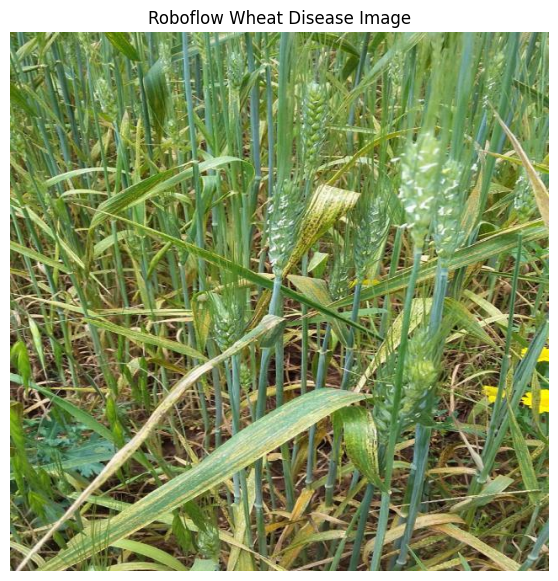

In [ ]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    sample_image
)

plt.title(
    "Roboflow Wheat Disease Image"
)

plt.axis("off")
plt.show()

### Step 15.6: Inspect the Generated Binary Disease Mask

The generated binary segmentation mask is displayed.

White regions represent Septoria or yellow/stripe-rust annotations.

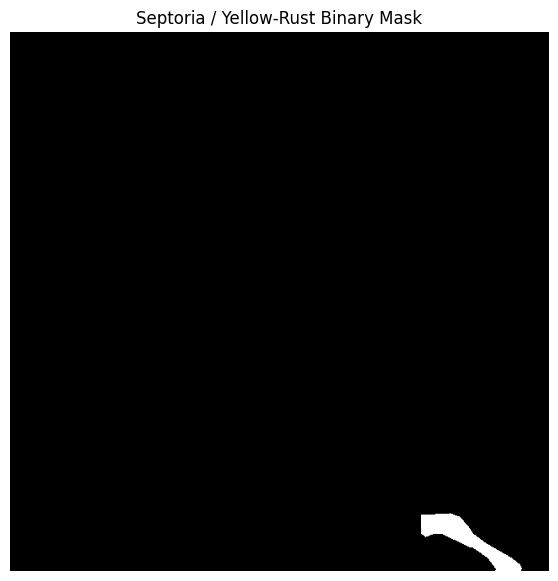

In [ ]:
plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    binary_mask_np,
    cmap="gray"
)

plt.title(
    "Septoria / Yellow-Rust Binary Mask"
)

plt.axis("off")
plt.show()

### Step 15.7: Verify Image-Mask Alignment

The generated disease mask is overlaid on the original wheat image.

The highlighted regions should align directly with the visible annotated disease symptoms.

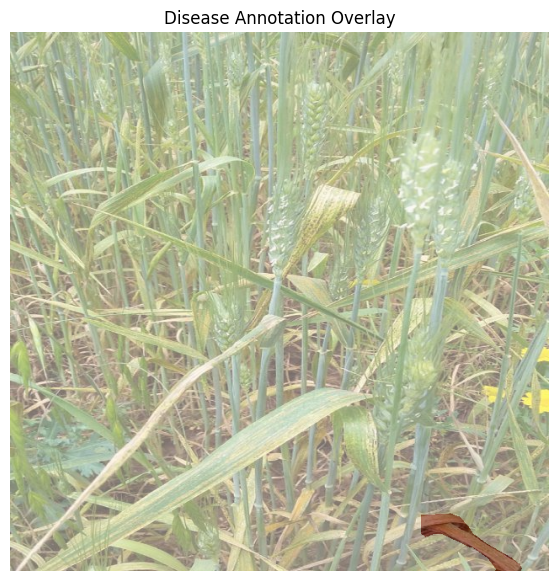

In [ ]:
plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    sample_image
)

plt.imshow(
    binary_mask_np,
    cmap="Reds",
    alpha=0.45
)

plt.title(
    "Disease Annotation Overlay"
)

plt.axis("off")
plt.show()

In [ ]:
print("Image size:", sample_image.size)
print("Mask size :", binary_mask_image.size)
print("Mask values:", np.unique(binary_mask_np))

Image size: (640, 640)
Mask size : (640, 640)
Mask values: [  0 255]


## Step 16: Generate Binary Disease Masks for the Full Dataset

All WheatPlant2 images containing Septoria or yellow-rust annotations are converted into binary segmentation image-mask pairs.

Only the target Agri-Vision disease classes are included:

- Wheat Septoria
- Wheat Yellow Rust / Stripe Rust

Each generated mask uses:

- `0` = non-target pixels
- `255` = disease pixels

The converted dataset is stored temporarily in Colab.

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw
import numpy as np
import json
import shutil

V2_ROOT = Path("/content/roboflow_binary")

if V2_ROOT.exists():
    shutil.rmtree(V2_ROOT)

for split in ["train", "valid", "test"]:

    (V2_ROOT / split / "images").mkdir(
        parents=True,
        exist_ok=True
    )

    (V2_ROOT / split / "masks").mkdir(
        parents=True,
        exist_ok=True
    )

print("Binary dataset folders created.")

Binary dataset folders created.


### Step 16.1: Convert COCO Polygons Into Binary Masks

For each image, all Septoria and yellow-rust polygons are merged into one binary disease mask.

In [ ]:
TARGET_CLASS_NAMES = {
    "wheat-septoria",
    "wheat-yellowrust"
}


def convert_split_to_binary(
    split_name,
    source_root,
    output_root
):

    annotation_path = (
        source_root
        / split_name
        / "_annotations.coco.json"
    )

    with open(
        annotation_path,
        "r"
    ) as file:
        coco = json.load(file)

    category_lookup = {
        category["id"]: category["name"]
        for category in coco["categories"]
    }

    target_ids = {
        category_id
        for category_id, name
        in category_lookup.items()
        if name in TARGET_CLASS_NAMES
    }

    image_lookup = {
        image["id"]: image
        for image in coco["images"]
    }

    annotations_by_image = {}

    for annotation in coco["annotations"]:

        if annotation["category_id"] not in target_ids:
            continue

        image_id = annotation["image_id"]

        annotations_by_image.setdefault(
            image_id,
            []
        ).append(annotation)

    converted = 0

    for image_id, annotations in annotations_by_image.items():

        info = image_lookup[image_id]

        width = info["width"]
        height = info["height"]

        source_image_path = (
            source_root
            / split_name
            / info["file_name"]
        )

        if not source_image_path.exists():
            continue

        mask = Image.new(
            "L",
            (width, height),
            0
        )

        draw = ImageDraw.Draw(mask)

        for annotation in annotations:

            segmentation = annotation.get(
                "segmentation",
                []
            )

            for polygon in segmentation:

                if not isinstance(polygon, list):
                    continue

                if len(polygon) < 6:
                    continue

                points = [
                    (
                        polygon[i],
                        polygon[i + 1]
                    )
                    for i in range(
                        0,
                        len(polygon),
                        2
                    )
                ]

                draw.polygon(
                    points,
                    fill=255
                )

        mask_np = np.array(mask)

        # Ignore empty masks
        if np.count_nonzero(mask_np) == 0:
            continue

        output_image_path = (
            output_root
            / split_name
            / "images"
            / info["file_name"]
        )

        output_mask_path = (
            output_root
            / split_name
            / "masks"
            / f"{Path(info['file_name']).stem}.png"
        )

        shutil.copy2(
            source_image_path,
            output_image_path
        )

        mask.save(
            output_mask_path
        )

        converted += 1

    return converted

In [ ]:
conversion_counts = {}

for split in [
    "train",
    "valid",
    "test"
]:

    count = convert_split_to_binary(
        split,
        ROBOFLOW_ROOT,
        V2_ROOT
    )

    conversion_counts[split] = count

    print(
        split,
        "usable images:",
        count
    )

train usable images: 915
valid usable images: 96
test usable images: 42


### Step 16.3: Verify Generated Image-Mask Pairs

The converted dataset is checked to ensure that every image has a corresponding binary mask.

In [ ]:
for split in [
    "train",
    "valid",
    "test"
]:

    image_dir = (
        V2_ROOT
        / split
        / "images"
    )

    mask_dir = (
        V2_ROOT
        / split
        / "masks"
    )

    images = [
        file
        for file in image_dir.iterdir()
        if file.is_file()
    ]

    masks = [
        file
        for file in mask_dir.iterdir()
        if file.is_file()
    ]

    print(
        f"\n{split.upper()}"
    )

    print(
        "Images:",
        len(images)
    )

    print(
        "Masks:",
        len(masks)
    )

    print(
        "Counts match:",
        len(images) == len(masks)
    )


TRAIN
Images: 915
Masks: 915
Counts match: True

VALID
Images: 96
Masks: 96
Counts match: True

TEST
Images: 42
Masks: 42
Counts match: True


## Step 17: Audit the Converted Roboflow Dataset

Before combining WheatPlant2 with NWRD, the converted dataset is analysed to determine:

- Number of Septoria images
- Number of yellow-rust images
- Images containing both diseases
- Disease-pixel coverage
- Possible augmentation-generated duplicates
- Distribution across training, validation, and test sets

This prevents duplicated or highly imbalanced data from artificially influencing Version 2 performance.

In [ ]:
from collections import defaultdict

TARGET_SEPTORIA = "wheat-septoria"
TARGET_YELLOW_RUST = "wheat-yellowrust"


def count_target_images(coco_data):

    category_lookup = {
        category["id"]: category["name"]
        for category in coco_data["categories"]
    }

    image_classes = defaultdict(set)

    for annotation in coco_data["annotations"]:

        class_name = category_lookup[
            annotation["category_id"]
        ]

        if class_name in {
            TARGET_SEPTORIA,
            TARGET_YELLOW_RUST
        }:

            image_classes[
                annotation["image_id"]
            ].add(class_name)

    septoria_only = 0
    yellow_only = 0
    both = 0

    for classes in image_classes.values():

        if classes == {TARGET_SEPTORIA}:
            septoria_only += 1

        elif classes == {TARGET_YELLOW_RUST}:
            yellow_only += 1

        elif (
            TARGET_SEPTORIA in classes
            and TARGET_YELLOW_RUST in classes
        ):
            both += 1

    return {
        "septoria_only": septoria_only,
        "yellow_rust_only": yellow_only,
        "both": both,
        "total_target_images": len(image_classes)
    }

In [ ]:
for split_name in [
    "train",
    "valid",
    "test"
]:

    annotation_path = (
        ROBOFLOW_ROOT
        / split_name
        / "_annotations.coco.json"
    )

    with open(
        annotation_path,
        "r"
    ) as file:

        data = json.load(file)

    result = count_target_images(data)

    print(
        f"\n===== {split_name.upper()} ====="
    )

    print(
        "Septoria only:",
        result["septoria_only"]
    )

    print(
        "Yellow rust only:",
        result["yellow_rust_only"]
    )

    print(
        "Both diseases:",
        result["both"]
    )

    print(
        "Total usable:",
        result["total_target_images"]
    )


===== TRAIN =====
Septoria only: 261
Yellow rust only: 648
Both diseases: 6
Total usable: 915

===== VALID =====
Septoria only: 28
Yellow rust only: 68
Both diseases: 0
Total usable: 96

===== TEST =====
Septoria only: 13
Yellow rust only: 29
Both diseases: 0
Total usable: 42


### Step 17.2: Analyse Disease Coverage

The percentage of each image occupied by annotated Septoria or yellow-rust pixels is measured.

This helps determine how the additional dataset differs from NWRD and whether very large disease regions could dominate training.

In [ ]:
def analyse_binary_masks(mask_directory):

    coverage_values = []

    mask_files = sorted(
        mask_directory.glob("*.png")
    )

    for mask_path in mask_files:

        mask = np.array(
            Image.open(mask_path).convert("L")
        )

        coverage = (
            np.count_nonzero(mask)
            / mask.size
        ) * 100

        coverage_values.append(
            coverage
        )

    return np.array(
        coverage_values,
        dtype=np.float32
    )

In [ ]:
def analyse_binary_masks(mask_directory):

    coverage_values = []

    mask_files = sorted(
        mask_directory.glob("*.png")
    )

    for mask_path in mask_files:

        mask = np.array(
            Image.open(mask_path).convert("L")
        )

        coverage = (
            np.count_nonzero(mask)
            / mask.size
        ) * 100

        coverage_values.append(
            coverage
        )

    return np.array(
        coverage_values,
        dtype=np.float32
    )

### Step 17.3: Inspect Possible Augmented Image Versions

Roboflow Version 1 includes generated image versions.

Filenames are inspected to determine whether multiple augmented copies originate from the same source image.

In [ ]:
rf_train_image_dir = (
    V2_ROOT
    / "train"
    / "images"
)

rf_train_images = sorted(
    file
    for file in rf_train_image_dir.iterdir()
    if file.is_file()
)

print(
    "Training images:",
    len(rf_train_images)
)

print("\nFirst 20 filenames:")

for file in rf_train_images[:20]:
    print(file.name)

Training images: 915

First 20 filenames:
powdery_mildew-182-_jpg.rf.23ccfa4aa9aa433f077d768f43aa1517.jpg
powdery_mildew-182-_jpg.rf.d16c5e44b53c80509597a3ca60441ea9.jpg
powdery_mildew-182-_jpg.rf.e299a6fcf0b015446b4e98adaa38b5b7.jpg
powdery_mildew-232-_jpg.rf.092a8b286ce2511f21b00086e972b55a.jpg
powdery_mildew-232-_jpg.rf.87ae52e5d093160dbaaa66c6e9a997c5.jpg
powdery_mildew-232-_jpg.rf.cafd4f6c4cc1a7f569d60fff4a7b41d1.jpg
powdery_mildew-267-_jpg.rf.3ebd7055f31920e847e1c12ca66833ab.jpg
powdery_mildew-267-_jpg.rf.46efbf40f09f22be2a65df7bb35018a1.jpg
powdery_mildew-267-_jpg.rf.efae233048d2549cb7ff224c16aa0737.jpg
powdery_mildew-273-_jpg.rf.82d99a4594e87e87afae52f2ebd3ba02.jpg
powdery_mildew-273-_jpg.rf.c899e2dea84ab53068bff01170b1289b.jpg
powdery_mildew-273-_jpg.rf.de0017fcf3c9528e55f7a14c001a021c.jpg
stem_rust-102-_jpg.rf.0470df414fbf42109d77c55b1eb366d3.jpg
stem_rust-102-_jpg.rf.336d65ec3059e3dc34a98c6bb91107e9.jpg
stem_rust-102-_jpg.rf.86d6200726913dee4181c78e0dd3fc91.jpg
stem_rust-168

### Step 17.4: Estimate Unique Source Images

Roboflow-generated filenames may contain a unique `.rf.` hash.

The filename portion before this hash is used as an approximate source-image identifier to estimate how many training samples are augmented versions of the same original image.

In [ ]:
def source_identifier(filename):

    name = Path(filename).name

    if ".rf." in name:
        return name.split(".rf.")[0]

    return Path(name).stem


source_groups = defaultdict(list)

for file in rf_train_images:

    source_id = source_identifier(
        file.name
    )

    source_groups[
        source_id
    ].append(
        file.name
    )

print(
    "Total training images:",
    len(rf_train_images)
)

print(
    "Approximate unique sources:",
    len(source_groups)
)

duplicate_groups = {
    source:
    files
    for source, files
    in source_groups.items()
    if len(files) > 1
}

print(
    "Source groups with multiple versions:",
    len(duplicate_groups)
)

Total training images: 915
Approximate unique sources: 305
Source groups with multiple versions: 305


In [ ]:
print("\nExample repeated source groups:")

for source, files in list(
    duplicate_groups.items()
)[:10]:

    print(
        "\nSource:",
        source
    )

    for file in files:
        print("  ", file)


Example repeated source groups:

Source: powdery_mildew-182-_jpg
   powdery_mildew-182-_jpg.rf.23ccfa4aa9aa433f077d768f43aa1517.jpg
   powdery_mildew-182-_jpg.rf.d16c5e44b53c80509597a3ca60441ea9.jpg
   powdery_mildew-182-_jpg.rf.e299a6fcf0b015446b4e98adaa38b5b7.jpg

Source: powdery_mildew-232-_jpg
   powdery_mildew-232-_jpg.rf.092a8b286ce2511f21b00086e972b55a.jpg
   powdery_mildew-232-_jpg.rf.87ae52e5d093160dbaaa66c6e9a997c5.jpg
   powdery_mildew-232-_jpg.rf.cafd4f6c4cc1a7f569d60fff4a7b41d1.jpg

Source: powdery_mildew-267-_jpg
   powdery_mildew-267-_jpg.rf.3ebd7055f31920e847e1c12ca66833ab.jpg
   powdery_mildew-267-_jpg.rf.46efbf40f09f22be2a65df7bb35018a1.jpg
   powdery_mildew-267-_jpg.rf.efae233048d2549cb7ff224c16aa0737.jpg

Source: powdery_mildew-273-_jpg
   powdery_mildew-273-_jpg.rf.82d99a4594e87e87afae52f2ebd3ba02.jpg
   powdery_mildew-273-_jpg.rf.c899e2dea84ab53068bff01170b1289b.jpg
   powdery_mildew-273-_jpg.rf.de0017fcf3c9528e55f7a14c001a021c.jpg

Source: stem_rust-102-_jpg
   

### Step 17.5: Check for Exact Duplicate Training Images

File hashes are calculated to identify images that are byte-for-byte identical.

Exact duplicates are different from legitimate augmented variants and can be safely identified before Version 2 training.

In [ ]:
import hashlib


def file_hash(path):

    hasher = hashlib.md5()

    with open(
        path,
        "rb"
    ) as file:

        while True:

            chunk = file.read(
                1024 * 1024
            )

            if not chunk:
                break

            hasher.update(
                chunk
            )

    return hasher.hexdigest()

In [ ]:
hash_groups = defaultdict(list)

for file in rf_train_images:

    hash_value = file_hash(
        file
    )

    hash_groups[
        hash_value
    ].append(
        file.name
    )

exact_duplicate_groups = {
    hash_value:
    files
    for hash_value, files
    in hash_groups.items()
    if len(files) > 1
}

exact_duplicate_count = sum(
    len(files) - 1
    for files
    in exact_duplicate_groups.values()
)

print(
    "Exact duplicate groups:",
    len(exact_duplicate_groups)
)

print(
    "Extra exact duplicate files:",
    exact_duplicate_count
)

Exact duplicate groups: 0
Extra exact duplicate files: 0


### Step 17.6: Check Source-Level Split Leakage

Approximate source-image identifiers are compared between the Roboflow training, validation, and test subsets.

This helps detect whether augmented variants of the same original photograph appear in multiple dataset splits.

In [ ]:
def get_source_ids(image_directory):

    ids = set()

    for file in image_directory.iterdir():

        if file.is_file():

            ids.add(
                source_identifier(
                    file.name
                )
            )

    return ids

In [ ]:
rf_train_sources = get_source_ids(
    V2_ROOT / "train" / "images"
)

rf_valid_sources = get_source_ids(
    V2_ROOT / "valid" / "images"
)

rf_test_sources = get_source_ids(
    V2_ROOT / "test" / "images"
)

print(
    "Train source IDs:",
    len(rf_train_sources)
)

print(
    "Valid source IDs:",
    len(rf_valid_sources)
)

print(
    "Test source IDs:",
    len(rf_test_sources)
)

print(
    "\nTrain ↔ Valid overlap:",
    len(
        rf_train_sources
        &
        rf_valid_sources
    )
)

print(
    "Train ↔ Test overlap:",
    len(
        rf_train_sources
        &
        rf_test_sources
    )
)

print(
    "Valid ↔ Test overlap:",
    len(
        rf_valid_sources
        &
        rf_test_sources
    )
)

Train source IDs: 305
Valid source IDs: 96
Test source IDs: 42

Train ↔ Valid overlap: 0
Train ↔ Test overlap: 0
Valid ↔ Test overlap: 0


### Step 17.7: Measure Roboflow Disease Coverage

The percentage of pixels occupied by Septoria or yellow-rust annotations is measured.

These statistics are compared with NWRD to determine whether the two datasets have very different disease-region distributions.


In [ ]:
for split in [
    "train",
    "valid",
    "test"
]:

    mask_dir = (
        V2_ROOT
        / split
        / "masks"
    )

    coverage = analyse_binary_masks(
        mask_dir
    )

    print(
        f"\n===== {split.upper()} ====="
    )

    print(
        "Masks:",
        len(coverage)
    )

    print(
        f"Minimum coverage: "
        f"{coverage.min():.4f}%"
    )

    print(
        f"Maximum coverage: "
        f"{coverage.max():.4f}%"
    )

    print(
        f"Mean coverage: "
        f"{coverage.mean():.4f}%"
    )

    print(
        f"Median coverage: "
        f"{np.median(coverage):.4f}%"
    )


===== TRAIN =====
Masks: 915
Minimum coverage: 0.0754%
Maximum coverage: 94.7646%
Mean coverage: 13.2774%
Median coverage: 7.2593%

===== VALID =====
Masks: 96
Minimum coverage: 0.2500%
Maximum coverage: 81.1233%
Mean coverage: 12.1142%
Median coverage: 4.9908%

===== TEST =====
Masks: 42
Minimum coverage: 0.2671%
Maximum coverage: 40.1541%
Mean coverage: 8.4694%
Median coverage: 5.2814%


### Step 17.8: Check for Exact Duplicate Training Images

Although multiple augmented versions originate from the same source image, byte-identical duplicates are checked separately.

Augmented versions are acceptable training samples, while exact duplicate files provide no additional information.

In [ ]:
import hashlib
from collections import defaultdict


def file_hash(path):

    hasher = hashlib.md5()

    with open(path, "rb") as file:

        while True:

            chunk = file.read(
                1024 * 1024
            )

            if not chunk:
                break

            hasher.update(chunk)

    return hasher.hexdigest()


hash_groups = defaultdict(list)

for file in rf_train_images:

    hash_value = file_hash(
        file
    )

    hash_groups[
        hash_value
    ].append(
        file.name
    )


exact_duplicate_groups = {
    hash_value: files
    for hash_value, files
    in hash_groups.items()
    if len(files) > 1
}

exact_duplicate_count = sum(
    len(files) - 1
    for files
    in exact_duplicate_groups.values()
)

print(
    "Exact duplicate groups:",
    len(exact_duplicate_groups)
)

print(
    "Extra exact duplicate files:",
    exact_duplicate_count
)

Exact duplicate groups: 0
Extra exact duplicate files: 0


## Step 18: Build the Balanced Version 2 Training Dataset

The Version 2 training dataset combines:

- NWRD field-view patches
- Roboflow Septoria segmentation images
- Roboflow yellow/stripe-rust segmentation images

Roboflow data is sampled in a controlled manner because its average disease coverage is much higher than NWRD.

Septoria and yellow-rust images are also balanced so that the model does not become biased toward yellow rust.

In [ ]:
from collections import defaultdict
from pathlib import Path

RF_TRAIN_IMAGE_DIR = (
    V2_ROOT / "train" / "images"
)

RF_TRAIN_MASK_DIR = (
    V2_ROOT / "train" / "masks"
)

category_lookup = {
    category["id"]: category["name"]
    for category in train_coco["categories"]
}

image_info_lookup = {
    image["id"]: image
    for image in train_coco["images"]
}

image_classes = defaultdict(set)

for annotation in train_coco["annotations"]:

    class_name = category_lookup[
        annotation["category_id"]
    ]

    if class_name in {
        "wheat-septoria",
        "wheat-yellowrust"
    }:

        image_classes[
            annotation["image_id"]
        ].add(class_name)

### Step 18.2: Separate Septoria and Yellow-Rust Samples

Converted Roboflow image-mask pairs are grouped according to disease type.

Images containing both target diseases are kept separately.

In [ ]:
septoria_pairs = []
yellow_rust_pairs = []
both_pairs = []

for image_id, classes in image_classes.items():

    info = image_info_lookup[
        image_id
    ]

    image_path = (
        RF_TRAIN_IMAGE_DIR
        / info["file_name"]
    )

    mask_path = (
        RF_TRAIN_MASK_DIR
        / f"{Path(info['file_name']).stem}.png"
    )

    if not image_path.exists():
        continue

    if not mask_path.exists():
        continue

    pair = (
        str(image_path),
        str(mask_path)
    )

    if classes == {"wheat-septoria"}:

        septoria_pairs.append(pair)

    elif classes == {"wheat-yellowrust"}:

        yellow_rust_pairs.append(pair)

    else:

        both_pairs.append(pair)


print(
    "Septoria pairs:",
    len(septoria_pairs)
)

print(
    "Yellow-rust pairs:",
    len(yellow_rust_pairs)
)

print(
    "Both diseases:",
    len(both_pairs)
)

Septoria pairs: 261
Yellow-rust pairs: 648
Both diseases: 6


### Step 18.3: Balance Disease Representation

Septoria is less common than yellow rust in the Roboflow training set.

Controlled sampling is used to create approximately equal Septoria and yellow-rust representation.

This helps the binary segmentation model learn visual patterns from both diseases.

In [ ]:
import random

random.seed(42)

TARGET_PER_DISEASE = 450


selected_septoria = random.choices(
    septoria_pairs,
    k=TARGET_PER_DISEASE
)

selected_yellow = random.sample(
    yellow_rust_pairs,
    k=TARGET_PER_DISEASE
)

selected_rf_pairs = (
    selected_septoria
    + selected_yellow
    + both_pairs
)

random.shuffle(
    selected_rf_pairs
)

print(
    "Selected Septoria:",
    len(selected_septoria)
)

print(
    "Selected yellow rust:",
    len(selected_yellow)
)

print(
    "Both disease samples:",
    len(both_pairs)
)

print(
    "Total Roboflow V2 samples:",
    len(selected_rf_pairs)
)

Selected Septoria: 450
Selected yellow rust: 450
Both disease samples: 6
Total Roboflow V2 samples: 906


### Step 18.4: Prepare NWRD Training Pairs

The previously generated balanced NWRD patches remain the primary field-view training source.

These samples contain both disease-positive and disease-free regions.

In [ ]:
nwrd_train_images = sorted(
    TRAIN_PATCH_IMAGE_DIR.glob(
        "*.jpg"
    )
)

nwrd_train_masks = sorted(
    TRAIN_PATCH_MASK_DIR.glob(
        "*.png"
    )
)

nwrd_image_lookup = {
    file.stem: file
    for file in nwrd_train_images
}

nwrd_mask_lookup = {
    file.stem: file
    for file in nwrd_train_masks
}

nwrd_stems = sorted(
    set(nwrd_image_lookup)
    &
    set(nwrd_mask_lookup)
)

nwrd_v2_pairs = [
    (
        str(nwrd_image_lookup[stem]),
        str(nwrd_mask_lookup[stem])
    )
    for stem in nwrd_stems
]

print(
    "NWRD training pairs:",
    len(nwrd_v2_pairs)
)

NWRD training pairs: 2265


### Step 18.5: Create the Combined Version 2 Training Set

The field-oriented NWRD patches are combined with balanced Septoria and yellow-rust samples.

NWRD remains the majority source so that the model retains sensitivity to small disease regions in realistic field-view images.

In [ ]:
combined_v2_pairs = (
    nwrd_v2_pairs
    + selected_rf_pairs
)

random.seed(42)

random.shuffle(
    combined_v2_pairs
)

print(
    "NWRD samples:",
    len(nwrd_v2_pairs)
)

print(
    "Roboflow samples:",
    len(selected_rf_pairs)
)

print(
    "Combined V2 training samples:",
    len(combined_v2_pairs)
)

NWRD samples: 2265
Roboflow samples: 906
Combined V2 training samples: 3171


### Step 18.6: Standardize Combined Image-Mask Pairs

Both datasets are converted to a common neural-network input size of `512 × 512`.

Images use bilinear resizing.

Segmentation masks use nearest-neighbor resizing to preserve binary annotation boundaries.

In [ ]:
IMG_HEIGHT = 512
IMG_WIDTH = 512


def load_v2_image_mask(
    image_path,
    mask_path
):

    image_data = tf.io.read_file(
        image_path
    )

    image = tf.io.decode_image(
        image_data,
        channels=3,
        expand_animations=False
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
        method="bilinear"
    )

    image = image / 255.0


    mask_data = tf.io.read_file(
        mask_path
    )

    mask = tf.io.decode_image(
        mask_data,
        channels=1,
        expand_animations=False
    )

    mask = tf.cast(
        mask,
        tf.float32
    )

    mask = tf.image.resize(
        mask,
        [IMG_HEIGHT, IMG_WIDTH],
        method="nearest"
    )

    mask = tf.cast(
        mask > 0,
        tf.float32
    )

    image.set_shape(
        [512, 512, 3]
    )

    mask.set_shape(
        [512, 512, 1]
    )

    return image, mask

### Step 18.7: Create the Combined TensorFlow Dataset

The combined Version 2 image-mask paths are converted into a memory-efficient TensorFlow pipeline.

A small batch size is retained to avoid Colab RAM and GPU-memory issues.

In [ ]:
v2_image_paths = [
    pair[0]
    for pair in combined_v2_pairs
]

v2_mask_paths = [
    pair[1]
    for pair in combined_v2_pairs
]


train_v2_dataset = (
    tf.data.Dataset
    .from_tensor_slices(
        (
            v2_image_paths,
            v2_mask_paths
        )
    )
)

train_v2_dataset = train_v2_dataset.shuffle(
    buffer_size=512,
    seed=42,
    reshuffle_each_iteration=True
)

train_v2_dataset = train_v2_dataset.map(
    load_v2_image_mask,
    num_parallel_calls=2
)

train_v2_dataset = train_v2_dataset.map(
    augment_image_mask,
    num_parallel_calls=2
)

train_v2_dataset = train_v2_dataset.batch(
    2
)

train_v2_dataset = train_v2_dataset.prefetch(
    1
)

print(
    "V2 TensorFlow training dataset ready."
)

V2 TensorFlow training dataset ready.


### Step 18.8: Verify the Version 2 Input Pipeline

A training batch is inspected before Version 2 training begins.

In [ ]:
for images, masks in train_v2_dataset.take(1):

    print(
        "Image batch:",
        images.shape
    )

    print(
        "Mask batch:",
        masks.shape
    )

    print(
        "Image range:",
        float(
            tf.reduce_min(images)
        ),
        "to",
        float(
            tf.reduce_max(images)
        )
    )

    print(
        "Mask values:",
        np.unique(
            masks.numpy()
        )
    )

Image batch: (2, 512, 512, 3)
Mask batch: (2, 512, 512, 1)
Image range: 0.0 to 1.0
Mask values: [0.]


### Step 18.9: Verify Positive and Negative Samples

The combined Version 2 dataset contains both disease-positive and disease-free training samples.

A random batch may occasionally contain only background masks.

Before training, every image-mask pair is checked to determine the number of positive and negative samples in the complete V2 training dataset.

In [ ]:
positive_v2 = 0
negative_v2 = 0

for _, mask_path in combined_v2_pairs:

    mask = np.array(
        Image.open(mask_path).convert("L")
    )

    if np.count_nonzero(mask) > 0:
        positive_v2 += 1
    else:
        negative_v2 += 1

print("Positive samples:", positive_v2)
print("Negative samples:", negative_v2)
print("Total samples:", len(combined_v2_pairs))

print(
    "Positive percentage:",
    round(
        positive_v2 / len(combined_v2_pairs) * 100,
        2
    ),
    "%"
)

Positive samples: 1913
Negative samples: 1258
Total samples: 3171
Positive percentage: 60.33 %


### Step 18.10: Inspect Multiple Version 2 Batches

Several training batches are inspected to confirm that both positive and disease-free masks are present in the TensorFlow pipeline.

In [ ]:
for batch_number, (images, masks) in enumerate(
    train_v2_dataset.take(10),
    start=1
):

    mask_values = np.unique(
        masks.numpy()
    )

    disease_pixels = np.count_nonzero(
        masks.numpy()
    )

    print(
        f"Batch {batch_number}:",
        "values =",
        mask_values,
        "| disease pixels =",
        disease_pixels
    )

Batch 1: values = [0. 1.] | disease pixels = 78465
Batch 2: values = [0. 1.] | disease pixels = 7529
Batch 3: values = [0. 1.] | disease pixels = 7951
Batch 4: values = [0. 1.] | disease pixels = 5658
Batch 5: values = [0.] | disease pixels = 0
Batch 6: values = [0. 1.] | disease pixels = 1404
Batch 7: values = [0. 1.] | disease pixels = 26400
Batch 8: values = [0. 1.] | disease pixels = 1404
Batch 9: values = [0. 1.] | disease pixels = 13621
Batch 10: values = [0. 1.] | disease pixels = 187248


### Step 18.11: Verify a Known Roboflow Disease Sample

A known Roboflow image-mask pair is passed through the Version 2 preprocessing function.

The processed mask should retain binary disease pixels after resizing.

In [ ]:
rf_test_image_path = selected_rf_pairs[0][0]
rf_test_mask_path = selected_rf_pairs[0][1]

test_image, test_mask = load_v2_image_mask(
    rf_test_image_path,
    rf_test_mask_path
)

print(
    "Image shape:",
    test_image.shape
)

print(
    "Mask shape:",
    test_mask.shape
)

print(
    "Mask values:",
    np.unique(
        test_mask.numpy()
    )
)

print(
    "Disease pixels:",
    np.count_nonzero(
        test_mask.numpy()
    )
)

Image shape: (512, 512, 3)
Mask shape: (512, 512, 1)
Mask values: [0. 1.]
Disease pixels: 22540


## Step 19: Prepare Separate Version 2 Validation Sets

Version 2 is evaluated on two validation domains:

1. NWRD field-view validation
2. Roboflow Septoria and yellow-rust validation

NWRD remains the primary model-selection dataset because the final Agri-Vision damage-estimation feature must work on realistic field-view images.

Roboflow validation is evaluated separately to measure performance on the additional disease dataset.

In [ ]:
RF_VALID_IMAGE_DIR = (
    V2_ROOT / "valid" / "images"
)

RF_VALID_MASK_DIR = (
    V2_ROOT / "valid" / "masks"
)

rf_val_images = sorted(
    RF_VALID_IMAGE_DIR.iterdir()
)

rf_val_masks = sorted(
    RF_VALID_MASK_DIR.iterdir()
)

rf_val_image_lookup = {
    file.stem: file
    for file in rf_val_images
    if file.is_file()
}

rf_val_mask_lookup = {
    file.stem: file
    for file in rf_val_masks
    if file.is_file()
}

rf_val_stems = sorted(
    set(rf_val_image_lookup)
    &
    set(rf_val_mask_lookup)
)

rf_val_pairs = [
    (
        str(rf_val_image_lookup[stem]),
        str(rf_val_mask_lookup[stem])
    )
    for stem in rf_val_stems
]

print(
    "Roboflow validation pairs:",
    len(rf_val_pairs)
)

Roboflow validation pairs: 96


In [ ]:
rf_val_image_paths = [
    pair[0]
    for pair in rf_val_pairs
]

rf_val_mask_paths = [
    pair[1]
    for pair in rf_val_pairs
]

rf_val_dataset = (
    tf.data.Dataset
    .from_tensor_slices(
        (
            rf_val_image_paths,
            rf_val_mask_paths
        )
    )
)

rf_val_dataset = rf_val_dataset.map(
    load_v2_image_mask,
    num_parallel_calls=2
)

rf_val_dataset = rf_val_dataset.batch(
    2
)

rf_val_dataset = rf_val_dataset.prefetch(
    1
)

print(
    "Roboflow validation dataset ready."
)

Roboflow validation dataset ready.


## Step 20: Initialize Version 2 from the Best Version 1 Model

Version 2 training starts from the best fine-tuned Version 1 checkpoint.

This preserves the field-view rust-segmentation knowledge already learned from NWRD while adapting the model to additional Septoria and yellow-rust data.

In [ ]:
from pathlib import Path

V1_MODEL_PATH = Path(
    "/content/drive/MyDrive/"
    "Agri-Vision/models/"
    "best_damage_segmentation_stage2.keras"
)

print(
    "V1 model exists:",
    V1_MODEL_PATH.exists()
)

V1 model exists: True


In [ ]:
v2_model = tf.keras.models.load_model(
    V1_MODEL_PATH,
    compile=False
)

print("V1 checkpoint loaded for V2 training.")

print(
    "Input shape:",
    v2_model.input_shape
)

print(
    "Output shape:",
    v2_model.output_shape
)

V1 checkpoint loaded for V2 training.
Input shape: (None, 512, 512, 3)
Output shape: (None, 512, 512, 1)


### Step 20.1: Configure Conservative Version 2 Fine-Tuning

Version 2 continues fine-tuning using a very small learning rate.

Early pretrained layers remain frozen while deeper layers and the decoder are allowed to adapt to the expanded disease dataset.

In [ ]:
for layer in v2_model.layers:
    print(
        layer.name,
        "→",
        layer.trainable
    )

segmentation_input → True
mobilenet_preprocessing → True
mobilenetv2_encoder → True
decoder1_upsample → True
decoder1_concat → True
decoder1_conv1 → True
decoder1_bn1 → True
decoder1_relu1 → True
decoder1_conv2 → True
decoder1_bn2 → True
decoder1_relu2 → True
decoder2_upsample → True
decoder2_concat → True
decoder2_conv1 → True
decoder2_bn1 → True
decoder2_relu1 → True
decoder2_conv2 → True
decoder2_bn2 → True
decoder2_relu2 → True
decoder3_upsample → True
decoder3_concat → True
decoder3_conv1 → True
decoder3_bn1 → True
decoder3_relu1 → True
decoder3_conv2 → True
decoder3_bn2 → True
decoder3_relu2 → True
decoder4_upsample → True
decoder4_concat → True
decoder4_conv1 → True
decoder4_bn1 → True
decoder4_relu1 → True
decoder4_conv2 → True
decoder4_bn2 → True
decoder4_relu2 → True
final_upsample → True
segmentation_mask → True


In [ ]:
encoder_v2 = v2_model.get_layer(
    "mobilenetv2_encoder"
)

print(
    "Encoder trainable:",
    encoder_v2.trainable
)

print(
    "Encoder layers:",
    len(encoder_v2.layers)
)

Encoder trainable: True
Encoder layers: 150


# 20.2: Fine-Tune Only the Deeper Encoder Layers

In [ ]:
encoder_v2.trainable = True

for layer in encoder_v2.layers:
    layer.trainable = False

for layer in encoder_v2.layers[-40:]:

    if not isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True


trainable_encoder_layers = [
    layer
    for layer in encoder_v2.layers
    if layer.trainable
]

print(
    "Trainable encoder layers:",
    len(trainable_encoder_layers)
)

Trainable encoder layers: 27


### Step 20.3: Compile the Version 2 Model

Version 2 uses a low learning rate to adapt gradually to the expanded dataset.

NWRD validation Dice remains the main checkpoint metric.

In [ ]:
v2_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-6
    ),

    loss=combined_loss,

    metrics=[

        DiceMetric(
            name="dice"
        ),

        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="iou"
        ),

        tf.keras.metrics.Precision(
            thresholds=0.5,
            name="precision"
        ),

        tf.keras.metrics.Recall(
            thresholds=0.5,
            name="recall"
        ),

        tf.keras.metrics.BinaryAccuracy(
            threshold=0.5,
            name="binary_accuracy"
        )
    ]
)

print(
    "V2 model compiled successfully."
)

V2 model compiled successfully.


### Step 20.4: Configure Version 2 Checkpoints

Version 2 is saved separately from Version 1 so that both models can later be compared on the same official NWRD test set.

In [ ]:
V2_MODEL_PATH = (
    MODEL_DIR /
    "best_damage_segmentation_v2.keras"
)

print(
    "V2 checkpoint:",
    V2_MODEL_PATH
)

V2 checkpoint: /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v2.keras


In [ ]:
callbacks_v2 = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            V2_MODEL_PATH
        ),
        monitor="val_dice",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice",
        mode="max",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(
            MODEL_DIR /
            "v2_training_history.csv"
        )
    )
]

### Step 20.5: Verify Version 2 Model Input

One combined training batch is passed through the Version 2 model before training begins.

In [ ]:
for test_images, test_masks in train_v2_dataset.take(1):

    test_predictions = v2_model(
        test_images,
        training=False
    )

    print(
        "Input:",
        test_images.shape
    )

    print(
        "Ground truth:",
        test_masks.shape
    )

    print(
        "Prediction:",
        test_predictions.shape
    )

    print(
        "Prediction range:",
        float(
            tf.reduce_min(
                test_predictions
            )
        ),
        "to",
        float(
            tf.reduce_max(
                test_predictions
            )
        )
    )

Input: (2, 512, 512, 3)
Ground truth: (2, 512, 512, 1)
Prediction: (2, 512, 512, 1)
Prediction range: 1.604008419142655e-11 to 0.9890798926353455


# 20.6: Train Version 2

In [ ]:
EPOCHS_V2 = 15

history_v2 = v2_model.fit(
    train_v2_dataset,

    validation_data=val_dataset_final,

    epochs=EPOCHS_V2,

    callbacks=callbacks_v2,

    verbose=1
)

Epoch 1/15
1586/1586 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - binary_accuracy: 0.9598 - dice: 0.5411 - iou: 0.3709 - loss: 0.8104 - precision: 0.6393 - recall: 0.4698
Epoch 1: val_dice improved from None to 0.45864, saving model to /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v2.keras
1586/1586 ━━━━━━━━━━━━━━━━━━━━ 161s 74ms/step - binary_accuracy: 0.9605 - dice: 0.5452 - iou: 0.3748 - loss: 0.8109 - precision: 0.6293 - recall: 0.4809 - val_binary_accuracy: 0.9952 - val_dice: 0.4586 - val_iou: 0.2976 - val_loss: 0.9341 - val_precision: 0.6102 - val_recall: 0.3674 - learning_rate: 5.0000e-06
Epoch 2/15
1585/1586 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - binary_accuracy: 0.9623 - dice: 0.5826 - iou: 0.4111 - loss: 0.7578 - precision: 0.6453 - recall: 0.5319
Epoch 2: val_dice did not improve from 0.45864
1586/1586 ━━━━━━━━━━━━━━━━━━━━ 69s 43ms/step - binary_accuracy: 0

## Step 21: Evaluate the Best Version 2 Model

The best Version 2 checkpoint is reloaded for independent evaluation.

Version 2 will be evaluated on:

1. NWRD field-view validation
2. Roboflow disease validation
3. The untouched NWRD official test set

This allows Version 1 and Version 2 to be compared fairly.

In [ ]:
V2_MODEL_PATH = (
    MODEL_DIR
    / "best_damage_segmentation_v2.keras"
)

best_v2_model = tf.keras.models.load_model(
    V2_MODEL_PATH,
    compile=False
)

print(
    "Best V2 model loaded:",
    V2_MODEL_PATH
)

Best V2 model loaded: /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v2.keras


In [ ]:
best_v2_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-6
    ),

    loss=combined_loss,

    metrics=[
        DiceMetric(name="dice"),

        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="iou"
        ),

        tf.keras.metrics.Precision(
            thresholds=0.5,
            name="precision"
        ),

        tf.keras.metrics.Recall(
            thresholds=0.5,
            name="recall"
        ),

        tf.keras.metrics.BinaryAccuracy(
            threshold=0.5,
            name="binary_accuracy"
        )
    ]
)

### Step 21.2: Evaluate Version 2 on NWRD Validation

NWRD validation measures whether Version 2 retained its ability to detect small disease regions in realistic field-view images.

In [ ]:
nwrd_v2_results = best_v2_model.evaluate(
    val_dataset_final,
    verbose=1,
    return_dict=True
)

print("\n===== V2 NWRD VALIDATION =====")

for name, value in nwrd_v2_results.items():
    print(
        f"{name}: {value:.4f}"
    )

642/642 ━━━━━━━━━━━━━━━━━━━━ 45s 35ms/step - binary_accuracy: 0.9948 - dice: 0.4763 - iou: 0.3126 - loss: 0.9250 - precision: 0.5366 - recall: 0.4282

===== V2 NWRD VALIDATION =====
binary_accuracy: 0.9948
dice: 0.4763
iou: 0.3126
loss: 0.9250
precision: 0.5366
recall: 0.4282


### Step 21.3: Evaluate Version 2 on Roboflow Validation

The separate Roboflow validation dataset measures how well Version 2 segments Septoria and yellow/stripe-rust regions from the additional dataset.

In [ ]:
rf_v2_results = best_v2_model.evaluate(
    rf_val_dataset,
    verbose=1,
    return_dict=True
)

print(
    "\n===== V2 ROBOFLOW VALIDATION ====="
)

for name, value in rf_v2_results.items():
    print(
        f"{name}: {value:.4f}"
    )

48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - binary_accuracy: 0.9049 - dice: 0.5673 - iou: 0.3959 - loss: 1.0330 - precision: 0.6320 - recall: 0.5146

===== V2 ROBOFLOW VALIDATION =====
binary_accuracy: 0.9049
dice: 0.5673
iou: 0.3959
loss: 1.0330
precision: 0.6320
recall: 0.5146


## Step 22: Optimize the Version 2 Segmentation Threshold

The default segmentation threshold of `0.50` may not be optimal for small disease regions.

Different thresholds are evaluated on the NWRD validation dataset.

The threshold producing the highest Dice score is selected before evaluating the untouched official NWRD test set.

In [ ]:
import numpy as np

thresholds = np.arange(
    0.20,
    0.81,
    0.05
)

threshold_stats = {
    float(t): {
        "tp": 0,
        "fp": 0,
        "fn": 0
    }
    for t in thresholds
}

for images, masks in val_dataset_final:

    predictions = best_v2_model(
        images,
        training=False
    ).numpy()

    y_true = (
        masks.numpy() > 0.5
    )

    for threshold in thresholds:

        y_pred = (
            predictions >= threshold
        )

        tp = np.logical_and(
            y_true,
            y_pred
        ).sum()

        fp = np.logical_and(
            np.logical_not(y_true),
            y_pred
        ).sum()

        fn = np.logical_and(
            y_true,
            np.logical_not(y_pred)
        ).sum()

        threshold_stats[
            float(threshold)
        ]["tp"] += tp

        threshold_stats[
            float(threshold)
        ]["fp"] += fp

        threshold_stats[
            float(threshold)
        ]["fn"] += fn

In [ ]:
threshold_results = []

for threshold, values in threshold_stats.items():

    tp = values["tp"]
    fp = values["fp"]
    fn = values["fn"]

    dice = (
        2 * tp
        /
        (2 * tp + fp + fn)
        if (2 * tp + fp + fn) > 0
        else 0
    )

    iou = (
        tp
        /
        (tp + fp + fn)
        if (tp + fp + fn) > 0
        else 0
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    threshold_results.append({
        "threshold": threshold,
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall
    })

    print(
        f"Threshold {threshold:.2f} | "
        f"Dice {dice:.4f} | "
        f"IoU {iou:.4f} | "
        f"Precision {precision:.4f} | "
        f"Recall {recall:.4f}"
    )

Threshold 0.20 | Dice 0.4806 | IoU 0.3163 | Precision 0.5060 | Recall 0.4576
Threshold 0.25 | Dice 0.4800 | IoU 0.3158 | Precision 0.5126 | Recall 0.4513
Threshold 0.30 | Dice 0.4794 | IoU 0.3152 | Precision 0.5182 | Recall 0.4459
Threshold 0.35 | Dice 0.4786 | IoU 0.3146 | Precision 0.5232 | Recall 0.4411
Threshold 0.40 | Dice 0.4779 | IoU 0.3139 | Precision 0.5277 | Recall 0.4366
Threshold 0.45 | Dice 0.4771 | IoU 0.3133 | Precision 0.5321 | Recall 0.4324
Threshold 0.50 | Dice 0.4763 | IoU 0.3126 | Precision 0.5365 | Recall 0.4282
Threshold 0.55 | Dice 0.4753 | IoU 0.3117 | Precision 0.5410 | Recall 0.4239
Threshold 0.60 | Dice 0.4742 | IoU 0.3108 | Precision 0.5455 | Recall 0.4193
Threshold 0.65 | Dice 0.4729 | IoU 0.3097 | Precision 0.5505 | Recall 0.4145
Threshold 0.70 | Dice 0.4714 | IoU 0.3084 | Precision 0.5560 | Recall 0.4091
Threshold 0.75 | Dice 0.4695 | IoU 0.3068 | Precision 0.5624 | Recall 0.4029
Threshold 0.80 | Dice 0.4669 | IoU 0.3045 | Precision 0.5704 | Recall 0.3951

In [ ]:
best_threshold_result = max(
    threshold_results,
    key=lambda x: x["dice"]
)

BEST_THRESHOLD_V2 = (
    best_threshold_result["threshold"]
)

print(
    "\n===== BEST V2 THRESHOLD ====="
)

print(
    "Threshold:",
    round(
        BEST_THRESHOLD_V2,
        2
    )
)

print(
    "Dice:",
    round(
        best_threshold_result["dice"],
        4
    )
)

print(
    "IoU:",
    round(
        best_threshold_result["iou"],
        4
    )
)

print(
    "Precision:",
    round(
        best_threshold_result["precision"],
        4
    )
)

print(
    "Recall:",
    round(
        best_threshold_result["recall"],
        4
    )
)


===== BEST V2 THRESHOLD =====
Threshold: 0.2
Dice: 0.4806
IoU: 0.3163
Precision: 0.506
Recall: 0.4576


### Step 22.3: Fine-Tune the Version 2 Threshold

The first threshold search identified `0.20` as the best value.

Because `0.20` was the lower boundary of the previous search, smaller thresholds are evaluated to determine whether the optimal threshold lies below it.

Only the NWRD validation set is used for threshold selection.

In [ ]:
fine_thresholds = np.arange(
    0.05,
    0.31,
    0.025
)

fine_threshold_stats = {
    float(t): {
        "tp": 0,
        "fp": 0,
        "fn": 0
    }
    for t in fine_thresholds
}

for images, masks in val_dataset_final:

    predictions = best_v2_model(
        images,
        training=False
    ).numpy()

    y_true = masks.numpy() > 0.5

    for threshold in fine_thresholds:

        y_pred = predictions >= threshold

        tp = np.logical_and(
            y_true,
            y_pred
        ).sum()

        fp = np.logical_and(
            np.logical_not(y_true),
            y_pred
        ).sum()

        fn = np.logical_and(
            y_true,
            np.logical_not(y_pred)
        ).sum()

        fine_threshold_stats[
            float(threshold)
        ]["tp"] += tp

        fine_threshold_stats[
            float(threshold)
        ]["fp"] += fp

        fine_threshold_stats[
            float(threshold)
        ]["fn"] += fn

In [ ]:
fine_threshold_results = []

for threshold, values in fine_threshold_stats.items():

    tp = values["tp"]
    fp = values["fp"]
    fn = values["fn"]

    dice = (
        2 * tp
        / (2 * tp + fp + fn)
        if (2 * tp + fp + fn) > 0
        else 0
    )

    iou = (
        tp
        / (tp + fp + fn)
        if (tp + fp + fn) > 0
        else 0
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    fine_threshold_results.append({
        "threshold": threshold,
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall
    })

    print(
        f"Threshold {threshold:.3f} | "
        f"Dice {dice:.4f} | "
        f"IoU {iou:.4f} | "
        f"Precision {precision:.4f} | "
        f"Recall {recall:.4f}"
    )

Threshold 0.050 | Dice 0.4787 | IoU 0.3147 | Precision 0.4587 | Recall 0.5006
Threshold 0.075 | Dice 0.4803 | IoU 0.3160 | Precision 0.4761 | Recall 0.4845
Threshold 0.100 | Dice 0.4808 | IoU 0.3165 | Precision 0.4856 | Recall 0.4761
Threshold 0.125 | Dice 0.4809 | IoU 0.3166 | Precision 0.4923 | Recall 0.4701
Threshold 0.150 | Dice 0.4809 | IoU 0.3165 | Precision 0.4976 | Recall 0.4652
Threshold 0.175 | Dice 0.4807 | IoU 0.3164 | Precision 0.5021 | Recall 0.4611
Threshold 0.200 | Dice 0.4806 | IoU 0.3163 | Precision 0.5060 | Recall 0.4576
Threshold 0.225 | Dice 0.4803 | IoU 0.3161 | Precision 0.5095 | Recall 0.4543
Threshold 0.250 | Dice 0.4800 | IoU 0.3158 | Precision 0.5126 | Recall 0.4513
Threshold 0.275 | Dice 0.4797 | IoU 0.3156 | Precision 0.5155 | Recall 0.4486
Threshold 0.300 | Dice 0.4794 | IoU 0.3152 | Precision 0.5182 | Recall 0.4459


In [ ]:
best_fine_result = max(
    fine_threshold_results,
    key=lambda x: x["dice"]
)

BEST_THRESHOLD_V2 = best_fine_result[
    "threshold"
]

print("\n===== FINAL V2 THRESHOLD =====")

print(
    "Threshold:",
    round(BEST_THRESHOLD_V2, 3)
)

print(
    "Dice:",
    round(best_fine_result["dice"], 4)
)

print(
    "IoU:",
    round(best_fine_result["iou"], 4)
)

print(
    "Precision:",
    round(
        best_fine_result["precision"],
        4
    )
)

print(
    "Recall:",
    round(
        best_fine_result["recall"],
        4
    )
)


===== FINAL V2 THRESHOLD =====
Threshold: 0.125
Dice: 0.4809
IoU: 0.3166
Precision: 0.4923
Recall: 0.4701


## Step 23: Compare Version 1 and Version 2 on the Official NWRD Test Set

Both models are evaluated on the same untouched 10-image NWRD test set.

The comparison uses the independently tuned threshold for each model:

- Version 1 threshold = 0.45
- Version 2 threshold = 0.125

The following metrics are calculated:

- Dice
- IoU
- Precision
- Recall
- Disease-area percentage error

The official test images have not been used for training, validation, model selection, or threshold tuning.

# 23.1: Load both models

In [ ]:
V1_MODEL_PATH = (
    MODEL_DIR
    / "best_damage_segmentation_stage2.keras"
)

V2_MODEL_PATH = (
    MODEL_DIR
    / "best_damage_segmentation_v2.keras"
)

v1_model = tf.keras.models.load_model(
    V1_MODEL_PATH,
    compile=False
)

v2_model = tf.keras.models.load_model(
    V2_MODEL_PATH,
    compile=False
)

V1_THRESHOLD = 0.45
V2_THRESHOLD = 0.125

print("V1 loaded:", V1_MODEL_PATH.exists())
print("V2 loaded:", V2_MODEL_PATH.exists())

print("V1 threshold:", V1_THRESHOLD)
print("V2 threshold:", V2_THRESHOLD)

V1 loaded: True
V2 loaded: True
V1 threshold: 0.45
V2 threshold: 0.125


### Step 23.2: Prepare the Official Test Image-Mask Pairs

The original NWRD test split stored in Google Drive is used.

Each test image is matched with its corresponding ground-truth segmentation mask.

In [ ]:
from pathlib import Path

TEST_IMAGE_DIR = Path(
    "/content/drive/MyDrive/Agri-Vision/NWRD/test/images"
)

TEST_MASK_DIR = Path(
    "/content/drive/MyDrive/Agri-Vision/NWRD/test/masks"
)

test_images = sorted([
    file
    for file in TEST_IMAGE_DIR.iterdir()
    if file.is_file()
])

test_masks = sorted([
    file
    for file in TEST_MASK_DIR.iterdir()
    if file.is_file()
])

test_image_lookup = {
    file.stem: file
    for file in test_images
}

test_mask_lookup = {
    file.stem: file
    for file in test_masks
}

test_stems = sorted(
    set(test_image_lookup)
    &
    set(test_mask_lookup)
)

test_pairs = [
    (
        test_image_lookup[stem],
        test_mask_lookup[stem]
    )
    for stem in test_stems
]

print("Official test pairs:", len(test_pairs))

Official test pairs: 10


# 23.3: Ensure full-image prediction functions exist

In [ ]:
PATCH_SIZE = 512
STRIDE = 512


def generate_positions(
    dimension,
    patch_size,
    stride
):

    if dimension <= patch_size:
        return [0]

    positions = list(
        range(
            0,
            dimension - patch_size + 1,
            stride
        )
    )

    final_position = (
        dimension - patch_size
    )

    if positions[-1] != final_position:
        positions.append(
            final_position
        )

    return positions

In [ ]:
def predict_full_image(
    image_path,
    model,
    patch_size=512,
    stride=512
):

    with Image.open(image_path) as image:

        image_np = np.array(
            image.convert("RGB")
        )

    height, width, _ = image_np.shape

    y_positions = generate_positions(
        height,
        patch_size,
        stride
    )

    x_positions = generate_positions(
        width,
        patch_size,
        stride
    )

    probability_sum = np.zeros(
        (height, width),
        dtype=np.float32
    )

    prediction_count = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    for y in y_positions:

        for x in x_positions:

            patch = image_np[
                y:y + patch_size,
                x:x + patch_size
            ]

            patch = (
                patch.astype(np.float32)
                / 255.0
            )

            prediction = model(
                np.expand_dims(
                    patch,
                    axis=0
                ),
                training=False
            ).numpy()[0, :, :, 0]

            probability_sum[
                y:y + patch_size,
                x:x + patch_size
            ] += prediction

            prediction_count[
                y:y + patch_size,
                x:x + patch_size
            ] += 1

    probability_map = (
        probability_sum
        /
        np.maximum(
            prediction_count,
            1
        )
    )

    return probability_map

### Step 23.4: Define Official Segmentation Metrics

Each reconstructed full-image prediction is compared with its original ground-truth mask.

Pixel-level Dice, IoU, precision, recall, and disease-area percentage error are calculated.

In [ ]:
def calculate_test_metrics(
    ground_truth,
    probability_map,
    threshold
):

    y_true = (
        ground_truth > 0
    )

    y_pred = (
        probability_map >= threshold
    )

    tp = np.logical_and(
        y_true,
        y_pred
    ).sum()

    fp = np.logical_and(
        np.logical_not(y_true),
        y_pred
    ).sum()

    fn = np.logical_and(
        y_true,
        np.logical_not(y_pred)
    ).sum()

    dice = (
        2 * tp
        / (2 * tp + fp + fn)
        if (2 * tp + fp + fn) > 0
        else 0
    )

    iou = (
        tp
        / (tp + fp + fn)
        if (tp + fp + fn) > 0
        else 0
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    actual_percentage = (
        np.count_nonzero(y_true)
        / y_true.size
    ) * 100

    predicted_percentage = (
        np.count_nonzero(y_pred)
        / y_pred.size
    ) * 100

    percentage_error = abs(
        actual_percentage
        - predicted_percentage
    )

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "actual_percentage": actual_percentage,
        "predicted_percentage": predicted_percentage,
        "percentage_error": percentage_error
    }

# 23.5: Evaluate both models on the same 10 images

In [ ]:
v1_test_results = []
v2_test_results = []

for index, (image_path, mask_path) in enumerate(
    test_pairs,
    start=1
):

    print(
        f"\nProcessing {index}/{len(test_pairs)}:",
        image_path.name
    )

    with Image.open(mask_path) as mask:

        ground_truth = np.array(
            mask.convert("L")
        )

    # Version 1
    v1_probability = predict_full_image(
        image_path,
        v1_model,
        PATCH_SIZE,
        STRIDE
    )

    v1_metrics = calculate_test_metrics(
        ground_truth,
        v1_probability,
        V1_THRESHOLD
    )

    v1_metrics["image"] = image_path.name

    v1_test_results.append(
        v1_metrics
    )


    # Version 2
    v2_probability = predict_full_image(
        image_path,
        v2_model,
        PATCH_SIZE,
        STRIDE
    )

    v2_metrics = calculate_test_metrics(
        ground_truth,
        v2_probability,
        V2_THRESHOLD
    )

    v2_metrics["image"] = image_path.name

    v2_test_results.append(
        v2_metrics
    )

    print(
        f"V1 Dice: {v1_metrics['dice']:.4f}"
        f" | V2 Dice: {v2_metrics['dice']:.4f}"
    )


Processing 1/10: 105.jpg
V1 Dice: 0.4810 | V2 Dice: 0.4408

Processing 2/10: 123.jpg
V1 Dice: 0.6190 | V2 Dice: 0.6140

Processing 3/10: 25.jpg
V1 Dice: 0.5087 | V2 Dice: 0.4967

Processing 4/10: 29.jpg
V1 Dice: 0.6255 | V2 Dice: 0.6304

Processing 5/10: 62.jpg
V1 Dice: 0.5229 | V2 Dice: 0.5262

Processing 6/10: 63.jpg
V1 Dice: 0.5662 | V2 Dice: 0.5619

Processing 7/10: 67.jpg
V1 Dice: 0.5807 | V2 Dice: 0.5981

Processing 8/10: 77.jpg
V1 Dice: 0.3320 | V2 Dice: 0.2968

Processing 9/10: 80.jpg
V1 Dice: 0.4953 | V2 Dice: 0.4945

Processing 10/10: 89.jpg
V1 Dice: 0.4583 | V2 Dice: 0.4515


# 23.6: Calculate the final averages

In [ ]:
def summarize_test_results(
    results,
    model_name
):

    mean_dice = np.mean([
        result["dice"]
        for result in results
    ])

    mean_iou = np.mean([
        result["iou"]
        for result in results
    ])

    mean_precision = np.mean([
        result["precision"]
        for result in results
    ])

    mean_recall = np.mean([
        result["recall"]
        for result in results
    ])

    mean_percentage_error = np.mean([
        result["percentage_error"]
        for result in results
    ])

    min_percentage_error = np.min([
        result["percentage_error"]
        for result in results
    ])

    max_percentage_error = np.max([
        result["percentage_error"]
        for result in results
    ])

    print(
        f"\n===== {model_name} OFFICIAL TEST ====="
    )

    print(
        "Images evaluated:",
        len(results)
    )

    print(
        f"Mean Dice: {mean_dice:.4f}"
    )

    print(
        f"Mean IoU: {mean_iou:.4f}"
    )

    print(
        f"Mean Precision: {mean_precision:.4f}"
    )

    print(
        f"Mean Recall: {mean_recall:.4f}"
    )

    print(
        f"Disease Percentage MAE: "
        f"{mean_percentage_error:.4f} "
        "percentage points"
    )

    print(
        f"Minimum Percentage Error: "
        f"{min_percentage_error:.4f}"
    )

    print(
        f"Maximum Percentage Error: "
        f"{max_percentage_error:.4f}"
    )

    return {
        "dice": mean_dice,
        "iou": mean_iou,
        "precision": mean_precision,
        "recall": mean_recall,
        "mae": mean_percentage_error
    }

In [ ]:
v1_summary = summarize_test_results(
    v1_test_results,
    "V1"
)

v2_summary = summarize_test_results(
    v2_test_results,
    "V2"
)


===== V1 OFFICIAL TEST =====
Images evaluated: 10
Mean Dice: 0.5190
Mean IoU: 0.3545
Mean Precision: 0.4725
Mean Recall: 0.6209
Disease Percentage MAE: 0.2587 percentage points
Minimum Percentage Error: 0.0097
Maximum Percentage Error: 0.8931

===== V2 OFFICIAL TEST =====
Images evaluated: 10
Mean Dice: 0.5111
Mean IoU: 0.3485
Mean Precision: 0.4694
Mean Recall: 0.5971
Disease Percentage MAE: 0.2561 percentage points
Minimum Percentage Error: 0.0045
Maximum Percentage Error: 0.8512


# 23.7: Direct V1 vs V2 comparison

In [ ]:
print(
    "\n===== V1 vs V2 ====="
)

print(
    f"Dice       : "
    f"{v1_summary['dice']:.4f}"
    f" → "
    f"{v2_summary['dice']:.4f}"
)

print(
    f"IoU        : "
    f"{v1_summary['iou']:.4f}"
    f" → "
    f"{v2_summary['iou']:.4f}"
)

print(
    f"Precision  : "
    f"{v1_summary['precision']:.4f}"
    f" → "
    f"{v2_summary['precision']:.4f}"
)

print(
    f"Recall     : "
    f"{v1_summary['recall']:.4f}"
    f" → "
    f"{v2_summary['recall']:.4f}"
)

print(
    f"Area MAE   : "
    f"{v1_summary['mae']:.4f}"
    f" → "
    f"{v2_summary['mae']:.4f}"
)


===== V1 vs V2 =====
Dice       : 0.5190 → 0.5111
IoU        : 0.3545 → 0.3485
Precision  : 0.4725 → 0.4694
Recall     : 0.6209 → 0.5971
Area MAE   : 0.2587 → 0.2561


## Step 24: Version 3 Target-Domain Recovery

Version 2 learned additional Septoria and yellow-rust features from the Roboflow dataset but slightly reduced performance on NWRD field-view images.

Version 3 starts from the best Version 2 checkpoint and performs a final NWRD-only adaptation.

The MobileNetV2 encoder is initially frozen so that previously learned visual features are preserved while the segmentation decoder readapts to small field-level disease regions.

In [ ]:
V3_MODEL_PATH = (
    MODEL_DIR /
    "best_damage_segmentation_v3.keras"
)

v3_model = tf.keras.models.load_model(
    V2_MODEL_PATH,
    compile=False
)

print("V2 loaded as V3 starting point.")

print("Input:", v3_model.input_shape)
print("Output:", v3_model.output_shape)

V2 loaded as V3 starting point.
Input: (None, 512, 512, 3)
Output: (None, 512, 512, 1)


In [ ]:
encoder_v3 = v3_model.get_layer(
    "mobilenetv2_encoder"
)

encoder_v3.trainable = False

print(
    "Encoder trainable:",
    encoder_v3.trainable
)

decoder_trainable = sum(
    layer.count_params()
    for layer in v3_model.layers
    if layer.trainable
)

print(
    "Trainable decoder parameters:",
    decoder_trainable
)

Encoder trainable: False
Trainable decoder parameters: 4358913


### Step 24.1: Compile Version 3 for NWRD Recovery

The MobileNetV2 encoder remains frozen.

Only the segmentation decoder is trained using the NWRD field-view patches.

A small learning rate is used so that Version 3 gradually recovers sensitivity to small disease regions without destroying the useful features learned in Version 2.

In [ ]:
v3_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss=combined_loss,

    metrics=[
        DiceMetric(
            name="dice"
        ),

        tf.keras.metrics.BinaryIoU(
            target_class_ids=[1],
            threshold=0.5,
            name="iou"
        ),

        tf.keras.metrics.Precision(
            thresholds=0.5,
            name="precision"
        ),

        tf.keras.metrics.Recall(
            thresholds=0.5,
            name="recall"
        ),

        tf.keras.metrics.BinaryAccuracy(
            threshold=0.5,
            name="binary_accuracy"
        )
    ]
)

print(
    "V3 compiled successfully."
)

V3 compiled successfully.


### Step 24.2: Configure Version 3 Checkpointing

The best Version 3 model is saved separately.

NWRD validation Dice is used for model selection because the purpose of this stage is to restore field-view segmentation performance.

In [ ]:
V3_MODEL_PATH = (
    MODEL_DIR
    / "best_damage_segmentation_v3.keras"
)

callbacks_v3 = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            V3_MODEL_PATH
        ),
        monitor="val_dice",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice",
        mode="max",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice",
        mode="max",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(
            MODEL_DIR
            / "v3_training_history.csv"
        )
    )
]

print(
    "V3 checkpoint:",
    V3_MODEL_PATH
)

V3 checkpoint: /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v3.keras


In [ ]:
for images, masks in train_dataset_final.take(1):

    print(
        "NWRD image batch:",
        images.shape
    )

    print(
        "NWRD mask batch:",
        masks.shape
    )

    print(
        "Image range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )

    print(
        "Mask values:",
        np.unique(
            masks.numpy()
        )
    )

NWRD image batch: (2, 512, 512, 3)
NWRD mask batch: (2, 512, 512, 1)
Image range: 0.0 to 1.0
Mask values: [0.]


### Step 24.4: NWRD-Only Decoder Recovery Training

Version 3 is trained only on the balanced NWRD field-view patch dataset.

The encoder remains frozen while the decoder adapts back toward the small-lesion distribution found in NWRD.

NWRD validation remains unchanged.

In [ ]:
EPOCHS_V3 = 12

history_v3 = v3_model.fit(

    train_dataset_final,

    validation_data=val_dataset_final,

    epochs=EPOCHS_V3,

    callbacks=callbacks_v3,

    verbose=1
)

Epoch 1/12
1133/1133 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - binary_accuracy: 0.9877 - dice: 0.6012 - iou: 0.4300 - loss: 0.6786 - precision: 0.5648 - recall: 0.6431
Epoch 1: val_dice improved from None to 0.48177, saving model to /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v3.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v3.keras
1133/1133 ━━━━━━━━━━━━━━━━━━━━ 123s 80ms/step - binary_accuracy: 0.9889 - dice: 0.5965 - iou: 0.4250 - loss: 0.6828 - precision: 0.5672 - recall: 0.6289 - val_binary_accuracy: 0.9946 - val_dice: 0.4818 - val_iou: 0.3173 - val_loss: 0.9202 - val_precision: 0.5074 - val_recall: 0.4586 - learning_rate: 1.0000e-05
Epoch 2/12
1131/1133 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - binary_accuracy: 0.9889 - dice: 0.6065 - iou: 0.4353 - loss: 0.6508 - precision: 0.6021 - recall: 0.6113
Epoch 2: val_dice improved from 0.48177 to 0.48184, saving model to /content/drive/MyDrive/Agri-Vision/models/be

# 25: V3 Threshold Optimization

In [ ]:
import numpy as np
import tensorflow as tf

# Load the best V3 model
v3_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v3.keras",
    compile=False
)

print("V3 model loaded successfully.")

V3 model loaded successfully.


In [ ]:
# Threshold optimization on V3 validation set

thresholds = np.arange(0.05, 0.601, 0.025)

results = []

for threshold in thresholds:

    TP = 0
    FP = 0
    FN = 0

    for images, masks in val_dataset_final:

        predictions = v3_model.predict(images, verbose=0)

        pred_binary = (predictions >= threshold).astype(np.uint8)
        true_binary = (masks.numpy() >= 0.5).astype(np.uint8)

        TP += np.sum((pred_binary == 1) & (true_binary == 1))
        FP += np.sum((pred_binary == 1) & (true_binary == 0))
        FN += np.sum((pred_binary == 0) & (true_binary == 1))

    dice = (2 * TP) / (2 * TP + FP + FN + 1e-7)
    iou = TP / (TP + FP + FN + 1e-7)
    precision = TP / (TP + FP + 1e-7)
    recall = TP / (TP + FN + 1e-7)

    results.append([
        threshold,
        dice,
        iou,
        precision,
        recall
    ])

# Find best threshold based on Dice
best_result = max(results, key=lambda x: x[1])

print("\n===== V3 THRESHOLD RESULTS =====")

for result in results:
    print(
        f"Threshold: {result[0]:.3f} | "
        f"Dice: {result[1]:.4f} | "
        f"IoU: {result[2]:.4f} | "
        f"Precision: {result[3]:.4f} | "
        f"Recall: {result[4]:.4f}"
    )

print("\n===== BEST V3 THRESHOLD =====")
print(f"Threshold : {best_result[0]:.3f}")
print(f"Dice      : {best_result[1]:.4f}")
print(f"IoU       : {best_result[2]:.4f}")
print(f"Precision : {best_result[3]:.4f}")
print(f"Recall    : {best_result[4]:.4f}")


===== V3 THRESHOLD RESULTS =====
Threshold: 0.050 | Dice: 0.4807 | IoU: 0.3164 | Precision: 0.4525 | Recall: 0.5126
Threshold: 0.075 | Dice: 0.4818 | IoU: 0.3173 | Precision: 0.4615 | Recall: 0.5040
Threshold: 0.100 | Dice: 0.4824 | IoU: 0.3179 | Precision: 0.4674 | Recall: 0.4985
Threshold: 0.125 | Dice: 0.4829 | IoU: 0.3183 | Precision: 0.4721 | Recall: 0.4942
Threshold: 0.150 | Dice: 0.4832 | IoU: 0.3186 | Precision: 0.4760 | Recall: 0.4907
Threshold: 0.175 | Dice: 0.4835 | IoU: 0.3188 | Precision: 0.4793 | Recall: 0.4877
Threshold: 0.200 | Dice: 0.4837 | IoU: 0.3190 | Precision: 0.4823 | Recall: 0.4850
Threshold: 0.225 | Dice: 0.4837 | IoU: 0.3190 | Precision: 0.4849 | Recall: 0.4826
Threshold: 0.250 | Dice: 0.4838 | IoU: 0.3191 | Precision: 0.4873 | Recall: 0.4803
Threshold: 0.275 | Dice: 0.4838 | IoU: 0.3191 | Precision: 0.4896 | Recall: 0.4782
Threshold: 0.300 | Dice: 0.4839 | IoU: 0.3192 | Precision: 0.4918 | Recall: 0.4762
Threshold: 0.325 | Dice: 0.4839 | IoU: 0.3192 | Preci

# 26.1: Load V1, V2 and V3

In [ ]:
import tensorflow as tf

V1_PATH = "/content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_stage2.keras"
V2_PATH = "/content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v2.keras"
V3_PATH = "/content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v3.keras"

v1_model = tf.keras.models.load_model(V1_PATH, compile=False)
v2_model = tf.keras.models.load_model(V2_PATH, compile=False)
v3_model = tf.keras.models.load_model(V3_PATH, compile=False)

print("V1 loaded:", v1_model.input_shape, v1_model.output_shape)
print("V2 loaded:", v2_model.input_shape, v2_model.output_shape)
print("V3 loaded:", v3_model.input_shape, v3_model.output_shape)

V1 loaded: (None, 512, 512, 3) (None, 512, 512, 1)
V2 loaded: (None, 512, 512, 3) (None, 512, 512, 1)
V3 loaded: (None, 512, 512, 3) (None, 512, 512, 1)


In [ ]:
import os
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Agri-Vision")

print("Agri-Vision contents:")
for item in sorted(BASE.iterdir()):
    print(item)

Agri-Vision contents:
/content/drive/MyDrive/Agri-Vision/NWRD
/content/drive/MyDrive/Agri-Vision/NWRD_V2
/content/drive/MyDrive/Agri-Vision/NWRD_patches
/content/drive/MyDrive/Agri-Vision/Rust_Datasets
/content/drive/MyDrive/Agri-Vision/best_damage_segmentation_model.keras
/content/drive/MyDrive/Agri-Vision/best_nwrd_binary_segmentation_model.keras
/content/drive/MyDrive/Agri-Vision/best_nwrd_patch_segmentation_model.keras
/content/drive/MyDrive/Agri-Vision/best_wheat_finetuned_model.keras
/content/drive/MyDrive/Agri-Vision/class_names.json
/content/drive/MyDrive/Agri-Vision/dataset_split
/content/drive/MyDrive/Agri-Vision/dataset_split.zip
/content/drive/MyDrive/Agri-Vision/final_wheat_inference_model.keras
/content/drive/MyDrive/Agri-Vision/final_wheat_model.keras
/content/drive/MyDrive/Agri-Vision/final_wheat_model_backend.keras
/content/drive/MyDrive/Agri-Vision/models
/content/drive/MyDrive/Agri-Vision/wheat_leaf
/content/drive/MyDrive/Agri-Vision/wheat_model_stage1.keras


In [ ]:
# Search for image and mask files inside the NWRD-related folders

nwrd_folders = [
    BASE / "NWRD",
    BASE / "NWRD_v2",
    BASE / "NWRD_patches",
    BASE / "dataset_split"
]

for folder in nwrd_folders:
    print("\n================================")
    print("FOLDER:", folder)
    print("EXISTS:", folder.exists())

    if folder.exists():
        for root, dirs, files in os.walk(folder):
            image_count = sum(
                f.lower().endswith((".jpg", ".jpeg", ".png"))
                for f in files
            )
            if image_count > 0:
                print(
                    root,
                    "| images:", image_count
                )


FOLDER: /content/drive/MyDrive/Agri-Vision/NWRD
EXISTS: True
/content/drive/MyDrive/Agri-Vision/NWRD/train/masks | images: 90
/content/drive/MyDrive/Agri-Vision/NWRD/train/images | images: 91
/content/drive/MyDrive/Agri-Vision/NWRD/test/images | images: 10
/content/drive/MyDrive/Agri-Vision/NWRD/test/masks | images: 10

FOLDER: /content/drive/MyDrive/Agri-Vision/NWRD_v2
EXISTS: False

FOLDER: /content/drive/MyDrive/Agri-Vision/NWRD_patches
EXISTS: True
/content/drive/MyDrive/Agri-Vision/NWRD_patches/train/images | images: 2012
/content/drive/MyDrive/Agri-Vision/NWRD_patches/train/masks | images: 2012
/content/drive/MyDrive/Agri-Vision/NWRD_patches/validation/images | images: 610
/content/drive/MyDrive/Agri-Vision/NWRD_patches/validation/masks | images: 610

FOLDER: /content/drive/MyDrive/Agri-Vision/dataset_split
EXISTS: True
/content/drive/MyDrive/Agri-Vision/dataset_split/train/masks | images: 35
/content/drive/MyDrive/Agri-Vision/dataset_split/train/images | images: 35
/content/dri

# 26.2A: Check what test variables already exist

In [ ]:
import os
import glob

NWRD_TEST_IMAGES = "/content/drive/MyDrive/Agri-Vision/NWRD/test/images"
NWRD_TEST_MASKS  = "/content/drive/MyDrive/Agri-Vision/NWRD/test/masks"

nwrd_test_image_paths = sorted(
    glob.glob(os.path.join(NWRD_TEST_IMAGES, "*"))
)

nwrd_test_mask_paths = sorted(
    glob.glob(os.path.join(NWRD_TEST_MASKS, "*"))
)

print("===== NWRD TEST SET =====")
print("Test images:", len(nwrd_test_image_paths))
print("Test masks :", len(nwrd_test_mask_paths))
print("Counts match:", len(nwrd_test_image_paths) == len(nwrd_test_mask_paths))

===== NWRD TEST SET =====
Test images: 10
Test masks : 10
Counts match: True


# 26B, visualize the test image + mask pairs

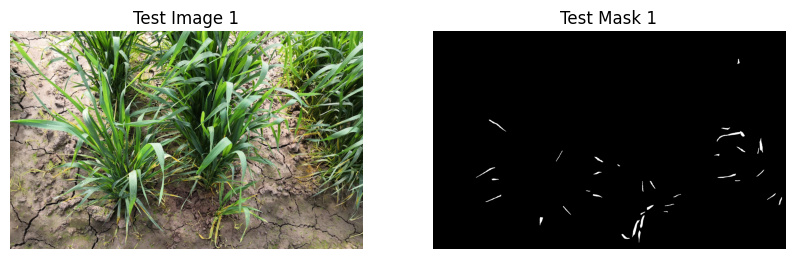

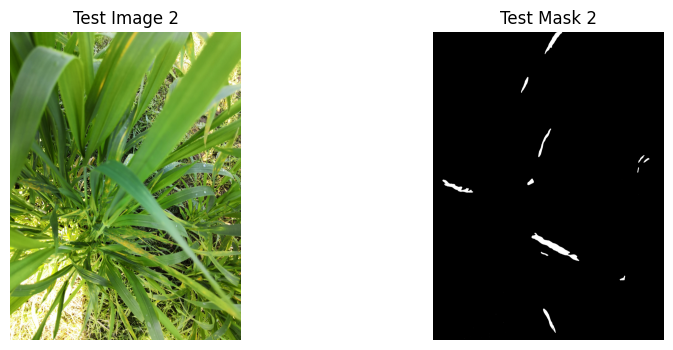

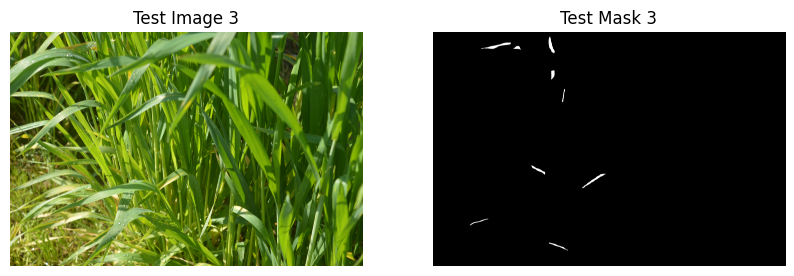

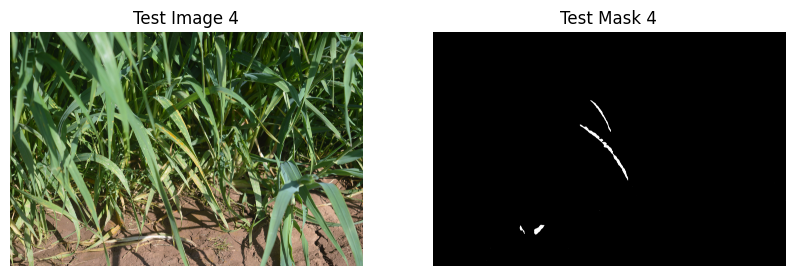

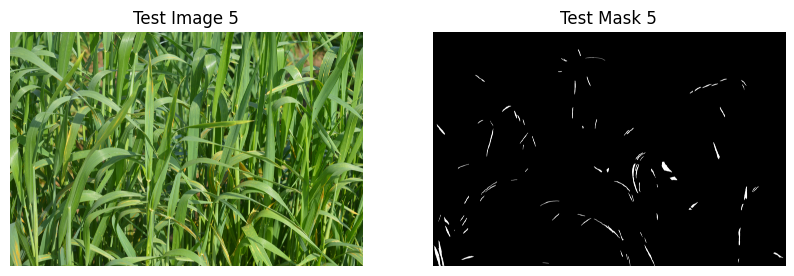

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Show first 5 test image-mask pairs
for i in range(min(5, len(nwrd_test_image_paths))):

    image = Image.open(nwrd_test_image_paths[i])
    mask = Image.open(nwrd_test_mask_paths[i])

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title(f"Test Image {i+1}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(mask, cmap="gray")
    plt.title(f"Test Mask {i+1}")
    plt.axis("off")

    plt.show()

# 26.2 — Test-set comparison

In [ ]:
import os
import tensorflow as tf

MODEL_DIR = "/content/drive/MyDrive/Agri-Vision/models"

print("Model directory exists:", os.path.exists(MODEL_DIR))

if os.path.exists(MODEL_DIR):
    print("\nSaved model files:")
    for f in os.listdir(MODEL_DIR):
        if f.endswith(".keras") or f.endswith(".h5"):
            print(" -", f)

Model directory exists: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print("Searching Google Drive for saved ML models...\n")

extensions = (".keras", ".h5", ".hdf5")

found = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(extensions):
            path = os.path.join(root, file)
            found.append(path)

if found:
    print("FOUND MODEL FILES:")
    print("=" * 70)
    for path in found:
        print(path)
else:
    print("NO .keras / .h5 MODEL FILES FOUND IN GOOGLE DRIVE")

Searching Google Drive for saved ML models...

FOUND MODEL FILES:
/content/drive/MyDrive/Agri-vision project/module2_checkpoints/best_model.keras
/content/drive/MyDrive/Agri-Vision/final_wheat_model_backend.keras
/content/drive/MyDrive/Agri-Vision/wheat_model_stage1.keras
/content/drive/MyDrive/Agri-Vision/best_wheat_finetuned_model.keras
/content/drive/MyDrive/Agri-Vision/final_wheat_model.keras
/content/drive/MyDrive/Agri-Vision/final_wheat_inference_model.keras
/content/drive/MyDrive/Agri-Vision/best_damage_segmentation_model.keras
/content/drive/MyDrive/Agri-Vision/best_nwrd_binary_segmentation_model.keras
/content/drive/MyDrive/Agri-Vision/best_nwrd_patch_segmentation_model.keras
/content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_stage1.keras
/content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_stage2.keras
/content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v2.keras
/content/drive/MyDrive/Agri-Vision/models/best_damage_segmentation_v3.

In [ ]:
import tensorflow as tf
import os

MODEL_DIR = "/content/drive/MyDrive/Agri-Vision/models"

V1_PATH = os.path.join(MODEL_DIR, "best_damage_segmentation_stage1.keras")
V2_PATH = os.path.join(MODEL_DIR, "best_damage_segmentation_v2.keras")
V3_PATH = os.path.join(MODEL_DIR, "best_damage_segmentation_v3.keras")

print("Loading V1...")
v1_model = tf.keras.models.load_model(V1_PATH, compile=False)

print("Loading V2...")
v2_model = tf.keras.models.load_model(V2_PATH, compile=False)

print("Loading V3...")
v3_model = tf.keras.models.load_model(V3_PATH, compile=False)

print("\nAll three models loaded successfully!")

print("V1 input:", v1_model.input_shape)
print("V2 input:", v2_model.input_shape)
print("V3 input:", v3_model.input_shape)

Loading V1...
Loading V2...
Loading V3...

All three models loaded successfully!
V1 input: (None, 512, 512, 3)
V2 input: (None, 512, 512, 3)
V3 input: (None, 512, 512, 3)


In [ ]:
# Check which important variables currently exist in this Colab runtime

variables_to_check = [
    "test_dataset_final",
    "test_dataset",
    "test_image_paths",
    "test_mask_paths",
    "val_dataset",
    "train_dataset",
    "IMG_SIZE",
]

for var in variables_to_check:
    print(f"{var}: {'FOUND' if var in globals() else 'NOT FOUND'}")

test_dataset_final: NOT FOUND
test_dataset: NOT FOUND
test_image_paths: NOT FOUND
test_mask_paths: NOT FOUND
val_dataset: NOT FOUND
train_dataset: NOT FOUND
IMG_SIZE: NOT FOUND


In [ ]:
from pathlib import Path

# Official NWRD test directories
NWRD_ROOT = Path("/content/drive/MyDrive/Agri-Vision/NWRD")

TEST_IMAGE_DIR = NWRD_ROOT / "test" / "images"
TEST_MASK_DIR = NWRD_ROOT / "test" / "masks"

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}

# Collect test images and masks
test_image_files = sorted([
    file
    for file in TEST_IMAGE_DIR.iterdir()
    if file.is_file()
    and file.suffix.lower() in IMAGE_EXTENSIONS
])

test_mask_files = sorted([
    file
    for file in TEST_MASK_DIR.iterdir()
    if file.is_file()
    and file.suffix.lower() in IMAGE_EXTENSIONS
])

# Match images and masks by filename stem
test_image_lookup = {
    file.stem: file
    for file in test_image_files
}

test_mask_lookup = {
    file.stem: file
    for file in test_mask_files
}

matched_test_stems = sorted(
    set(test_image_lookup)
    &
    set(test_mask_lookup)
)

test_pairs = [
    (
        test_image_lookup[stem],
        test_mask_lookup[stem]
    )
    for stem in matched_test_stems
]

print("===== OFFICIAL NWRD TEST SET =====")
print("Test images:", len(test_image_files))
print("Test masks :", len(test_mask_files))
print("Matched pairs:", len(test_pairs))

print("\nFirst few pairs:")
for image_path, mask_path in test_pairs[:5]:
    print("Image:", image_path.name)
    print("Mask :", mask_path.name)
    print()

===== OFFICIAL NWRD TEST SET =====
Test images: 10
Test masks : 10
Matched pairs: 10

First few pairs:
Image: 105.jpg
Mask : 105.png

Image: 123.jpg
Mask : 123.png

Image: 25.jpg
Mask : 25.png

Image: 29.jpg
Mask : 29.png

Image: 62.jpg
Mask : 62.png



In [ ]:
import os

print("Checking all 10 test image/mask paths...\n")

all_ok = True

for i, (image_path, mask_path) in enumerate(test_pairs, 1):
    image_exists = os.path.exists(str(image_path))
    mask_exists = os.path.exists(str(mask_path))

    print(
        f"{i:02d}. "
        f"{os.path.basename(str(image_path))} -> "
        f"Image: {'OK' if image_exists else 'MISSING'} | "
        f"Mask: {'OK' if mask_exists else 'MISSING'}"
    )

    if not image_exists or not mask_exists:
        all_ok = False
        print("    Image path:", image_path)
        print("    Mask path :", mask_path)

print("\n" + "=" * 60)

if all_ok:
    print("ALL TEST FILES EXIST.")
else:
    print("ONE OR MORE TEST FILES ARE MISSING.")

Checking all 10 test image/mask paths...

01. 105.jpg -> Image: OK | Mask: OK
02. 123.jpg -> Image: OK | Mask: OK
03. 25.jpg -> Image: OK | Mask: OK
04. 29.jpg -> Image: OK | Mask: OK
05. 62.jpg -> Image: OK | Mask: OK
06. 63.jpg -> Image: OK | Mask: OK
07. 67.jpg -> Image: OK | Mask: OK
08. 77.jpg -> Image: OK | Mask: OK
09. 80.jpg -> Image: OK | Mask: OK
10. 89.jpg -> Image: OK | Mask: OK

ALL TEST FILES EXIST.


In [ ]:
import tensorflow as tf
import numpy as np

IMG_SIZE = 512

def load_one_test_pair(image_path, mask_path):
    # Read image
    image_bytes = tf.io.read_file(str(image_path))
    image = tf.image.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0

    # Read mask
    mask_bytes = tf.io.read_file(str(mask_path))
    mask = tf.image.decode_png(mask_bytes, channels=1)
    mask = tf.image.resize(
        mask,
        [IMG_SIZE, IMG_SIZE],
        method="nearest"
    )
    mask = tf.cast(mask, tf.float32) / 255.0
    mask = tf.cast(mask > 0.5, tf.float32)

    return image, mask


# Test the first image-mask pair directly
image_path, mask_path = test_pairs[0]

print("Testing:")
print("Image:", image_path)
print("Mask :", mask_path)

sample_image, sample_mask = load_one_test_pair(
    image_path,
    mask_path
)

print("\nSUCCESS")
print("Image shape:", sample_image.shape)
print("Mask shape :", sample_mask.shape)
print("Image range:",
      float(tf.reduce_min(sample_image)),
      "to",
      float(tf.reduce_max(sample_image)))
print("Mask values:", np.unique(sample_mask.numpy()))

Testing:
Image: /content/drive/MyDrive/Agri-Vision/NWRD/test/images/105.jpg
Mask : /content/drive/MyDrive/Agri-Vision/NWRD/test/masks/105.png

SUCCESS
Image shape: (512, 512, 3)
Mask shape : (512, 512, 1)
Image range: 0.0 to 1.0
Mask values: [0. 1.]


In [ ]:
from PIL import Image

print("===== ORIGINAL NWRD TEST IMAGE SIZES =====")

for image_path, mask_path in test_pairs:
    image = Image.open(image_path)
    mask = Image.open(mask_path)

    print(
        f"{image_path.name}: "
        f"image={image.size}, "
        f"mask={mask.size}"
    )

===== ORIGINAL NWRD TEST IMAGE SIZES =====
105.jpg: image=(4604, 2844), mask=(4604, 2844)
123.jpg: image=(3456, 4608), mask=(3456, 4608)
25.jpg: image=(6016, 4000), mask=(6016, 4000)
29.jpg: image=(6016, 4000), mask=(6016, 4000)
62.jpg: image=(6016, 4000), mask=(6016, 4000)
63.jpg: image=(6016, 4000), mask=(6016, 4000)
67.jpg: image=(3456, 4608), mask=(3456, 4608)
77.jpg: image=(4608, 3456), mask=(4608, 3456)
80.jpg: image=(4608, 3456), mask=(4608, 3456)
89.jpg: image=(3456, 4608), mask=(3456, 4608)


In [ ]:
# Find the patch/evaluation settings currently defined in the notebook runtime

names_to_check = [
    "PATCH_SIZE",
    "STRIDE",
    "IMG_SIZE",
    "BATCH_SIZE",
    "THRESHOLDS",
    "V1_THRESHOLD",
    "V2_THRESHOLD",
    "V3_THRESHOLD"
]

for name in names_to_check:
    if name in globals():
        print(f"{name} =", globals()[name])
    else:
        print(f"{name} = NOT DEFINED")

PATCH_SIZE = NOT DEFINED
STRIDE = NOT DEFINED
IMG_SIZE = 512
BATCH_SIZE = NOT DEFINED
THRESHOLDS = {'V1': 0.45, 'V2': 0.125, 'V3': 0.375}
V1_THRESHOLD = NOT DEFINED
V2_THRESHOLD = NOT DEFINED
V3_THRESHOLD = NOT DEFINED


In [ ]:
# ============================================================
# AGRI-VISION FINAL OFFICIAL TEST EVALUATION
# V1 vs V2 vs V3
# ============================================================

import os
import gc
import numpy as np
import tensorflow as tf
from pathlib import Path
from PIL import Image

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

MODEL_DIR = Path(
    "/content/drive/MyDrive/Agri-Vision/models"
)

TEST_IMAGE_DIR = Path(
    "/content/drive/MyDrive/Agri-Vision/NWRD/test/images"
)

TEST_MASK_DIR = Path(
    "/content/drive/MyDrive/Agri-Vision/NWRD/test/masks"
)

V1_PATH = MODEL_DIR / "best_damage_segmentation_stage2.keras"
V2_PATH = MODEL_DIR / "best_damage_segmentation_v2.keras"
V3_PATH = MODEL_DIR / "best_damage_segmentation_v3.keras"

# ------------------------------------------------------------
# 2. Official settings recovered from notebook
# ------------------------------------------------------------

PATCH_SIZE = 512
STRIDE = 512

V1_THRESHOLD = 0.45
V2_THRESHOLD = 0.125
V3_THRESHOLD = 0.375

print("===== FINAL EVALUATION SETTINGS =====")
print("Patch size :", PATCH_SIZE)
print("Stride     :", STRIDE)
print("V1 threshold:", V1_THRESHOLD)
print("V2 threshold:", V2_THRESHOLD)
print("V3 threshold:", V3_THRESHOLD)

# ------------------------------------------------------------
# 3. Load correct models
# ------------------------------------------------------------

print("\nLoading V1...")
v1_model = tf.keras.models.load_model(
    V1_PATH,
    compile=False
)

print("Loading V2...")
v2_model = tf.keras.models.load_model(
    V2_PATH,
    compile=False
)

print("Loading V3...")
v3_model = tf.keras.models.load_model(
    V3_PATH,
    compile=False
)

print("\nAll three models loaded successfully.")

# ------------------------------------------------------------
# 4. Prepare official test pairs
# ------------------------------------------------------------

test_image_files = sorted([
    f for f in TEST_IMAGE_DIR.iterdir()
    if f.is_file()
])

test_mask_files = sorted([
    f for f in TEST_MASK_DIR.iterdir()
    if f.is_file()
])

image_lookup = {
    f.stem: f
    for f in test_image_files
}

mask_lookup = {
    f.stem: f
    for f in test_mask_files
}

test_stems = sorted(
    set(image_lookup) & set(mask_lookup)
)

test_pairs = [
    (
        image_lookup[stem],
        mask_lookup[stem]
    )
    for stem in test_stems
]

print("\n===== OFFICIAL NWRD TEST SET =====")
print("Images:", len(test_image_files))
print("Masks :", len(test_mask_files))
print("Pairs :", len(test_pairs))

# ------------------------------------------------------------
# 5. Patch position function
# ------------------------------------------------------------

def generate_positions(
    dimension,
    patch_size,
    stride
):

    if dimension <= patch_size:
        return [0]

    positions = list(
        range(
            0,
            dimension - patch_size + 1,
            stride
        )
    )

    final_position = (
        dimension - patch_size
    )

    if positions[-1] != final_position:
        positions.append(final_position)

    return positions


# ------------------------------------------------------------
# 6. Full-resolution prediction
# ------------------------------------------------------------

def predict_full_image(
    image_path,
    model,
    patch_size=512,
    stride=512
):

    with Image.open(image_path) as image:

        image_np = np.array(
            image.convert("RGB")
        )

    height, width, _ = image_np.shape

    y_positions = generate_positions(
        height,
        patch_size,
        stride
    )

    x_positions = generate_positions(
        width,
        patch_size,
        stride
    )

    probability_sum = np.zeros(
        (height, width),
        dtype=np.float32
    )

    prediction_count = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    for y in y_positions:

        for x in x_positions:

            patch = image_np[
                y:y + patch_size,
                x:x + patch_size
            ]

            patch = (
                patch.astype(np.float32)
                / 255.0
            )

            prediction = model(
                np.expand_dims(
                    patch,
                    axis=0
                ),
                training=False
            ).numpy()[0, :, :, 0]

            probability_sum[
                y:y + patch_size,
                x:x + patch_size
            ] += prediction

            prediction_count[
                y:y + patch_size,
                x:x + patch_size
            ] += 1

    probability_map = (
        probability_sum
        /
        np.maximum(
            prediction_count,
            1
        )
    )

    return probability_map


# ------------------------------------------------------------
# 7. Metrics
# ------------------------------------------------------------

def calculate_metrics(
    ground_truth,
    probability_map,
    threshold
):

    y_true = ground_truth > 0
    y_pred = probability_map >= threshold

    tp = np.logical_and(
        y_true,
        y_pred
    ).sum()

    tn = np.logical_and(
        np.logical_not(y_true),
        np.logical_not(y_pred)
    ).sum()

    fp = np.logical_and(
        np.logical_not(y_true),
        y_pred
    ).sum()

    fn = np.logical_and(
        y_true,
        np.logical_not(y_pred)
    ).sum()

    dice = (
        2 * tp /
        (2 * tp + fp + fn)
        if (2 * tp + fp + fn) > 0
        else 0
    )

    iou = (
        tp /
        (tp + fp + fn)
        if (tp + fp + fn) > 0
        else 0
    )

    precision = (
        tp /
        (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    recall = (
        tp /
        (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    pixel_accuracy = (
        (tp + tn) /
        (tp + tn + fp + fn)
    )

    actual_percentage = (
        np.count_nonzero(y_true)
        / y_true.size
    ) * 100

    predicted_percentage = (
        np.count_nonzero(y_pred)
        / y_pred.size
    ) * 100

    percentage_error = abs(
        actual_percentage
        - predicted_percentage
    )

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "pixel_accuracy": pixel_accuracy,
        "actual_percentage": actual_percentage,
        "predicted_percentage": predicted_percentage,
        "percentage_error": percentage_error
    }


# ------------------------------------------------------------
# 8. Evaluate V1, V2 and V3
# ------------------------------------------------------------

models = {
    "V1": (v1_model, V1_THRESHOLD),
    "V2": (v2_model, V2_THRESHOLD),
    "V3": (v3_model, V3_THRESHOLD)
}

all_results = {}

for model_name, (model, threshold) in models.items():

    print("\n")
    print("=" * 70)
    print(f"             {model_name} OFFICIAL TEST")
    print("=" * 70)

    results = []

    for index, (image_path, mask_path) in enumerate(
        test_pairs,
        start=1
    ):

        print(
            f"\n[{model_name}] "
            f"Processing {index}/{len(test_pairs)}: "
            f"{image_path.name}"
        )

        with Image.open(mask_path) as mask:

            ground_truth = np.array(
                mask.convert("L")
            )

        probability_map = predict_full_image(
            image_path,
            model,
            PATCH_SIZE,
            STRIDE
        )

        metrics = calculate_metrics(
            ground_truth,
            probability_map,
            threshold
        )

        metrics["image"] = image_path.name

        results.append(metrics)

        print(
            f"Dice      : {metrics['dice']:.4f}"
        )

        print(
            f"IoU       : {metrics['iou']:.4f}"
        )

        print(
            f"Precision : {metrics['precision']:.4f}"
        )

        print(
            f"Recall    : {metrics['recall']:.4f}"
        )

        print(
            f"Pixel Acc.: {metrics['pixel_accuracy']:.4f}"
        )

        print(
            f"Actual %  : "
            f"{metrics['actual_percentage']:.4f}"
        )

        print(
            f"Predicted %: "
            f"{metrics['predicted_percentage']:.4f}"
        )

        print(
            f"Area Error: "
            f"{metrics['percentage_error']:.4f}"
        )

        del probability_map
        del ground_truth

        gc.collect()

    all_results[model_name] = results


# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

print("\n\n")
print("=" * 85)
print("                 FINAL MODEL COMPARISON")
print("=" * 85)

summary = {}

for model_name, results in all_results.items():

    mean_dice = np.mean([
        r["dice"] for r in results
    ])

    mean_iou = np.mean([
        r["iou"] for r in results
    ])

    mean_precision = np.mean([
        r["precision"] for r in results
    ])

    mean_recall = np.mean([
        r["recall"] for r in results
    ])

    mean_pixel_accuracy = np.mean([
        r["pixel_accuracy"] for r in results
    ])

    mean_area_error = np.mean([
        r["percentage_error"] for r in results
    ])

    summary[model_name] = {
        "dice": mean_dice,
        "iou": mean_iou,
        "precision": mean_precision,
        "recall": mean_recall,
        "pixel_accuracy": mean_pixel_accuracy,
        "area_mae": mean_area_error
    }

    print(f"\n===== {model_name} =====")
    print(f"Mean Dice       : {mean_dice:.4f}")
    print(f"Mean IoU        : {mean_iou:.4f}")
    print(f"Mean Precision  : {mean_precision:.4f}")
    print(f"Mean Recall     : {mean_recall:.4f}")
    print(f"Mean Pixel Acc. : {mean_pixel_accuracy:.4f}")
    print(f"Area % MAE      : {mean_area_error:.4f} percentage points")

print("\n")
print("=" * 85)
print("Evaluation complete.")
print("=" * 85)

===== FINAL EVALUATION SETTINGS =====
Patch size : 512
Stride     : 512
V1 threshold: 0.45
V2 threshold: 0.125
V3 threshold: 0.375

Loading V1...
Loading V2...
Loading V3...

All three models loaded successfully.

===== OFFICIAL NWRD TEST SET =====
Images: 10
Masks : 10
Pairs : 10


             V1 OFFICIAL TEST

[V1] Processing 1/10: 105.jpg
Dice      : 0.4810
IoU       : 0.3167
Precision : 0.6195
Recall    : 0.3931
Pixel Acc.: 0.9951
Actual %  : 0.5726
Predicted %: 0.3633
Area Error: 0.2093

[V1] Processing 2/10: 123.jpg
Dice      : 0.6190
IoU       : 0.4482
Precision : 0.6157
Recall    : 0.6223
Pixel Acc.: 0.9925
Actual %  : 0.9725
Predicted %: 0.9828
Area Error: 0.0103

[V1] Processing 3/10: 25.jpg
Dice      : 0.5087
IoU       : 0.3411
Precision : 0.4174
Recall    : 0.6511
Pixel Acc.: 0.9960
Actual %  : 0.3167
Predicted %: 0.4939
Area Error: 0.1772

[V1] Processing 4/10: 29.jpg
Dice      : 0.6255
IoU       : 0.4551
Precision : 0.5746
Recall    : 0.6863
Pixel Acc.: 0.9971
Actual %  

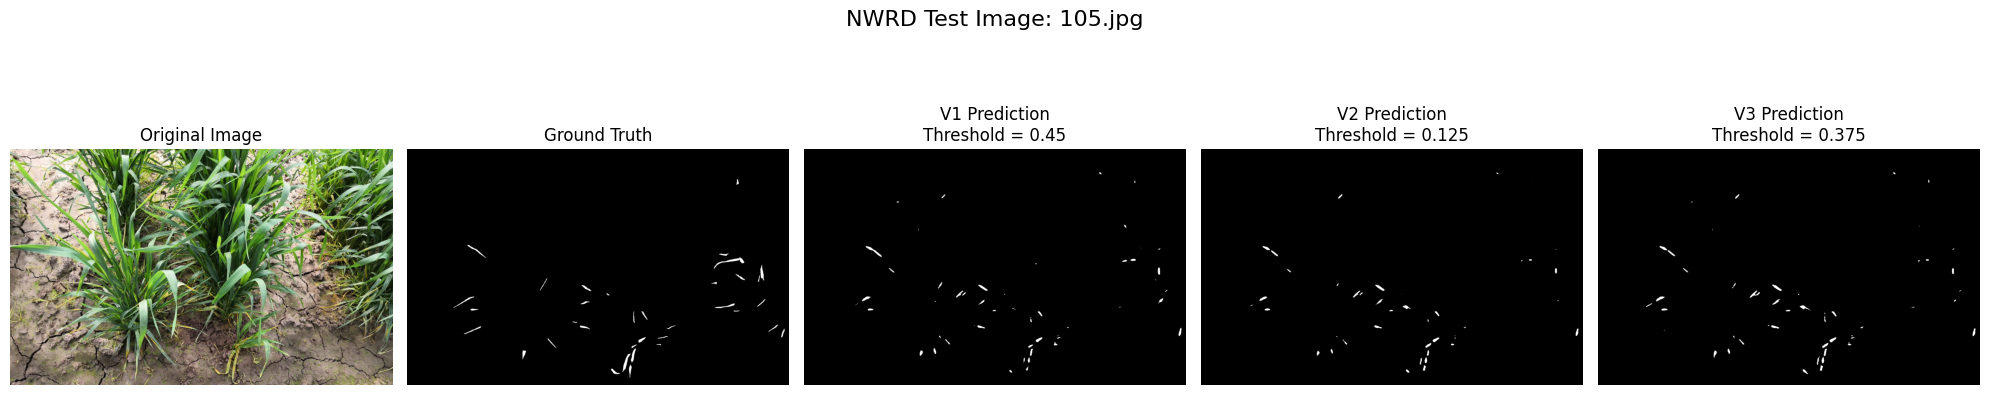

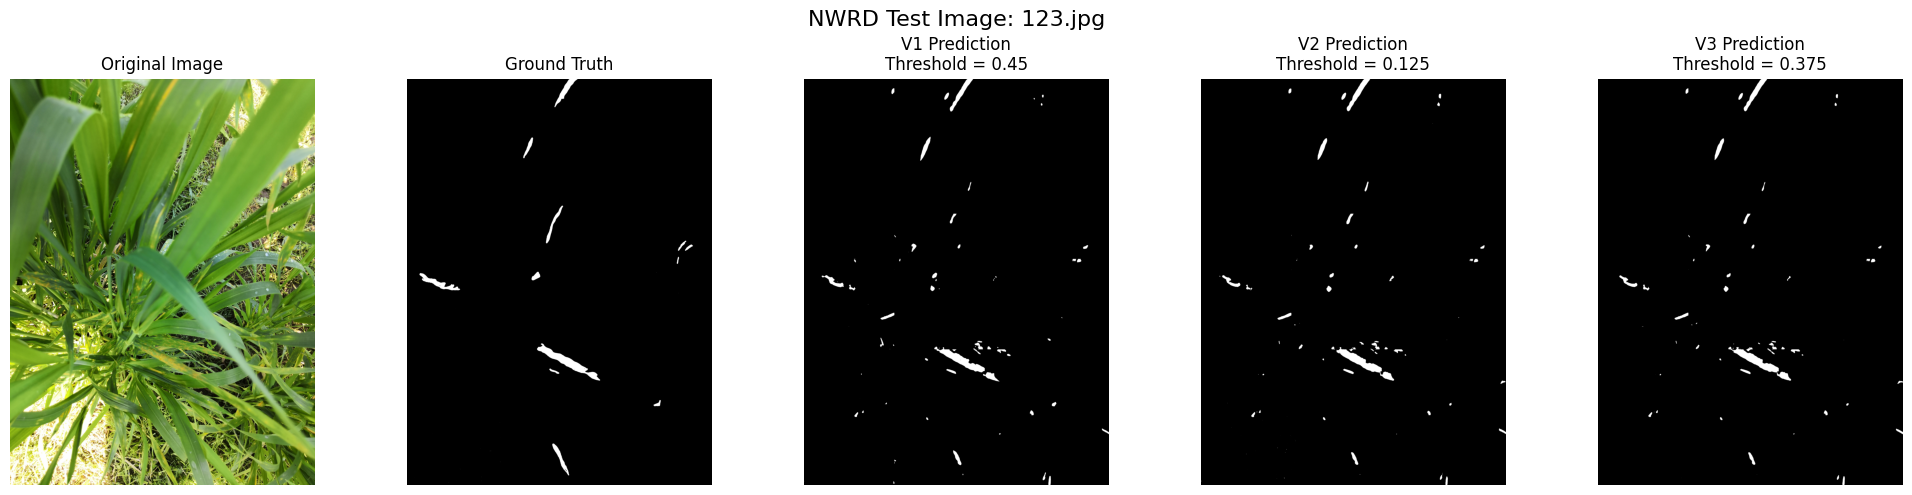

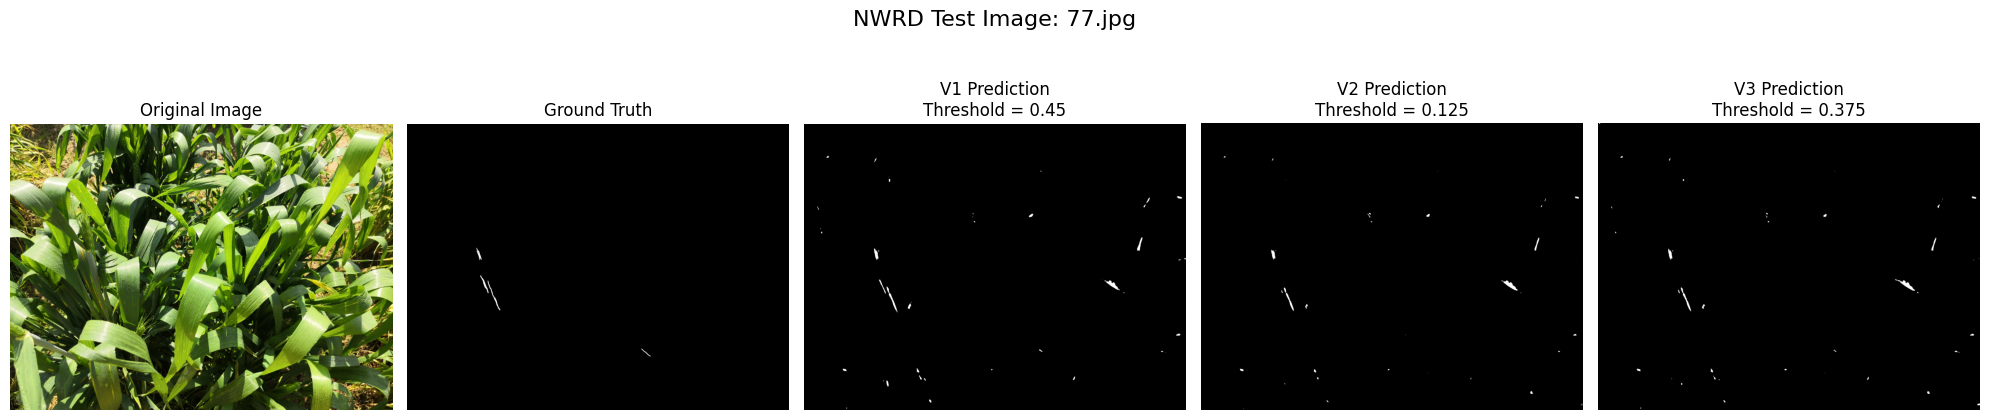

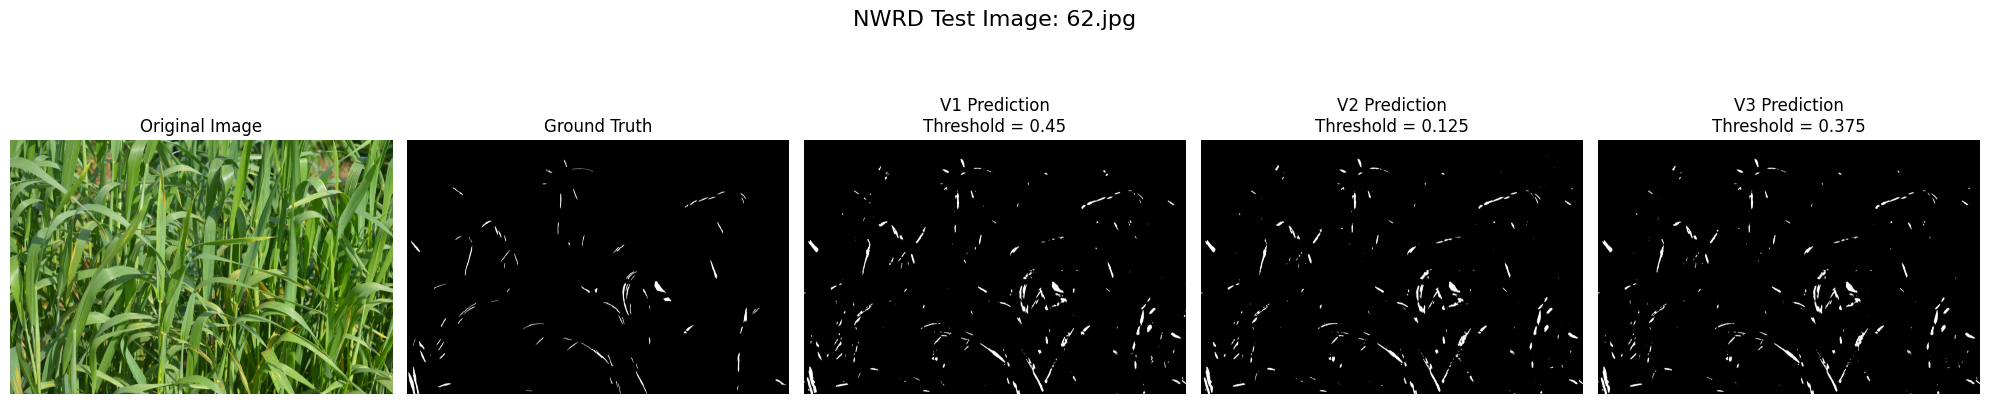

In [ ]:
# ============================================================
# QUALITATIVE COMPARISON
# Original | Ground Truth | V1 | V2 | V3
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pathlib import Path

# Select representative test images
QUALITATIVE_IMAGES = [
    "105.jpg",
    "123.jpg",
    "77.jpg",
    "62.jpg"
]

# ------------------------------------------------------------
# Generate comparison figures
# ------------------------------------------------------------

for image_name in QUALITATIVE_IMAGES:

    image_path = TEST_IMAGE_DIR / image_name
    mask_path = TEST_MASK_DIR / (
        Path(image_name).stem + ".png"
    )

    # Original image
    image = np.array(
        Image.open(image_path).convert("RGB")
    )

    # Ground truth
    ground_truth = (
        np.array(
            Image.open(mask_path).convert("L")
        ) > 0
    )

    # Predictions
    v1_probability = predict_full_image(
        image_path,
        v1_model,
        PATCH_SIZE,
        STRIDE
    )

    v2_probability = predict_full_image(
        image_path,
        v2_model,
        PATCH_SIZE,
        STRIDE
    )

    v3_probability = predict_full_image(
        image_path,
        v3_model,
        PATCH_SIZE,
        STRIDE
    )

    v1_prediction = (
        v1_probability >= V1_THRESHOLD
    )

    v2_prediction = (
        v2_probability >= V2_THRESHOLD
    )

    v3_prediction = (
        v3_probability >= V3_THRESHOLD
    )

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        5,
        figsize=(20, 5)
    )

    axes[0].imshow(image)
    axes[0].set_title("Original Image")

    axes[1].imshow(
        ground_truth,
        cmap="gray"
    )
    axes[1].set_title("Ground Truth")

    axes[2].imshow(
        v1_prediction,
        cmap="gray"
    )
    axes[2].set_title(
        f"V1 Prediction\nThreshold = {V1_THRESHOLD}"
    )

    axes[3].imshow(
        v2_prediction,
        cmap="gray"
    )
    axes[3].set_title(
        f"V2 Prediction\nThreshold = {V2_THRESHOLD}"
    )

    axes[4].imshow(
        v3_prediction,
        cmap="gray"
    )
    axes[4].set_title(
        f"V3 Prediction\nThreshold = {V3_THRESHOLD}"
    )

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"NWRD Test Image: {image_name}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

    # Free memory
    del v1_probability
    del v2_probability
    del v3_probability

In [ ]:
import pandas as pd

metrics = {
    "Version": ["V1", "V2", "V3"],

    "Dice": [
        0.5190,
        0.5111,
        0.5150
    ],

    "IoU": [
        0.3545,
        0.3485,
        0.3521
    ],

    "Precision": [
        0.4725,
        0.4694,
        0.4688
    ],

    "Recall": [
        0.6209,
        0.5971,
        0.6030
    ],

    "Pixel Accuracy": [
        0.9935,
        0.9935,
        0.9936
    ],

    "Area % MAE": [
        0.2587,
        0.2561,
        0.2393
    ]
}

df_metrics = pd.DataFrame(metrics)

df_metrics

,Version,Dice,IoU,Precision,Recall,Pixel Accuracy,Area % MAE
0,V1,0.5190,0.3545,0.4725,0.6209,0.9935,0.2587
1,V2,0.5111,0.3485,0.4694,0.5971,0.9935,0.2561
2,V3,0.5150,0.3521,0.4688,0.6030,0.9936,0.2393


In [ ]:
import pandas as pd

metrics = {
    "Version": ["V1", "V2", "V3"],

    "Dice": [
        0.5190,
        0.5111,
        0.5150
    ],

    "IoU": [
        0.3545,
        0.3485,
        0.3521
    ],

    "Precision": [
        0.4725,
        0.4694,
        0.4688
    ],

    "Recall": [
        0.6209,
        0.5971,
        0.6030
    ],

    "Pixel Accuracy": [
        0.9935,
        0.9935,
        0.9936
    ],

    "Area % MAE": [
        0.2587,
        0.2561,
        0.2393
    ]
}

df_metrics = pd.DataFrame(metrics)

df_metrics

,Version,Dice,IoU,Precision,Recall,Pixel Accuracy,Area % MAE
0,V1,0.5190,0.3545,0.4725,0.6209,0.9935,0.2587
1,V2,0.5111,0.3485,0.4694,0.5971,0.9935,0.2561
2,V3,0.5150,0.3521,0.4688,0.6030,0.9936,0.2393


In [ ]:
higher_is_better = [
    "Dice",
    "IoU",
    "Precision",
    "Recall",
    "Pixel Accuracy"
]

lower_is_better = [
    "Area % MAE"
]

print("BEST VERSION FOR EACH METRIC")
print("=" * 45)

for metric in higher_is_better:
    best_index = df_metrics[metric].idxmax()
    best_version = df_metrics.loc[best_index, "Version"]
    best_value = df_metrics.loc[best_index, metric]

    print(f"{metric:<20} : {best_version} ({best_value:.4f})")

for metric in lower_is_better:
    best_index = df_metrics[metric].idxmin()
    best_version = df_metrics.loc[best_index, "Version"]
    best_value = df_metrics.loc[best_index, metric]

    print(f"{metric:<20} : {best_version} ({best_value:.4f})")

BEST VERSION FOR EACH METRIC
Dice                 : V1 (0.5190)
IoU                  : V1 (0.3545)
Precision            : V1 (0.4725)
Recall               : V1 (0.6209)
Pixel Accuracy       : V3 (0.9936)
Area % MAE           : V3 (0.2393)


In [ ]:
primary_metrics = [
    "Dice",
    "IoU",
    "Precision",
    "Recall"
]

df_metrics["Overall Segmentation Score"] = (
    df_metrics[primary_metrics].mean(axis=1)
)

print(df_metrics[
    ["Version", "Overall Segmentation Score"]
].sort_values(
    "Overall Segmentation Score",
    ascending=False
))

  Version  Overall Segmentation Score
0      V1                    0.491725
2      V3                    0.484725
1      V2                    0.481525


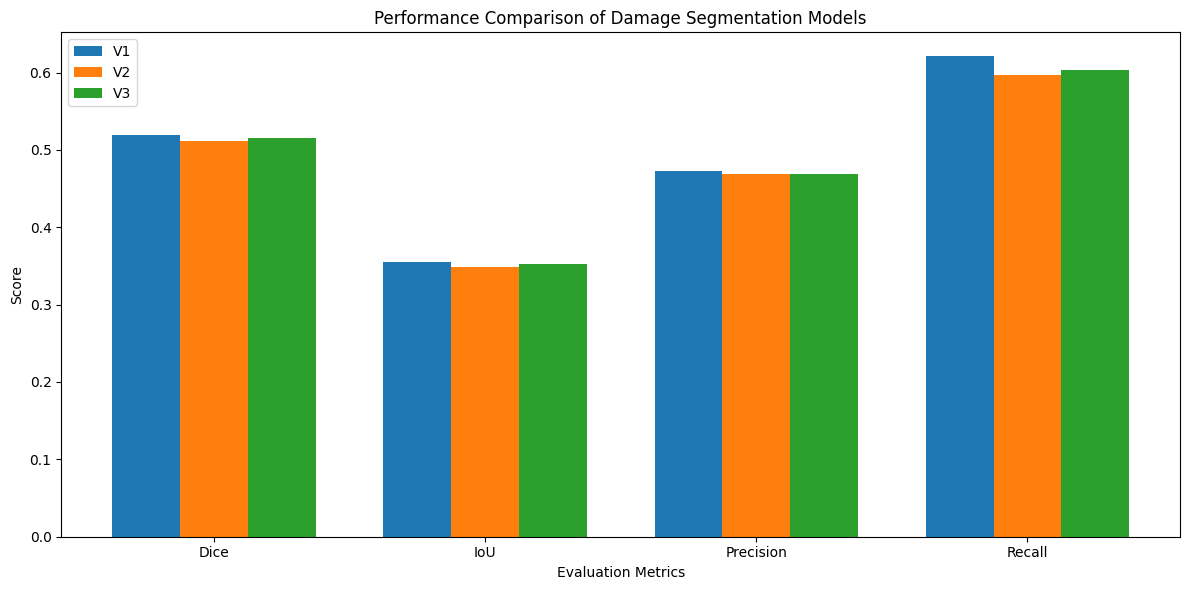

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics_to_plot = [
    "Dice",
    "IoU",
    "Precision",
    "Recall"
]

versions = df_metrics["Version"].values

x = np.arange(len(metrics_to_plot))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

for i, version in enumerate(versions):
    values = df_metrics.loc[
        df_metrics["Version"] == version,
        metrics_to_plot
    ].values[0]

    ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=version
    )

ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Score")
ax.set_title("Performance Comparison of Damage Segmentation Models")
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot)
ax.legend()

plt.tight_layout()
plt.show()